# Từ hai nghiên cứu trước đến ba câu hỏi của khóa luận

Một hệ thống học tập thích ứng phải chọn **bài nào tiếp theo** từ những gì người học đã làm. Hệ thống cần một mô hình ước lượng người học đang biết gì; một bản đồ các kiến thức nền; và một quy tắc chọn bài. Đồ thị tiên quyết là bản đồ ấy. Có bản đồ tốt chưa bảo đảm chọn bài tốt, và đi theo một lộ trình liền mạch hơn chưa bảo đảm học được nhiều hơn.

Paper 1 đã phân biệt vai trò của bản đồ với vai trò của cách chọn đường đi: ưu tiên học liên tục trong chương giúp giảm chuyển chương, nhưng đồ thị mở rộng chưa cải thiện ổn định mức thành thạo. Paper 2 tiếp tục cho thấy dự báo có thể nhỉnh hơn trên cùng câu hỏi nhưng chưa phát hiện cải thiện rõ ở kết quả học trong mô phỏng; bước chọn cấu hình trên Junyi còn ưu tiên tắt thông tin đồ thị. Những nhận định này **đã có trong hai paper**, không phải phát hiện lần đầu của khóa luận.

Từ khoảng trống đó, đề cương đặt ba câu hỏi: **RQ1 — vì sao đồ thị chưa giúp ổn định? RQ2 — điều kiện nào làm nó có ích hoặc bất lợi? RQ3 — có thể dùng các quan hệ chưa chắc chắn một cách thận trọng hơn không?** Các số RQ này thuộc KLTN; hai paper có hệ đánh số RQ riêng.

Notebook đi theo mạch đó. Mỗi phần giải thích mục đích và cách so sánh trước, rồi mới đến số liệu. Các mục “Thiết kế và hồ sơ kiểm chứng” có thể mở để xem thao tác, mã, log và giới hạn. K1–K6 là mã tra cứu nội bộ, không phải sáu câu hỏi nghiên cứu mới.

**Cách chạy:** Colab CPU → Runtime → Run all. File tự chứa kết quả tổng hợp và outputs sẵn; các cell chỉ dựng lại bảng/biểu đồ, không tự training, tải dataset hay chạy lại thí nghiệm gốc. Để tái lập nghiên cứu gốc vẫn cần đúng mã, đầu vào và điều kiện chạy được dẫn bên dưới. Chưa kiểm trực tiếp giao diện/runtime Colab.

**Nguồn đã đối chiếu đúng bản user gửi:** [đề cương, trang 1–4](../../../../paper2/DC%20KLTN0127%2023520355%2623521338_LeVanTuan.pdf), [Paper 1, trang 1 và 4–5](../../../../paper1/Paper1_RIVF_2026_Graph_vs_Policy_Adaptive_Sequencing.pdf), [Paper 2, trang 1 và 4–6](../../../../paper2/Paper2_RIVF_2026_Prerequisite_Aware_Knowledge_Tracing.pdf). Các bản repository giống từng byte với PDF user chỉ định; nguồn và SHA ở cuối file. Đọc cùng [báo cáo tiến độ](BAO_CAO.md).


In [1]:
#@title Nạp dữ liệu kết quả đã lưu (không training)
import json, hashlib, math
from html import escape

EMBEDDED_JSON = '{"as_of":"2026-11-08","kind":"SELF_CONTAINED_EXPERIMENT_PROCESS_AND_CACHED_RESULTS_NOT_REEXECUTION","preserved_previous_notebook_sha256":"0f2130aba7b04a187b31ac9c0fd9d4b81df290ced470e5aa04bbf92625267620","previous_repository_notebook_unchanged":{"notebooks/thesis_evidence_report.ipynb":"ed1b7cad329d453d535a233ac8effdf4abf7a22d030a011962f9f04486ef090c","scripts/research/build_thesis_evidence_notebook.py":"5f49bb44138087ebd2d783fa6d8bca7d1ec028bcc970ebde2cfd3e0500b94952"},"records":[{"id":"fixed_groups","json_pointer":"/groups","source_path":"research_tracking/runs/rq1-fixed-edge-set-contrast-20261108-01/summary.json","source_sha256":"bd9781570ec034aea5297dd63b1bef0075cfba5c5ee0a057c8df1887c27026f6","value":[{"Brier_full_minus_empty":-0.000338675650001518,"LL_full_minus_empty":-0.0006369740725551903,"M_concept_crossings":90,"M_event_changed":90,"P_changed":963,"P_preview_table":[{"P_changed":false,"conditional_denominator":117,"count":115,"full_preview_changed":false},{"P_changed":false,"conditional_denominator":117,"count":2,"full_preview_changed":true},{"P_changed":true,"conditional_denominator":963,"count":943,"full_preview_changed":false},{"P_changed":true,"conditional_denominator":963,"count":20,"full_preview_changed":true}],"R_event_changed":60,"R_membership_symmetric_difference":80,"S_concept_pairs_changed":27000,"S_event_changed":1080,"baseline_cancellation":{"Brier_empty_minus_GF":-2.603062847973973e-05,"Brier_full_minus_GF":-0.0003647062784812577,"Brier_residual":0.0,"LL_empty_minus_GF":-5.659552492252744e-05,"LL_full_minus_GF":-0.0006935695974777178,"LL_residual":-1.0842021724855044e-19},"concept_mastery_decisions":30240,"concept_score_pairs":30240,"full_preview_tuple_changed":22,"group":"pooled","mean_R_jaccard":0.9876675485008819,"mean_absolute_delta_P":0.004825299330669877,"mean_absolute_delta_S":0.005251146328046196,"paired_snapshot_targets":1080,"paired_supported_prediction_targets":1080,"preview_concept_changed":22,"preview_difficulty_changed":0,"preview_question_changed":22,"preview_tuples":1080},{"Brier_full_minus_empty":0.001141404306696237,"LL_full_minus_empty":0.002499076326639072,"M_concept_crossings":86,"M_event_changed":86,"P_changed":321,"P_preview_table":[{"P_changed":false,"conditional_denominator":39,"count":38,"full_preview_changed":false},{"P_changed":false,"conditional_denominator":39,"count":1,"full_preview_changed":true},{"P_changed":true,"conditional_denominator":321,"count":302,"full_preview_changed":false},{"P_changed":true,"conditional_denominator":321,"count":19,"full_preview_changed":true}],"R_event_changed":56,"R_membership_symmetric_difference":76,"S_concept_pairs_changed":9000,"S_event_changed":360,"baseline_cancellation":{"Brier_empty_minus_GF":2.380402420945039e-05,"Brier_full_minus_GF":0.0011652083309056874,"Brier_residual":2.168404344971009e-19,"LL_empty_minus_GF":5.937782023189333e-05,"LL_full_minus_GF":0.0025584541468709654,"LL_residual":0.0},"concept_mastery_decisions":10080,"concept_score_pairs":10080,"full_preview_tuple_changed":20,"group":"profile:PG","mean_R_jaccard":0.9648544973544974,"mean_absolute_delta_P":0.0032840885650827793,"mean_absolute_delta_S":0.0035503241617728925,"paired_snapshot_targets":360,"paired_supported_prediction_targets":360,"preview_concept_changed":20,"preview_difficulty_changed":0,"preview_question_changed":20,"preview_tuples":360},{"Brier_full_minus_empty":-0.0013864878846595828,"LL_full_minus_empty":-0.002855036943681787,"M_concept_crossings":0,"M_event_changed":0,"P_changed":321,"P_preview_table":[{"P_changed":false,"conditional_denominator":39,"count":38,"full_preview_changed":false},{"P_changed":false,"conditional_denominator":39,"count":1,"full_preview_changed":true},{"P_changed":true,"conditional_denominator":321,"count":320,"full_preview_changed":false},{"P_changed":true,"conditional_denominator":321,"count":1,"full_preview_changed":true}],"R_event_changed":0,"R_membership_symmetric_difference":0,"S_concept_pairs_changed":9000,"S_event_changed":360,"baseline_cancellation":{"Brier_empty_minus_GF":-6.400934598214893e-05,"Brier_full_minus_GF":-0.0014504972306417317,"Brier_residual":0.0,"LL_empty_minus_GF":-0.00014338504275051536,"LL_full_minus_GF":-0.002998421986432302,"LL_residual":4.336808689942018e-19},"concept_mastery_decisions":10080,"concept_score_pairs":10080,"full_preview_tuple_changed":2,"group":"profile:PY","mean_R_jaccard":1.0,"mean_absolute_delta_P":0.0056714870895386085,"mean_absolute_delta_S":0.006316359458929047,"paired_snapshot_targets":360,"paired_supported_prediction_targets":360,"preview_concept_changed":2,"preview_difficulty_changed":0,"preview_question_changed":2,"preview_tuples":360},{"Brier_full_minus_empty":-0.0007709433720412082,"LL_full_minus_empty":-0.0015549616006228565,"M_concept_crossings":4,"M_event_changed":4,"P_changed":321,"P_preview_table":[{"P_changed":false,"conditional_denominator":39,"count":39,"full_preview_changed":false},{"P_changed":false,"conditional_denominator":39,"count":0,"full_preview_changed":true},{"P_changed":true,"conditional_denominator":321,"count":321,"full_preview_changed":false},{"P_changed":true,"conditional_denominator":321,"count":0,"full_preview_changed":true}],"R_event_changed":4,"R_membership_symmetric_difference":4,"S_concept_pairs_changed":9000,"S_event_changed":360,"baseline_cancellation":{"Brier_empty_minus_GF":-3.788656366652065e-05,"Brier_full_minus_GF":-0.0008088299357077288,"Brier_residual":1.0842021724855044e-19,"LL_empty_minus_GF":-8.577935224896027e-05,"LL_full_minus_GF":-0.0016407409528718167,"LL_residual":0.0},"concept_mastery_decisions":10080,"concept_score_pairs":10080,"full_preview_tuple_changed":0,"group":"profile:PYH","mean_R_jaccard":0.9981481481481481,"mean_absolute_delta_P":0.005520322337388243,"mean_absolute_delta_S":0.0058867553634366476,"paired_snapshot_targets":360,"paired_supported_prediction_targets":360,"preview_concept_changed":0,"preview_difficulty_changed":0,"preview_question_changed":0,"preview_tuples":360},{"Brier_full_minus_empty":-0.0004627980498039875,"LL_full_minus_empty":-0.0009320088573473123,"M_concept_crossings":0,"M_event_changed":0,"P_changed":312,"P_preview_table":[{"P_changed":false,"conditional_denominator":48,"count":48,"full_preview_changed":false},{"P_changed":false,"conditional_denominator":48,"count":0,"full_preview_changed":true},{"P_changed":true,"conditional_denominator":312,"count":312,"full_preview_changed":false},{"P_changed":true,"conditional_denominator":312,"count":0,"full_preview_changed":true}],"R_event_changed":0,"R_membership_symmetric_difference":0,"S_concept_pairs_changed":9000,"S_event_changed":360,"baseline_cancellation":{"Brier_empty_minus_GF":1.9554930893873968e-05,"Brier_full_minus_GF":-0.0004432431189101135,"Brier_residual":5.421010862427522e-20,"LL_empty_minus_GF":4.32849530177953e-05,"LL_full_minus_GF":-0.000888723904329517,"LL_residual":0.0},"concept_mastery_decisions":10080,"concept_score_pairs":10080,"full_preview_tuple_changed":0,"group":"seed:20000","mean_R_jaccard":1.0,"mean_absolute_delta_P":0.004983170869072622,"mean_absolute_delta_S":0.0055113609397625775,"paired_snapshot_targets":360,"paired_supported_prediction_targets":360,"preview_concept_changed":0,"preview_difficulty_changed":0,"preview_question_changed":0,"preview_tuples":360},{"Brier_full_minus_empty":-0.00028379752725596184,"LL_full_minus_empty":-0.0005507583593320181,"M_concept_crossings":18,"M_event_changed":18,"P_changed":324,"P_preview_table":[{"P_changed":false,"conditional_denominator":36,"count":35,"full_preview_changed":false},{"P_changed":false,"conditional_denominator":36,"count":1,"full_preview_changed":true},{"P_changed":true,"conditional_denominator":324,"count":308,"full_preview_changed":false},{"P_changed":true,"conditional_denominator":324,"count":16,"full_preview_changed":true}],"R_event_changed":0,"R_membership_symmetric_difference":0,"S_concept_pairs_changed":9000,"S_event_changed":360,"baseline_cancellation":{"Brier_empty_minus_GF":-7.757106103503841e-05,"Brier_full_minus_GF":-0.0003613685882910002,"Brier_residual":5.421010862427522e-20,"LL_empty_minus_GF":-0.0001685519618642609,"LL_full_minus_GF":-0.000719310321196279,"LL_residual":-1.0842021724855044e-19},"concept_mastery_decisions":10080,"concept_score_pairs":10080,"full_preview_tuple_changed":17,"group":"seed:20001","mean_R_jaccard":1.0,"mean_absolute_delta_P":0.00421369639589231,"mean_absolute_delta_S":0.004988103654620475,"paired_snapshot_targets":360,"paired_supported_prediction_targets":360,"preview_concept_changed":17,"preview_difficulty_changed":0,"preview_question_changed":17,"preview_tuples":360},{"Brier_full_minus_empty":-0.0002694313729446046,"LL_full_minus_empty":-0.00042815500098624054,"M_concept_crossings":72,"M_event_changed":72,"P_changed":327,"P_preview_table":[{"P_changed":false,"conditional_denominator":33,"count":32,"full_preview_changed":false},{"P_changed":false,"conditional_denominator":33,"count":1,"full_preview_changed":true},{"P_changed":true,"conditional_denominator":327,"count":323,"full_preview_changed":false},{"P_changed":true,"conditional_denominator":327,"count":4,"full_preview_changed":true}],"R_event_changed":60,"R_membership_symmetric_difference":80,"S_concept_pairs_changed":9000,"S_event_changed":360,"baseline_cancellation":{"Brier_empty_minus_GF":-2.0075755298054745e-05,"Brier_full_minus_GF":-0.0002895071282426594,"Brier_residual":0.0,"LL_empty_minus_GF":-4.451956592111672e-05,"LL_full_minus_GF":-0.00047267456690735723,"LL_residual":5.421010862427522e-20},"concept_mastery_decisions":10080,"concept_score_pairs":10080,"full_preview_tuple_changed":5,"group":"seed:20002","mean_R_jaccard":0.9630026455026455,"mean_absolute_delta_P":0.0052790307270446975,"mean_absolute_delta_S":0.005253974389755534,"paired_snapshot_targets":360,"paired_supported_prediction_targets":360,"preview_concept_changed":5,"preview_difficulty_changed":0,"preview_question_changed":5,"preview_tuples":360},{"Brier_full_minus_empty":0.0009543993091092832,"LL_full_minus_empty":0.002065646410303789,"M_concept_crossings":0,"M_event_changed":0,"P_changed":104,"P_preview_table":[{"P_changed":false,"conditional_denominator":16,"count":16,"full_preview_changed":false},{"P_changed":false,"conditional_denominator":16,"count":0,"full_preview_changed":true},{"P_changed":true,"conditional_denominator":104,"count":104,"full_preview_changed":false},{"P_changed":true,"conditional_denominator":104,"count":0,"full_preview_changed":true}],"R_event_changed":0,"R_membership_symmetric_difference":0,"S_concept_pairs_changed":3000,"S_event_changed":120,"baseline_cancellation":{"Brier_empty_minus_GF":1.014750116010756e-05,"Brier_full_minus_GF":0.0009645468102693907,"Brier_residual":0.0,"LL_empty_minus_GF":2.449060468035641e-05,"LL_full_minus_GF":0.0020901370149841456,"LL_residual":0.0},"concept_mastery_decisions":3360,"concept_score_pairs":3360,"full_preview_tuple_changed":0,"group":"trajectory:20000:PG","mean_R_jaccard":1.0,"mean_absolute_delta_P":0.0031759768127022398,"mean_absolute_delta_S":0.003607902493365205,"paired_snapshot_targets":120,"paired_supported_prediction_targets":120,"preview_concept_changed":0,"preview_difficulty_changed":0,"preview_question_changed":0,"preview_tuples":120},{"Brier_full_minus_empty":-0.0017021365734340792,"LL_full_minus_empty":-0.0035540476975547833,"M_concept_crossings":0,"M_event_changed":0,"P_changed":104,"P_preview_table":[{"P_changed":false,"conditional_denominator":16,"count":16,"full_preview_changed":false},{"P_changed":false,"conditional_denominator":16,"count":0,"full_preview_changed":true},{"P_changed":true,"conditional_denominator":104,"count":104,"full_preview_changed":false},{"P_changed":true,"conditional_denominator":104,"count":0,"full_preview_changed":true}],"R_event_changed":0,"R_membership_symmetric_difference":0,"S_concept_pairs_changed":3000,"S_event_changed":120,"baseline_cancellation":{"Brier_empty_minus_GF":0.0,"Brier_full_minus_GF":-0.0017021365734340792,"Brier_residual":0.0,"LL_empty_minus_GF":0.0,"LL_full_minus_GF":-0.0035540476975547833,"LL_residual":0.0},"concept_mastery_decisions":3360,"concept_score_pairs":3360,"full_preview_tuple_changed":0,"group":"trajectory:20000:PY","mean_R_jaccard":1.0,"mean_absolute_delta_P":0.006038442649675044,"mean_absolute_delta_S":0.006657112227803876,"paired_snapshot_targets":120,"paired_supported_prediction_targets":120,"preview_concept_changed":0,"preview_difficulty_changed":0,"preview_question_changed":0,"preview_tuples":120},{"Brier_full_minus_empty":-0.0006406568850871664,"LL_full_minus_empty":-0.001307625284790943,"M_concept_crossings":0,"M_event_changed":0,"P_changed":104,"P_preview_table":[{"P_changed":false,"conditional_denominator":16,"count":16,"full_preview_changed":false},{"P_changed":false,"conditional_denominator":16,"count":0,"full_preview_changed":true},{"P_changed":true,"conditional_denominator":104,"count":104,"full_preview_changed":false},{"P_changed":true,"conditional_denominator":104,"count":0,"full_preview_changed":true}],"R_event_changed":0,"R_membership_symmetric_difference":0,"S_concept_pairs_changed":3000,"S_event_changed":120,"baseline_cancellation":{"Brier_empty_minus_GF":4.851729152151434e-05,"Brier_full_minus_GF":-0.000592139593565652,"Brier_residual":0.0,"LL_empty_minus_GF":0.0001053642543730295,"LL_full_minus_GF":-0.0012022610304179135,"LL_residual":0.0},"concept_mastery_decisions":3360,"concept_score_pairs":3360,"full_preview_tuple_changed":0,"group":"trajectory:20000:PYH","mean_R_jaccard":1.0,"mean_absolute_delta_P":0.005735093144840582,"mean_absolute_delta_S":0.006269068098118651,"paired_snapshot_targets":120,"paired_supported_prediction_targets":120,"preview_concept_changed":0,"preview_difficulty_changed":0,"preview_question_changed":0,"preview_tuples":120},{"Brier_full_minus_empty":0.0009039811605761077,"LL_full_minus_empty":0.001980328486187861,"M_concept_crossings":18,"M_event_changed":18,"P_changed":108,"P_preview_table":[{"P_changed":false,"conditional_denominator":12,"count":12,"full_preview_changed":false},{"P_changed":false,"conditional_denominator":12,"count":0,"full_preview_changed":true},{"P_changed":true,"conditional_denominator":108,"count":93,"full_preview_changed":false},{"P_changed":true,"conditional_denominator":108,"count":15,"full_preview_changed":true}],"R_event_changed":0,"R_membership_symmetric_difference":0,"S_concept_pairs_changed":3000,"S_event_changed":120,"baseline_cancellation":{"Brier_empty_minus_GF":2.5359418608091274e-05,"Brier_full_minus_GF":0.000929340579184199,"Brier_residual":0.0,"LL_empty_minus_GF":6.0810731170680976e-05,"LL_full_minus_GF":0.002041139217358542,"LL_residual":0.0},"concept_mastery_decisions":3360,"concept_score_pairs":3360,"full_preview_tuple_changed":15,"group":"trajectory:20001:PG","mean_R_jaccard":1.0,"mean_absolute_delta_P":0.0032087416043460413,"mean_absolute_delta_S":0.00344426418999664,"paired_snapshot_targets":120,"paired_supported_prediction_targets":120,"preview_concept_changed":15,"preview_difficulty_changed":0,"preview_question_changed":15,"preview_tuples":120},{"Brier_full_minus_empty":-0.001455457150059969,"LL_full_minus_empty":-0.003035716489672402,"M_concept_crossings":0,"M_event_changed":0,"P_changed":108,"P_preview_table":[{"P_changed":false,"conditional_denominator":12,"count":11,"full_preview_changed":false},{"P_changed":false,"conditional_denominator":12,"count":1,"full_preview_changed":true},{"P_changed":true,"conditional_denominator":108,"count":107,"full_preview_changed":false},{"P_changed":true,"conditional_denominator":108,"count":1,"full_preview_changed":true}],"R_event_changed":0,"R_membership_symmetric_difference":0,"S_concept_pairs_changed":3000,"S_event_changed":120,"baseline_cancellation":{"Brier_empty_minus_GF":-0.0001909922700896776,"Brier_full_minus_GF":-0.0016464494201496468,"Brier_residual":0.0,"LL_empty_minus_GF":-0.0004209998690504216,"LL_full_minus_GF":-0.003456716358722823,"LL_residual":4.336808689942018e-19},"concept_mastery_decisions":3360,"concept_score_pairs":3360,"full_preview_tuple_changed":2,"group":"trajectory:20001:PY","mean_R_jaccard":1.0,"mean_absolute_delta_P":0.005168037818817001,"mean_absolute_delta_S":0.006434369352525981,"paired_snapshot_targets":120,"paired_supported_prediction_targets":120,"preview_concept_changed":2,"preview_difficulty_changed":0,"preview_question_changed":2,"preview_tuples":120},{"Brier_full_minus_empty":-0.000299916592284024,"LL_full_minus_empty":-0.0005968870745115135,"M_concept_crossings":0,"M_event_changed":0,"P_changed":108,"P_preview_table":[{"P_changed":false,"conditional_denominator":12,"count":12,"full_preview_changed":false},{"P_changed":false,"conditional_denominator":12,"count":0,"full_preview_changed":true},{"P_changed":true,"conditional_denominator":108,"count":108,"full_preview_changed":false},{"P_changed":true,"conditional_denominator":108,"count":0,"full_preview_changed":true}],"R_event_changed":0,"R_membership_symmetric_difference":0,"S_concept_pairs_changed":3000,"S_event_changed":120,"baseline_cancellation":{"Brier_empty_minus_GF":-6.70803316235289e-05,"Brier_full_minus_GF":-0.0003669969239075529,"Brier_residual":0.0,"LL_empty_minus_GF":-0.00014546674771304206,"LL_full_minus_GF":-0.0007423538222245555,"LL_residual":1.0842021724855044e-19},"concept_mastery_decisions":3360,"concept_score_pairs":3360,"full_preview_tuple_changed":0,"group":"trajectory:20001:PYH","mean_R_jaccard":1.0,"mean_absolute_delta_P":0.004264309764513889,"mean_absolute_delta_S":0.005085677421338804,"paired_snapshot_targets":120,"paired_supported_prediction_targets":120,"preview_concept_changed":0,"preview_difficulty_changed":0,"preview_question_changed":0,"preview_tuples":120},{"Brier_full_minus_empty":0.00156583245040332,"LL_full_minus_empty":0.003451254083425566,"M_concept_crossings":68,"M_event_changed":68,"P_changed":109,"P_preview_table":[{"P_changed":false,"conditional_denominator":11,"count":10,"full_preview_changed":false},{"P_changed":false,"conditional_denominator":11,"count":1,"full_preview_changed":true},{"P_changed":true,"conditional_denominator":109,"count":105,"full_preview_changed":false},{"P_changed":true,"conditional_denominator":109,"count":4,"full_preview_changed":true}],"R_event_changed":56,"R_membership_symmetric_difference":76,"S_concept_pairs_changed":3000,"S_event_changed":120,"baseline_cancellation":{"Brier_empty_minus_GF":3.5905152860152334e-05,"Brier_full_minus_GF":0.0016017376032634724,"Brier_residual":0.0,"LL_empty_minus_GF":9.28321248446426e-05,"LL_full_minus_GF":0.0035440862082702085,"LL_residual":0.0},"concept_mastery_decisions":3360,"concept_score_pairs":3360,"full_preview_tuple_changed":5,"group":"trajectory:20002:PG","mean_R_jaccard":0.8945634920634921,"mean_absolute_delta_P":0.003467547278200056,"mean_absolute_delta_S":0.0035988058019568313,"paired_snapshot_targets":120,"paired_supported_prediction_targets":120,"preview_concept_changed":5,"preview_difficulty_changed":0,"preview_question_changed":5,"preview_tuples":120},{"Brier_full_minus_empty":-0.0010018699304846998,"LL_full_minus_empty":-0.0019753466438181743,"M_concept_crossings":0,"M_event_changed":0,"P_changed":109,"P_preview_table":[{"P_changed":false,"conditional_denominator":11,"count":11,"full_preview_changed":false},{"P_changed":false,"conditional_denominator":11,"count":0,"full_preview_changed":true},{"P_changed":true,"conditional_denominator":109,"count":109,"full_preview_changed":false},{"P_changed":true,"conditional_denominator":109,"count":0,"full_preview_changed":true}],"R_event_changed":0,"R_membership_symmetric_difference":0,"S_concept_pairs_changed":3000,"S_event_changed":120,"baseline_cancellation":{"Brier_empty_minus_GF":-1.035767856769181e-06,"Brier_full_minus_GF":-0.001002905698341469,"Brier_residual":0.0,"LL_empty_minus_GF":-9.155259201124495e-06,"LL_full_minus_GF":-0.0019845019030192987,"LL_residual":0.0},"concept_mastery_decisions":3360,"concept_score_pairs":3360,"full_preview_tuple_changed":0,"group":"trajectory:20002:PY","mean_R_jaccard":1.0,"mean_absolute_delta_P":0.00580798080012378,"mean_absolute_delta_S":0.005857596796457286,"paired_snapshot_targets":120,"paired_supported_prediction_targets":120,"preview_concept_changed":0,"preview_difficulty_changed":0,"preview_question_changed":0,"preview_tuples":120},{"Brier_full_minus_empty":-0.001372256638752434,"LL_full_minus_empty":-0.002760372442566113,"M_concept_crossings":4,"M_event_changed":4,"P_changed":109,"P_preview_table":[{"P_changed":false,"conditional_denominator":11,"count":11,"full_preview_changed":false},{"P_changed":false,"conditional_denominator":11,"count":0,"full_preview_changed":true},{"P_changed":true,"conditional_denominator":109,"count":109,"full_preview_changed":false},{"P_changed":true,"conditional_denominator":109,"count":0,"full_preview_changed":true}],"R_event_changed":4,"R_membership_symmetric_difference":4,"S_concept_pairs_changed":3000,"S_event_changed":120,"baseline_cancellation":{"Brier_empty_minus_GF":-9.50966508975474e-05,"Brier_full_minus_GF":-0.0014673532896499815,"Brier_residual":0.0,"LL_empty_minus_GF":-0.00021723556340686825,"LL_full_minus_GF":-0.0029776080059729813,"LL_residual":0.0},"concept_mastery_decisions":3360,"concept_score_pairs":3360,"full_preview_tuple_changed":0,"group":"trajectory:20002:PYH","mean_R_jaccard":0.9944444444444444,"mean_absolute_delta_P":0.006561564102810258,"mean_absolute_delta_S":0.006305520570852486,"paired_snapshot_targets":120,"paired_supported_prediction_targets":120,"preview_concept_changed":0,"preview_difficulty_changed":0,"preview_question_changed":0,"preview_tuples":120}]},{"id":"history_groups","json_pointer":"/groups","source_path":"research_tracking/runs/rq1-history-availability-20261108-02/analysis__summary.json","source_sha256":"b87ea366950db108769f7df1c322870343779049da6108b70693e3af16b13d11","value":[{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"pooled","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":9,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.006564293668703758,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.003315535074655984,"mean_graph_delta_LL":-0.0065163052101538076,"mean_graph_delta_p":-0.006564293668703758,"nominal_window":"10","same_target_pairs":9},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"pooled","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":9,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.006564293668703758,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.003315535074655984,"mean_graph_delta_LL":-0.0065163052101538076,"mean_graph_delta_p":-0.006564293668703758,"nominal_window":"50","same_target_pairs":9},{"Hpast":10,"alias_of_full_history_native_case":false,"available_length":10,"context":"pooled","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":9,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.006564293668703758,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.003315535074655984,"mean_graph_delta_LL":-0.0065163052101538076,"mean_graph_delta_p":-0.006564293668703758,"nominal_window":"full","same_target_pairs":9},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":10,"context":"pooled","empty_arm_preview_vs_full_history_changed":6,"full_arm_preview_vs_full_history_changed":6,"graph_P_changed":6,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0025943709313396043,"mean_availability_interaction_Brier":-0.0013009275025571406,"mean_availability_interaction_LL":-0.002618283899625188,"mean_availability_interaction_p":0.0022882989253834524,"mean_empty_arm_window_minus_full_history_Brier":0.021921179452118675,"mean_empty_arm_window_minus_full_history_LL":0.046054899300426846,"mean_empty_arm_window_minus_full_history_p":0.008175852710201405,"mean_full_arm_window_minus_full_history_Brier":0.020620251949561536,"mean_full_arm_window_minus_full_history_LL":0.043436615400801654,"mean_full_arm_window_minus_full_history_p":0.010464151635584859,"mean_graph_delta_Brier":0.001274556556924569,"mean_graph_delta_LL":0.0026661419105559994,"mean_graph_delta_p":-0.0025943709313396043,"nominal_window":"10","same_target_pairs":9},{"Hpast":50,"alias_of_full_history_native_case":true,"available_length":50,"context":"pooled","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":6,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.004882669856723056,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0025754840594817093,"mean_graph_delta_LL":0.0052844258101811875,"mean_graph_delta_p":-0.004882669856723056,"nominal_window":"50","same_target_pairs":9},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":50,"context":"pooled","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":6,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.004882669856723056,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0025754840594817093,"mean_graph_delta_LL":0.0052844258101811875,"mean_graph_delta_p":-0.004882669856723056,"nominal_window":"full","same_target_pairs":9},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":10,"context":"pooled","empty_arm_preview_vs_full_history_changed":8,"full_arm_preview_vs_full_history_changed":8,"graph_P_changed":9,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.004928798692621084,"mean_availability_interaction_Brier":0.00046093816028749496,"mean_availability_interaction_LL":0.000625625951399817,"mean_availability_interaction_p":-0.002467777957848743,"mean_empty_arm_window_minus_full_history_Brier":0.026873404843083967,"mean_empty_arm_window_minus_full_history_LL":0.05717880370665259,"mean_empty_arm_window_minus_full_history_p":0.011279605081722273,"mean_full_arm_window_minus_full_history_Brier":0.027334343003371463,"mean_full_arm_window_minus_full_history_LL":0.05780442965805241,"mean_full_arm_window_minus_full_history_p":0.008811827123873529,"mean_graph_delta_Brier":0.0031322302366362043,"mean_graph_delta_LL":0.006405883948488745,"mean_graph_delta_p":-0.004928798692621084,"nominal_window":"10","same_target_pairs":9},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":50,"context":"pooled","empty_arm_preview_vs_full_history_changed":8,"full_arm_preview_vs_full_history_changed":6,"graph_P_changed":9,"graph_full_preview_changed":2,"mean_absolute_graph_delta_p":0.005047472442562737,"mean_availability_interaction_Brier":0.0010210705156936688,"mean_availability_interaction_LL":0.0017931270727772034,"mean_availability_interaction_p":-0.002586451707790396,"mean_empty_arm_window_minus_full_history_Brier":0.02118436978159067,"mean_empty_arm_window_minus_full_history_LL":0.04551453710750673,"mean_empty_arm_window_minus_full_history_p":0.015674141332541896,"mean_full_arm_window_minus_full_history_Brier":0.02220544029728434,"mean_full_arm_window_minus_full_history_LL":0.04730766418028394,"mean_full_arm_window_minus_full_history_p":0.013087689624751498,"mean_graph_delta_Brier":0.003692362592042378,"mean_graph_delta_LL":0.007573385069866132,"mean_graph_delta_p":-0.005047472442562737,"nominal_window":"50","same_target_pairs":9},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":100,"context":"pooled","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":9,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.004152451351918847,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.002671292076348709,"mean_graph_delta_LL":0.005780257997088928,"mean_graph_delta_p":-0.0024610207347723406,"nominal_window":"full","same_target_pairs":9},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"profile:PG","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.007549266312436668,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0015590673302770114,"mean_graph_delta_LL":0.003946634848578194,"mean_graph_delta_p":-0.007549266312436668,"nominal_window":"10","same_target_pairs":3},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"profile:PG","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.007549266312436668,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0015590673302770114,"mean_graph_delta_LL":0.003946634848578194,"mean_graph_delta_p":-0.007549266312436668,"nominal_window":"50","same_target_pairs":3},{"Hpast":10,"alias_of_full_history_native_case":false,"available_length":10,"context":"profile:PG","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.007549266312436668,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0015590673302770114,"mean_graph_delta_LL":0.003946634848578194,"mean_graph_delta_p":-0.007549266312436668,"nominal_window":"full","same_target_pairs":3},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":10,"context":"profile:PG","empty_arm_preview_vs_full_history_changed":2,"full_arm_preview_vs_full_history_changed":2,"graph_P_changed":2,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0030348731944627914,"mean_availability_interaction_Brier":0.0004174581221946666,"mean_availability_interaction_LL":0.000530045057485958,"mean_availability_interaction_p":5.8692163849719904e-05,"mean_empty_arm_window_minus_full_history_Brier":0.04061879526070863,"mean_empty_arm_window_minus_full_history_LL":0.08575845010108503,"mean_empty_arm_window_minus_full_history_p":-0.05233240424728872,"mean_full_arm_window_minus_full_history_Brier":0.041036253382903294,"mean_full_arm_window_minus_full_history_LL":0.086288495158571,"mean_full_arm_window_minus_full_history_p":-0.052273712083439006,"mean_graph_delta_Brier":0.0025621136246989176,"mean_graph_delta_LL":0.0052662003610513914,"mean_graph_delta_p":-0.0030348731944627914,"nominal_window":"10","same_target_pairs":3},{"Hpast":50,"alias_of_full_history_native_case":true,"available_length":50,"context":"profile:PG","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":2,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.003093565358312511,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.002144655502504251,"mean_graph_delta_LL":0.004736155303565433,"mean_graph_delta_p":-0.003093565358312511,"nominal_window":"50","same_target_pairs":3},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":50,"context":"profile:PG","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":2,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.003093565358312511,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.002144655502504251,"mean_graph_delta_LL":0.004736155303565433,"mean_graph_delta_p":-0.003093565358312511,"nominal_window":"full","same_target_pairs":3},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":10,"context":"profile:PG","empty_arm_preview_vs_full_history_changed":2,"full_arm_preview_vs_full_history_changed":2,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0037843294978926654,"mean_availability_interaction_Brier":0.005255986799623746,"mean_availability_interaction_LL":0.0107505993506715,"mean_availability_interaction_p":-0.004368342401913823,"mean_empty_arm_window_minus_full_history_Brier":0.09785146194870864,"mean_empty_arm_window_minus_full_history_LL":0.19953639663725017,"mean_empty_arm_window_minus_full_history_p":-0.09658976263291617,"mean_full_arm_window_minus_full_history_Brier":0.1031074487483324,"mean_full_arm_window_minus_full_history_LL":0.21028699598792167,"mean_full_arm_window_minus_full_history_p":-0.10095810503482999,"mean_graph_delta_Brier":0.0043830140242932525,"mean_graph_delta_LL":0.009086411438684902,"mean_graph_delta_p":-0.0037843294978926654,"nominal_window":"10","same_target_pairs":3},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":50,"context":"profile:PG","empty_arm_preview_vs_full_history_changed":2,"full_arm_preview_vs_full_history_changed":2,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0034567438659962777,"mean_availability_interaction_Brier":0.004552621057097611,"mean_availability_interaction_LL":0.009357095737552243,"mean_availability_interaction_p":-0.004040756770017436,"mean_empty_arm_window_minus_full_history_Brier":0.0703697789438978,"mean_empty_arm_window_minus_full_history_LL":0.1440693809633983,"mean_empty_arm_window_minus_full_history_p":-0.06520188409619197,"mean_full_arm_window_minus_full_history_Brier":0.07492240000099541,"mean_full_arm_window_minus_full_history_LL":0.15342647670095053,"mean_full_arm_window_minus_full_history_p":-0.0692426408662094,"mean_graph_delta_Brier":0.0036796482817671172,"mean_graph_delta_LL":0.0076929078255656425,"mean_graph_delta_p":-0.0034567438659962777,"nominal_window":"50","same_target_pairs":3},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":100,"context":"profile:PG","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0023211255370094532,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.0008729727753304939,"mean_graph_delta_LL":-0.0016641879119865994,"mean_graph_delta_p":0.0005840129040211584,"nominal_window":"full","same_target_pairs":3},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"profile:PY","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.006071807346837303,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.006411061713500944,"mean_graph_delta_LL":-0.013263529752011208,"mean_graph_delta_p":-0.006071807346837303,"nominal_window":"10","same_target_pairs":3},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"profile:PY","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.006071807346837303,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.006411061713500944,"mean_graph_delta_LL":-0.013263529752011208,"mean_graph_delta_p":-0.006071807346837303,"nominal_window":"50","same_target_pairs":3},{"Hpast":10,"alias_of_full_history_native_case":false,"available_length":10,"context":"profile:PY","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.006071807346837303,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.006411061713500944,"mean_graph_delta_LL":-0.013263529752011208,"mean_graph_delta_p":-0.006071807346837303,"nominal_window":"full","same_target_pairs":3},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":10,"context":"profile:PY","empty_arm_preview_vs_full_history_changed":2,"full_arm_preview_vs_full_history_changed":2,"graph_P_changed":2,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.002374119799778011,"mean_availability_interaction_Brier":-0.0021568205355444368,"mean_availability_interaction_LL":-0.00418574938234384,"mean_availability_interaction_p":0.0033993447247718245,"mean_empty_arm_window_minus_full_history_Brier":0.012572371547823702,"mean_empty_arm_window_minus_full_history_LL":0.02620312390009775,"mean_empty_arm_window_minus_full_history_p":0.03842998118894647,"mean_full_arm_window_minus_full_history_Brier":0.010415551012279265,"mean_full_arm_window_minus_full_history_LL":0.022017374517753912,"mean_full_arm_window_minus_full_history_p":0.041829325913718296,"mean_graph_delta_Brier":0.0006307780230373946,"mean_graph_delta_LL":0.0013661126853083034,"mean_graph_delta_p":-0.002374119799778011,"nominal_window":"10","same_target_pairs":3},{"Hpast":50,"alias_of_full_history_native_case":true,"available_length":50,"context":"profile:PY","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":2,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.005773464524549836,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.002787598558581831,"mean_graph_delta_LL":0.005551862067652143,"mean_graph_delta_p":-0.005773464524549836,"nominal_window":"50","same_target_pairs":3},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":50,"context":"profile:PY","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":2,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.005773464524549836,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.002787598558581831,"mean_graph_delta_LL":0.005551862067652143,"mean_graph_delta_p":-0.005773464524549836,"nominal_window":"full","same_target_pairs":3},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":10,"context":"profile:PY","empty_arm_preview_vs_full_history_changed":3,"full_arm_preview_vs_full_history_changed":3,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.004891086523909238,"mean_availability_interaction_Brier":-0.0011205727951071887,"mean_availability_interaction_LL":-0.0021793352315306693,"mean_availability_interaction_p":-0.0013155422931553733,"mean_empty_arm_window_minus_full_history_Brier":0.0032339694330727107,"mean_empty_arm_window_minus_full_history_LL":0.013890419366239618,"mean_empty_arm_window_minus_full_history_p":0.06282929000503,"mean_full_arm_window_minus_full_history_Brier":0.002113396637965522,"mean_full_arm_window_minus_full_history_LL":0.011711084134708949,"mean_full_arm_window_minus_full_history_p":0.06151374771187462,"mean_graph_delta_Brier":0.0011674373573053686,"mean_graph_delta_LL":0.0020398882183074543,"mean_graph_delta_p":-0.004891086523909238,"nominal_window":"10","same_target_pairs":3},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":50,"context":"profile:PY","empty_arm_preview_vs_full_history_changed":3,"full_arm_preview_vs_full_history_changed":2,"graph_P_changed":3,"graph_full_preview_changed":1,"mean_absolute_graph_delta_p":0.0052877018554840505,"mean_availability_interaction_Brier":-0.000877744321154672,"mean_availability_interaction_LL":-0.0019442789258054538,"mean_availability_interaction_p":-0.0017121576247301855,"mean_empty_arm_window_minus_full_history_Brier":0.008441258343238186,"mean_empty_arm_window_minus_full_history_LL":0.024127527304446766,"mean_empty_arm_window_minus_full_history_p":0.05372715511289733,"mean_full_arm_window_minus_full_history_Brier":0.007563514022083513,"mean_full_arm_window_minus_full_history_LL":0.022183248378641312,"mean_full_arm_window_minus_full_history_p":0.052014997488167146,"mean_graph_delta_Brier":0.0014102658312578852,"mean_graph_delta_LL":0.0022749445240326702,"mean_graph_delta_p":-0.0052877018554840505,"nominal_window":"50","same_target_pairs":3},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":100,"context":"profile:PY","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0046590317869846425,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.002288010152412557,"mean_graph_delta_LL":0.004219223449838124,"mean_graph_delta_p":-0.003575544230753865,"nominal_window":"full","same_target_pairs":3},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"profile:PYH","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.006071807346837303,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.00509461084074402,"mean_graph_delta_LL":-0.01023202072702841,"mean_graph_delta_p":-0.006071807346837303,"nominal_window":"10","same_target_pairs":3},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"profile:PYH","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.006071807346837303,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.00509461084074402,"mean_graph_delta_LL":-0.01023202072702841,"mean_graph_delta_p":-0.006071807346837303,"nominal_window":"50","same_target_pairs":3},{"Hpast":10,"alias_of_full_history_native_case":false,"available_length":10,"context":"profile:PYH","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.006071807346837303,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.00509461084074402,"mean_graph_delta_LL":-0.01023202072702841,"mean_graph_delta_p":-0.006071807346837303,"nominal_window":"full","same_target_pairs":3},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":10,"context":"profile:PYH","empty_arm_preview_vs_full_history_changed":2,"full_arm_preview_vs_full_history_changed":2,"graph_P_changed":2,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.002374119799778011,"mean_availability_interaction_Brier":-0.0021634200943216517,"mean_availability_interaction_LL":-0.004199147374017683,"mean_availability_interaction_p":0.0034068598875288125,"mean_empty_arm_window_minus_full_history_Brier":0.012572371547823702,"mean_empty_arm_window_minus_full_history_LL":0.02620312390009775,"mean_empty_arm_window_minus_full_history_p":0.03842998118894647,"mean_full_arm_window_minus_full_history_Brier":0.01040895145350205,"mean_full_arm_window_minus_full_history_LL":0.022003976526080066,"mean_full_arm_window_minus_full_history_p":0.041836841076475284,"mean_graph_delta_Brier":0.0006307780230373946,"mean_graph_delta_LL":0.0013661126853083034,"mean_graph_delta_p":-0.002374119799778011,"nominal_window":"10","same_target_pairs":3},{"Hpast":50,"alias_of_full_history_native_case":true,"available_length":50,"context":"profile:PYH","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":2,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.005780979687306824,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.002794198117359046,"mean_graph_delta_LL":0.005565260059325987,"mean_graph_delta_p":-0.005780979687306824,"nominal_window":"50","same_target_pairs":3},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":50,"context":"profile:PYH","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":2,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.005780979687306824,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.002794198117359046,"mean_graph_delta_LL":0.005565260059325987,"mean_graph_delta_p":-0.005780979687306824,"nominal_window":"full","same_target_pairs":3},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":10,"context":"profile:PYH","empty_arm_preview_vs_full_history_changed":3,"full_arm_preview_vs_full_history_changed":3,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.006110980056061348,"mean_availability_interaction_Brier":-0.002752599523654073,"mean_availability_interaction_LL":-0.0066943862649413806,"mean_availability_interaction_p":-0.001719449178477032,"mean_empty_arm_window_minus_full_history_Brier":-0.020465216852529458,"mean_empty_arm_window_minus_full_history_LL":-0.041890404883532,"mean_empty_arm_window_minus_full_history_p":0.06759928787305299,"mean_full_arm_window_minus_full_history_Brier":-0.02321781637618353,"mean_full_arm_window_minus_full_history_LL":-0.04858479114847338,"mean_full_arm_window_minus_full_history_p":0.06587983869457596,"mean_graph_delta_Brier":0.0038462393283099916,"mean_graph_delta_LL":0.00809135218847388,"mean_graph_delta_p":-0.006110980056061348,"nominal_window":"10","same_target_pairs":3},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":50,"context":"profile:PYH","empty_arm_preview_vs_full_history_changed":3,"full_arm_preview_vs_full_history_changed":2,"graph_P_changed":3,"graph_full_preview_changed":1,"mean_absolute_graph_delta_p":0.006397971606207882,"mean_availability_interaction_Brier":-0.0006116651888619327,"mean_availability_interaction_LL":-0.002033435593415178,"mean_availability_interaction_p":-0.0020064407286235673,"mean_empty_arm_window_minus_full_history_Brier":-0.015257927942363983,"mean_empty_arm_window_minus_full_history_LL":-0.03165329694532485,"mean_empty_arm_window_minus_full_history_p":0.05849715298092032,"mean_full_arm_window_minus_full_history_Brier":-0.015869593131225917,"mean_full_arm_window_minus_full_history_LL":-0.03368673253874003,"mean_full_arm_window_minus_full_history_p":0.05649071225229676,"mean_graph_delta_Brier":0.0059871736631021315,"mean_graph_delta_LL":0.012752302860000083,"mean_graph_delta_p":-0.006397971606207882,"nominal_window":"50","same_target_pairs":3},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":100,"context":"profile:PYH","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.005477196731762446,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0065988388519640645,"mean_graph_delta_LL":0.014785738453415262,"mean_graph_delta_p":-0.004391530877584315,"nominal_window":"full","same_target_pairs":3},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"seed:20000","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.007624755055891608,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.00756661816622925,"mean_graph_delta_LL":-0.015134405054514022,"mean_graph_delta_p":-0.007624755055891608,"nominal_window":"10","same_target_pairs":3},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"seed:20000","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.007624755055891608,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.00756661816622925,"mean_graph_delta_LL":-0.015134405054514022,"mean_graph_delta_p":-0.007624755055891608,"nominal_window":"50","same_target_pairs":3},{"Hpast":10,"alias_of_full_history_native_case":false,"available_length":10,"context":"seed:20000","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.007624755055891608,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.00756661816622925,"mean_graph_delta_LL":-0.015134405054514022,"mean_graph_delta_p":-0.007624755055891608,"nominal_window":"full","same_target_pairs":3},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":10,"context":"seed:20000","empty_arm_preview_vs_full_history_changed":3,"full_arm_preview_vs_full_history_changed":3,"graph_P_changed":0,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0,"mean_graph_delta_LL":0.0,"mean_graph_delta_p":0.0,"nominal_window":"10","same_target_pairs":3},{"Hpast":50,"alias_of_full_history_native_case":true,"available_length":50,"context":"seed:20000","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":0,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0,"mean_graph_delta_LL":0.0,"mean_graph_delta_p":0.0,"nominal_window":"50","same_target_pairs":3},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":50,"context":"seed:20000","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":0,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0,"mean_graph_delta_LL":0.0,"mean_graph_delta_p":0.0,"nominal_window":"full","same_target_pairs":3},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":10,"context":"seed:20000","empty_arm_preview_vs_full_history_changed":2,"full_arm_preview_vs_full_history_changed":2,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.003593965437600636,"mean_availability_interaction_Brier":0.0009017325805174189,"mean_availability_interaction_LL":0.0015231421113245196,"mean_availability_interaction_p":0.0005074064948451714,"mean_empty_arm_window_minus_full_history_Brier":0.015478055367992327,"mean_empty_arm_window_minus_full_history_LL":0.029355776914861447,"mean_empty_arm_window_minus_full_history_p":-0.0034118365100906747,"mean_full_arm_window_minus_full_history_Brier":0.016379787948509746,"mean_full_arm_window_minus_full_history_LL":0.030878919026185964,"mean_full_arm_window_minus_full_history_p":-0.0029044300152455036,"mean_graph_delta_Brier":0.003513466301914787,"mean_graph_delta_LL":0.00750577478433978,"mean_graph_delta_p":-0.003593965437600636,"nominal_window":"10","same_target_pairs":3},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":50,"context":"seed:20000","empty_arm_preview_vs_full_history_changed":3,"full_arm_preview_vs_full_history_changed":3,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.005847241763200524,"mean_availability_interaction_Brier":0.0018269213060970457,"mean_availability_interaction_LL":0.003377004782910309,"mean_availability_interaction_p":-0.0017458698307547167,"mean_empty_arm_window_minus_full_history_Brier":0.015478055367992327,"mean_empty_arm_window_minus_full_history_LL":0.029355776914861447,"mean_empty_arm_window_minus_full_history_p":-0.0034118365100906747,"mean_full_arm_window_minus_full_history_Brier":0.01730497667408937,"mean_full_arm_window_minus_full_history_LL":0.03273278169777175,"mean_full_arm_window_minus_full_history_p":-0.005157706340845392,"mean_graph_delta_Brier":0.0044386550274944135,"mean_graph_delta_LL":0.00935963745592557,"mean_graph_delta_p":-0.005847241763200524,"nominal_window":"50","same_target_pairs":3},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":100,"context":"seed:20000","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.004235706730614038,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0026117337213973683,"mean_graph_delta_LL":0.005982632673015261,"mean_graph_delta_p":-0.0041013719324458076,"nominal_window":"full","same_target_pairs":3},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"seed:20001","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.003326844745295728,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0027941466184099547,"mean_graph_delta_LL":0.005843100601493993,"mean_graph_delta_p":-0.003326844745295728,"nominal_window":"10","same_target_pairs":3},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"seed:20001","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.003326844745295728,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0027941466184099547,"mean_graph_delta_LL":0.005843100601493993,"mean_graph_delta_p":-0.003326844745295728,"nominal_window":"50","same_target_pairs":3},{"Hpast":10,"alias_of_full_history_native_case":false,"available_length":10,"context":"seed:20001","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.003326844745295728,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0027941466184099547,"mean_graph_delta_LL":0.005843100601493993,"mean_graph_delta_p":-0.003326844745295728,"nominal_window":"full","same_target_pairs":3},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":10,"context":"seed:20001","empty_arm_preview_vs_full_history_changed":3,"full_arm_preview_vs_full_history_changed":3,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.004903381466304646,"mean_availability_interaction_Brier":-0.004704981536952456,"mean_availability_interaction_LL":-0.009568551688554805,"mean_availability_interaction_p":0.005333121931333802,"mean_empty_arm_window_minus_full_history_Brier":-0.004424840180570304,"mean_empty_arm_window_minus_full_history_LL":-0.007785022770213405,"mean_empty_arm_window_minus_full_history_p":0.0031754810963923927,"mean_full_arm_window_minus_full_history_Brier":-0.00912982171752276,"mean_full_arm_window_minus_full_history_LL":-0.01735357445876821,"mean_full_arm_window_minus_full_history_p":0.008508603027726195,"mean_graph_delta_Brier":0.0038653275328850434,"mean_graph_delta_LL":0.008093425049330472,"mean_graph_delta_p":-0.004903381466304646,"nominal_window":"10","same_target_pairs":3},{"Hpast":50,"alias_of_full_history_native_case":true,"available_length":50,"context":"seed:20001","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.01023650339763845,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0085703090698375,"mean_graph_delta_LL":0.017661976737885277,"mean_graph_delta_p":-0.01023650339763845,"nominal_window":"50","same_target_pairs":3},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":50,"context":"seed:20001","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.01023650339763845,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0085703090698375,"mean_graph_delta_LL":0.017661976737885277,"mean_graph_delta_p":-0.01023650339763845,"nominal_window":"full","same_target_pairs":3},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":10,"context":"seed:20001","empty_arm_preview_vs_full_history_changed":3,"full_arm_preview_vs_full_history_changed":3,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.006375527386861775,"mean_availability_interaction_Brier":0.0002129075416094269,"mean_availability_interaction_LL":0.00011954255867085983,"mean_availability_interaction_p":-0.000623858588354916,"mean_empty_arm_window_minus_full_history_Brier":-0.009525659300129006,"mean_empty_arm_window_minus_full_history_LL":-0.018051463652539828,"mean_empty_arm_window_minus_full_history_p":0.0012034501963679167,"mean_full_arm_window_minus_full_history_Brier":-0.00931275175851958,"mean_full_arm_window_minus_full_history_LL":-0.017931921093868968,"mean_full_arm_window_minus_full_history_p":0.0005795916080130007,"mean_graph_delta_Brier":0.006422290801405513,"mean_graph_delta_LL":0.01284556795143373,"mean_graph_delta_p":-0.006375527386861775,"nominal_window":"10","same_target_pairs":3},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":50,"context":"seed:20001","empty_arm_preview_vs_full_history_changed":3,"full_arm_preview_vs_full_history_changed":3,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.006838590822553614,"mean_availability_interaction_Brier":0.0006608754102781408,"mean_availability_interaction_LL":0.0011246415538038363,"mean_availability_interaction_p":-0.0010869220240467548,"mean_empty_arm_window_minus_full_history_Brier":-0.02584387367209562,"mean_empty_arm_window_minus_full_history_LL":-0.05146786428631713,"mean_empty_arm_window_minus_full_history_p":0.021200425983920506,"mean_full_arm_window_minus_full_history_Brier":-0.02518299826181748,"mean_full_arm_window_minus_full_history_LL":-0.05034322273251329,"mean_full_arm_window_minus_full_history_p":0.02011350395987375,"mean_graph_delta_Brier":0.006870258670074227,"mean_graph_delta_LL":0.013850666946566706,"mean_graph_delta_p":-0.006838590822553614,"nominal_window":"50","same_target_pairs":3},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":100,"context":"seed:20001","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.005751668798506859,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.006209383259796086,"mean_graph_delta_LL":0.012726025392762871,"mean_graph_delta_p":-0.005751668798506859,"nominal_window":"full","same_target_pairs":3},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"seed:20002","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.008741281204923937,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.005174133676148658,"mean_graph_delta_LL":-0.010257611177441395,"mean_graph_delta_p":-0.008741281204923937,"nominal_window":"10","same_target_pairs":3},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"seed:20002","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.008741281204923937,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.005174133676148658,"mean_graph_delta_LL":-0.010257611177441395,"mean_graph_delta_p":-0.008741281204923937,"nominal_window":"50","same_target_pairs":3},{"Hpast":10,"alias_of_full_history_native_case":false,"available_length":10,"context":"seed:20002","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.008741281204923937,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.005174133676148658,"mean_graph_delta_LL":-0.010257611177441395,"mean_graph_delta_p":-0.008741281204923937,"nominal_window":"full","same_target_pairs":3},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":10,"context":"seed:20002","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.002879731327714167,"mean_availability_interaction_Brier":0.0008021990292810347,"mean_availability_interaction_LL":0.0017136999896792404,"mean_availability_interaction_p":0.0015317748448165542,"mean_empty_arm_window_minus_full_history_Brier":0.07018837853692633,"mean_empty_arm_window_minus_full_history_LL":0.14594972067149395,"mean_empty_arm_window_minus_full_history_p":0.021352077034211825,"mean_full_arm_window_minus_full_history_Brier":0.07099057756620737,"mean_full_arm_window_minus_full_history_LL":0.1476634206611732,"mean_full_arm_window_minus_full_history_p":0.022883851879028378,"mean_graph_delta_Brier":-4.165786211133652e-05,"mean_graph_delta_LL":-9.499931766247342e-05,"mean_graph_delta_p":-0.002879731327714167,"nominal_window":"10","same_target_pairs":3},{"Hpast":50,"alias_of_full_history_native_case":true,"available_length":50,"context":"seed:20002","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.004411506172530721,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.0008438568913923713,"mean_graph_delta_LL":-0.001808699307341714,"mean_graph_delta_p":-0.004411506172530721,"nominal_window":"50","same_target_pairs":3},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":50,"context":"seed:20002","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.004411506172530721,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.0008438568913923713,"mean_graph_delta_LL":-0.001808699307341714,"mean_graph_delta_p":-0.004411506172530721,"nominal_window":"full","same_target_pairs":3},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":10,"context":"seed:20002","empty_arm_preview_vs_full_history_changed":3,"full_arm_preview_vs_full_history_changed":3,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.004816903253400839,"mean_availability_interaction_Brier":0.00026817435873563905,"mean_availability_interaction_LL":0.00023419318420407156,"mean_availability_interaction_p":-0.0072868817800364845,"mean_empty_arm_window_minus_full_history_Brier":0.07466781846138858,"mean_empty_arm_window_minus_full_history_LL":0.16023209785763615,"mean_empty_arm_window_minus_full_history_p":0.036047201558889574,"mean_full_arm_window_minus_full_history_Brier":0.07493599282012421,"mean_full_arm_window_minus_full_history_LL":0.1604662910418402,"mean_full_arm_window_minus_full_history_p":0.02876031977885309,"mean_graph_delta_Brier":-0.0005390663934116876,"mean_graph_delta_LL":-0.0011336908903072744,"mean_graph_delta_p":-0.004816903253400839,"nominal_window":"10","same_target_pairs":3},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":50,"context":"seed:20002","empty_arm_preview_vs_full_history_changed":2,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":2,"mean_absolute_graph_delta_p":0.0024565847419340723,"mean_availability_interaction_Brier":0.0005754148307058199,"mean_availability_interaction_LL":0.0008777348816174646,"mean_availability_interaction_p":-0.004926563268569717,"mean_empty_arm_window_minus_full_history_Brier":0.0739189276488753,"mean_empty_arm_window_minus_full_history_LL":0.1586556986939759,"mean_empty_arm_window_minus_full_history_p":0.029233834523795854,"mean_full_arm_window_minus_full_history_Brier":0.07449434247958113,"mean_full_arm_window_minus_full_history_LL":0.15953343357559335,"mean_full_arm_window_minus_full_history_p":0.024307271255226137,"mean_graph_delta_Brier":-0.00023182592144150674,"mean_graph_delta_LL":-0.0004901491928938814,"mean_graph_delta_p":-0.0024565847419340723,"nominal_window":"50","same_target_pairs":3},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":100,"context":"seed:20002","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":3,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0024699785266356447,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.0008072407521473266,"mean_graph_delta_LL":-0.0013678840745113459,"mean_graph_delta_p":0.0024699785266356447,"nominal_window":"full","same_target_pairs":3},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"trajectory:20000:PG","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.007624755055891608,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.00756661816622925,"mean_graph_delta_LL":-0.015134405054514022,"mean_graph_delta_p":-0.007624755055891608,"nominal_window":"10","same_target_pairs":1},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"trajectory:20000:PG","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.007624755055891608,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.00756661816622925,"mean_graph_delta_LL":-0.015134405054514022,"mean_graph_delta_p":-0.007624755055891608,"nominal_window":"50","same_target_pairs":1},{"Hpast":10,"alias_of_full_history_native_case":false,"available_length":10,"context":"trajectory:20000:PG","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.007624755055891608,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.00756661816622925,"mean_graph_delta_LL":-0.015134405054514022,"mean_graph_delta_p":-0.007624755055891608,"nominal_window":"full","same_target_pairs":1},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":10,"context":"trajectory:20000:PG","empty_arm_preview_vs_full_history_changed":1,"full_arm_preview_vs_full_history_changed":1,"graph_P_changed":0,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0,"mean_graph_delta_LL":0.0,"mean_graph_delta_p":0.0,"nominal_window":"10","same_target_pairs":1},{"Hpast":50,"alias_of_full_history_native_case":true,"available_length":50,"context":"trajectory:20000:PG","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":0,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0,"mean_graph_delta_LL":0.0,"mean_graph_delta_p":0.0,"nominal_window":"50","same_target_pairs":1},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":50,"context":"trajectory:20000:PG","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":0,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0,"mean_graph_delta_LL":0.0,"mean_graph_delta_p":0.0,"nominal_window":"full","same_target_pairs":1},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":10,"context":"trajectory:20000:PG","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0036580040883365528,"mean_availability_interaction_Brier":0.0045874511192105505,"mean_availability_interaction_LL":0.009529649196696077,"mean_availability_interaction_p":-0.0038595062855888984,"mean_empty_arm_window_minus_full_history_Brier":0.08899517632569748,"mean_empty_arm_window_minus_full_history_LL":0.1808075303923583,"mean_empty_arm_window_minus_full_history_p":-0.07991798688609586,"mean_full_arm_window_minus_full_history_Brier":0.09358262744490803,"mean_full_arm_window_minus_full_history_LL":0.19033717958905438,"mean_full_arm_window_minus_full_history_p":-0.08377749317168476,"mean_graph_delta_Brier":0.004379206292032478,"mean_graph_delta_LL":0.009112692672884615,"mean_graph_delta_p":-0.0036580040883365528,"nominal_window":"10","same_target_pairs":1},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":50,"context":"trajectory:20000:PG","empty_arm_preview_vs_full_history_changed":1,"full_arm_preview_vs_full_history_changed":1,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0041823805068424424,"mean_availability_interaction_Brier":0.005217405317459567,"mean_availability_interaction_LL":0.010842789414196363,"mean_availability_interaction_p":-0.004383882704094788,"mean_empty_arm_window_minus_full_history_Brier":0.08899517632569748,"mean_empty_arm_window_minus_full_history_LL":0.1808075303923583,"mean_empty_arm_window_minus_full_history_p":-0.07991798688609586,"mean_full_arm_window_minus_full_history_Brier":0.09421258164315705,"mean_full_arm_window_minus_full_history_LL":0.19165031980655467,"mean_full_arm_window_minus_full_history_p":-0.08430186959019065,"mean_graph_delta_Brier":0.005009160490281495,"mean_graph_delta_LL":0.0104258328903849,"mean_graph_delta_p":-0.0041823805068424424,"nominal_window":"50","same_target_pairs":1},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":100,"context":"trajectory:20000:PG","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.00020150219725234564,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.00020824482717807236,"mean_graph_delta_LL":-0.00041695652381146253,"mean_graph_delta_p":0.00020150219725234564,"nominal_window":"full","same_target_pairs":1},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"trajectory:20000:PY","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.007624755055891608,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.00756661816622925,"mean_graph_delta_LL":-0.015134405054514022,"mean_graph_delta_p":-0.007624755055891608,"nominal_window":"10","same_target_pairs":1},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"trajectory:20000:PY","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.007624755055891608,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.00756661816622925,"mean_graph_delta_LL":-0.015134405054514022,"mean_graph_delta_p":-0.007624755055891608,"nominal_window":"50","same_target_pairs":1},{"Hpast":10,"alias_of_full_history_native_case":false,"available_length":10,"context":"trajectory:20000:PY","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.007624755055891608,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.00756661816622925,"mean_graph_delta_LL":-0.015134405054514022,"mean_graph_delta_p":-0.007624755055891608,"nominal_window":"full","same_target_pairs":1},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":10,"context":"trajectory:20000:PY","empty_arm_preview_vs_full_history_changed":1,"full_arm_preview_vs_full_history_changed":1,"graph_P_changed":0,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0,"mean_graph_delta_LL":0.0,"mean_graph_delta_p":0.0,"nominal_window":"10","same_target_pairs":1},{"Hpast":50,"alias_of_full_history_native_case":true,"available_length":50,"context":"trajectory:20000:PY","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":0,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0,"mean_graph_delta_LL":0.0,"mean_graph_delta_p":0.0,"nominal_window":"50","same_target_pairs":1},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":50,"context":"trajectory:20000:PY","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":0,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0,"mean_graph_delta_LL":0.0,"mean_graph_delta_p":0.0,"nominal_window":"full","same_target_pairs":1},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":10,"context":"trajectory:20000:PY","empty_arm_preview_vs_full_history_changed":1,"full_arm_preview_vs_full_history_changed":1,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0017321058140045142,"mean_availability_interaction_Brier":0.0014937937580218885,"mean_availability_interaction_LL":0.004265317231871457,"mean_availability_interaction_p":0.0033056868605069734,"mean_empty_arm_window_minus_full_history_Brier":0.014268274317543003,"mean_empty_arm_window_minus_full_history_LL":0.03730113655077044,"mean_empty_arm_window_minus_full_history_p":0.027686241875877426,"mean_full_arm_window_minus_full_history_Brier":0.015762068075564892,"mean_full_arm_window_minus_full_history_LL":0.0415664537826419,"mean_full_arm_window_minus_full_history_p":0.0309919287363844,"mean_graph_delta_Brier":-0.0009376066496509933,"mean_graph_delta_LL":-0.0023748801151822763,"mean_graph_delta_p":-0.0017321058140045142,"nominal_window":"10","same_target_pairs":1},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":50,"context":"trajectory:20000:PY","empty_arm_preview_vs_full_history_changed":1,"full_arm_preview_vs_full_history_changed":1,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0050180889986715105,"mean_availability_interaction_Brier":-0.0002684533000907041,"mean_availability_interaction_LL":-0.00022463443933212757,"mean_availability_interaction_p":1.970367583997712e-05,"mean_empty_arm_window_minus_full_history_Brier":0.014268274317543003,"mean_empty_arm_window_minus_full_history_LL":0.03730113655077044,"mean_empty_arm_window_minus_full_history_p":0.027686241875877426,"mean_full_arm_window_minus_full_history_Brier":0.013999821017452299,"mean_full_arm_window_minus_full_history_LL":0.037076502111438314,"mean_full_arm_window_minus_full_history_p":0.027705945551717404,"mean_graph_delta_Brier":-0.002699853707763586,"mean_graph_delta_LL":-0.006864831786385861,"mean_graph_delta_p":-0.0050180889986715105,"nominal_window":"50","same_target_pairs":1},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":100,"context":"trajectory:20000:PY","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.005037792674511488,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.002431400407672882,"mean_graph_delta_LL":-0.0066401973470537334,"mean_graph_delta_p":-0.005037792674511488,"nominal_window":"full","same_target_pairs":1},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"trajectory:20000:PYH","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.007624755055891608,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.00756661816622925,"mean_graph_delta_LL":-0.015134405054514022,"mean_graph_delta_p":-0.007624755055891608,"nominal_window":"10","same_target_pairs":1},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"trajectory:20000:PYH","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.007624755055891608,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.00756661816622925,"mean_graph_delta_LL":-0.015134405054514022,"mean_graph_delta_p":-0.007624755055891608,"nominal_window":"50","same_target_pairs":1},{"Hpast":10,"alias_of_full_history_native_case":false,"available_length":10,"context":"trajectory:20000:PYH","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.007624755055891608,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.00756661816622925,"mean_graph_delta_LL":-0.015134405054514022,"mean_graph_delta_p":-0.007624755055891608,"nominal_window":"full","same_target_pairs":1},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":10,"context":"trajectory:20000:PYH","empty_arm_preview_vs_full_history_changed":1,"full_arm_preview_vs_full_history_changed":1,"graph_P_changed":0,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0,"mean_graph_delta_LL":0.0,"mean_graph_delta_p":0.0,"nominal_window":"10","same_target_pairs":1},{"Hpast":50,"alias_of_full_history_native_case":true,"available_length":50,"context":"trajectory:20000:PYH","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":0,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0,"mean_graph_delta_LL":0.0,"mean_graph_delta_p":0.0,"nominal_window":"50","same_target_pairs":1},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":50,"context":"trajectory:20000:PYH","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":0,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0,"mean_graph_delta_LL":0.0,"mean_graph_delta_p":0.0,"nominal_window":"full","same_target_pairs":1},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":10,"context":"trajectory:20000:PYH","empty_arm_preview_vs_full_history_changed":1,"full_arm_preview_vs_full_history_changed":1,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0053917864104608415,"mean_availability_interaction_Brier":-0.0033760471356801824,"mean_availability_interaction_LL":-0.009225540094593976,"mean_availability_interaction_p":0.002076038909617439,"mean_empty_arm_window_minus_full_history_Brier":-0.0568292845392635,"mean_empty_arm_window_minus_full_history_LL":-0.1300413361985444,"mean_empty_arm_window_minus_full_history_p":0.04199623547994641,"mean_full_arm_window_minus_full_history_Brier":-0.060205331674943685,"mean_full_arm_window_minus_full_history_LL":-0.1392668762931384,"mean_full_arm_window_minus_full_history_p":0.04407227438956385,"mean_graph_delta_Brier":0.007098799263362876,"mean_graph_delta_LL":0.015779511795317003,"mean_graph_delta_p":-0.0053917864104608415,"nominal_window":"10","same_target_pairs":1},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":50,"context":"trajectory:20000:PYH","empty_arm_preview_vs_full_history_changed":1,"full_arm_preview_vs_full_history_changed":1,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.00834125578408762,"mean_availability_interaction_Brier":0.0005318119009222744,"mean_availability_interaction_LL":-0.0004871406261333089,"mean_availability_interaction_p":-0.0008734304640093393,"mean_empty_arm_window_minus_full_history_Brier":-0.0568292845392635,"mean_empty_arm_window_minus_full_history_LL":-0.1300413361985444,"mean_empty_arm_window_minus_full_history_p":0.04199623547994641,"mean_full_arm_window_minus_full_history_Brier":-0.05629747263834123,"mean_full_arm_window_minus_full_history_LL":-0.13052847682467772,"mean_full_arm_window_minus_full_history_p":0.04112280501593707,"mean_graph_delta_Brier":0.011006658299965333,"mean_graph_delta_LL":0.02451791126377767,"mean_graph_delta_p":-0.00834125578408762,"nominal_window":"50","same_target_pairs":1},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":100,"context":"trajectory:20000:PYH","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.007467825320078281,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.010474846399043058,"mean_graph_delta_LL":0.02500505188991098,"mean_graph_delta_p":-0.007467825320078281,"nominal_window":"full","same_target_pairs":1},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"trajectory:20001:PG","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.006031181617616399,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.006950365244789369,"mean_graph_delta_LL":0.01423152579926834,"mean_graph_delta_p":-0.006031181617616399,"nominal_window":"10","same_target_pairs":1},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"trajectory:20001:PG","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.006031181617616399,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.006950365244789369,"mean_graph_delta_LL":0.01423152579926834,"mean_graph_delta_p":-0.006031181617616399,"nominal_window":"50","same_target_pairs":1},{"Hpast":10,"alias_of_full_history_native_case":false,"available_length":10,"context":"trajectory:20001:PG","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.006031181617616399,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.006950365244789369,"mean_graph_delta_LL":0.01423152579926834,"mean_graph_delta_p":-0.006031181617616399,"nominal_window":"full","same_target_pairs":1},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":10,"context":"trajectory:20001:PG","empty_arm_preview_vs_full_history_changed":1,"full_arm_preview_vs_full_history_changed":1,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.004903381466304646,"mean_availability_interaction_Brier":0.0009363751875118148,"mean_availability_interaction_LL":0.0015193838990387731,"mean_availability_interaction_p":-0.0005315066142725922,"mean_empty_arm_window_minus_full_history_Brier":0.042677234405267384,"mean_empty_arm_window_minus_full_history_LL":0.09243139433891495,"mean_empty_arm_window_minus_full_history_p":-0.058906731782931154,"mean_full_arm_window_minus_full_history_Brier":0.0436136095927792,"mean_full_arm_window_minus_full_history_LL":0.09395077823795372,"mean_full_arm_window_minus_full_history_p":-0.059438238397203746,"mean_graph_delta_Brier":0.0038653275328850434,"mean_graph_delta_LL":0.008093425049330472,"mean_graph_delta_p":-0.004903381466304646,"nominal_window":"10","same_target_pairs":1},{"Hpast":50,"alias_of_full_history_native_case":true,"available_length":50,"context":"trajectory:20001:PG","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.004371874852032054,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0029289523453732286,"mean_graph_delta_LL":0.0065740411502916984,"mean_graph_delta_p":-0.004371874852032054,"nominal_window":"50","same_target_pairs":1},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":50,"context":"trajectory:20001:PG","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.004371874852032054,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0029289523453732286,"mean_graph_delta_LL":0.0065740411502916984,"mean_graph_delta_p":-0.004371874852032054,"nominal_window":"full","same_target_pairs":1},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":10,"context":"trajectory:20001:PG","empty_arm_preview_vs_full_history_changed":1,"full_arm_preview_vs_full_history_changed":1,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0028780811519406035,"mean_availability_interaction_Brier":0.0009399075824171876,"mean_availability_interaction_LL":0.0016136700534927773,"mean_availability_interaction_p":-0.000272412202458161,"mean_empty_arm_window_minus_full_history_Brier":0.11146609668321208,"mean_empty_arm_window_minus_full_history_LL":0.22761127070667658,"mean_empty_arm_window_minus_full_history_p":-0.12779857158147834,"mean_full_arm_window_minus_full_history_Brier":0.11240600426562927,"mean_full_arm_window_minus_full_history_LL":0.22922494076016936,"mean_full_arm_window_minus_full_history_p":-0.1280709837839365,"mean_graph_delta_Brier":0.0028863645030577922,"mean_graph_delta_LL":0.005772792855592401,"mean_graph_delta_p":-0.0028780811519406035,"nominal_window":"10","same_target_pairs":1},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":50,"context":"trajectory:20001:PG","empty_arm_preview_vs_full_history_changed":1,"full_arm_preview_vs_full_history_changed":1,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.003708141247234842,"mean_availability_interaction_Brier":0.0010265606610415923,"mean_availability_interaction_LL":0.002030179737485316,"mean_availability_interaction_p":-0.0011024722977523993,"mean_empty_arm_window_minus_full_history_Brier":0.020685449101167874,"mean_empty_arm_window_minus_full_history_LL":0.043662700475097516,"mean_empty_arm_window_minus_full_history_p":-0.026821568936212015,"mean_full_arm_window_minus_full_history_Brier":0.021712009762209467,"mean_full_arm_window_minus_full_history_LL":0.04569288021258283,"mean_full_arm_window_minus_full_history_p":-0.027924041233964414,"mean_graph_delta_Brier":0.002973017581682197,"mean_graph_delta_LL":0.00618930253958494,"mean_graph_delta_p":-0.003708141247234842,"nominal_window":"50","same_target_pairs":1},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":100,"context":"trajectory:20001:PG","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0026056689494824425,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0019464569206406046,"mean_graph_delta_LL":0.004159122802099624,"mean_graph_delta_p":-0.0026056689494824425,"nominal_window":"full","same_target_pairs":1},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"trajectory:20001:PY","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0019746763091353925,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.001258639003915138,"mean_graph_delta_LL":-0.002898375534867381,"mean_graph_delta_p":-0.0019746763091353925,"nominal_window":"10","same_target_pairs":1},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"trajectory:20001:PY","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0019746763091353925,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.001258639003915138,"mean_graph_delta_LL":-0.002898375534867381,"mean_graph_delta_p":-0.0019746763091353925,"nominal_window":"50","same_target_pairs":1},{"Hpast":10,"alias_of_full_history_native_case":false,"available_length":10,"context":"trajectory:20001:PY","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0019746763091353925,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.001258639003915138,"mean_graph_delta_LL":-0.002898375534867381,"mean_graph_delta_p":-0.0019746763091353925,"nominal_window":"full","same_target_pairs":1},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":10,"context":"trajectory:20001:PY","empty_arm_preview_vs_full_history_changed":1,"full_arm_preview_vs_full_history_changed":1,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.004903381466304646,"mean_availability_interaction_Brier":-0.0075157605610187694,"mean_availability_interaction_LL":-0.01509242249484083,"mean_availability_interaction_p":0.008254163460001518,"mean_empty_arm_window_minus_full_history_Brier":-0.027975877473489147,"mean_empty_arm_window_minus_full_history_LL":-0.05789323132477758,"mean_empty_arm_window_minus_full_history_p":0.034216587536054166,"mean_full_arm_window_minus_full_history_Brier":-0.035491638034507916,"mean_full_arm_window_minus_full_history_LL":-0.07298565381961841,"mean_full_arm_window_minus_full_history_p":0.042470750996055684,"mean_graph_delta_Brier":0.0038653275328850434,"mean_graph_delta_LL":0.008093425049330472,"mean_graph_delta_p":-0.004903381466304646,"nominal_window":"10","same_target_pairs":1},{"Hpast":50,"alias_of_full_history_native_case":true,"available_length":50,"context":"trajectory:20001:PY","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.013157544926306164,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.011381088093903813,"mean_graph_delta_LL":0.0231858475441713,"mean_graph_delta_p":-0.013157544926306164,"nominal_window":"50","same_target_pairs":1},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":50,"context":"trajectory:20001:PY","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.013157544926306164,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.011381088093903813,"mean_graph_delta_LL":0.0231858475441713,"mean_graph_delta_p":-0.013157544926306164,"nominal_window":"full","same_target_pairs":1},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":10,"context":"trajectory:20001:PY","empty_arm_preview_vs_full_history_changed":1,"full_arm_preview_vs_full_history_changed":1,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.008124250504322361,"mean_availability_interaction_Brier":-0.00013844727431816528,"mean_availability_interaction_LL":-0.0006027012966471901,"mean_availability_interaction_p":-0.000810179152226087,"mean_empty_arm_window_minus_full_history_Brier":-0.07002153729179955,"mean_empty_arm_window_minus_full_history_LL":-0.14088283083214803,"mean_empty_arm_window_minus_full_history_p":0.06570446108529104,"mean_full_arm_window_minus_full_history_Brier":-0.07015998456611772,"mean_full_arm_window_minus_full_history_LL":-0.14148553212879522,"mean_full_arm_window_minus_full_history_p":0.06489428193306496,"mean_graph_delta_Brier":0.008190253950579374,"mean_graph_delta_LL":0.016381955499354395,"mean_graph_delta_p":-0.008124250504322361,"nominal_window":"10","same_target_pairs":1},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":50,"context":"trajectory:20001:PY","empty_arm_preview_vs_full_history_changed":1,"full_arm_preview_vs_full_history_changed":1,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.008395570285320675,"mean_availability_interaction_Brier":0.0004814561365935055,"mean_availability_interaction_LL":0.0006791901892964081,"mean_availability_interaction_p":-0.0010814989332244007,"mean_empty_arm_window_minus_full_history_Brier":-0.049108535058727365,"mean_empty_arm_window_minus_full_history_LL":-0.09903314666702445,"mean_empty_arm_window_minus_full_history_p":0.045211423443986765,"mean_full_arm_window_minus_full_history_Brier":-0.04862707892213386,"mean_full_arm_window_minus_full_history_LL":-0.09835395647772804,"mean_full_arm_window_minus_full_history_p":0.044129924510762364,"mean_graph_delta_Brier":0.008810157361491044,"mean_graph_delta_LL":0.017663846985297993,"mean_graph_delta_p":-0.008395570285320675,"nominal_window":"50","same_target_pairs":1},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":100,"context":"trajectory:20001:PY","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.007314071352096274,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.008328701224897539,"mean_graph_delta_LL":0.016984656796001585,"mean_graph_delta_p":-0.007314071352096274,"nominal_window":"full","same_target_pairs":1},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"trajectory:20001:PYH","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0019746763091353925,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.002690713614355633,"mean_graph_delta_LL":0.0061961515400810185,"mean_graph_delta_p":-0.0019746763091353925,"nominal_window":"10","same_target_pairs":1},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"trajectory:20001:PYH","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0019746763091353925,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.002690713614355633,"mean_graph_delta_LL":0.0061961515400810185,"mean_graph_delta_p":-0.0019746763091353925,"nominal_window":"50","same_target_pairs":1},{"Hpast":10,"alias_of_full_history_native_case":false,"available_length":10,"context":"trajectory:20001:PYH","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0019746763091353925,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.002690713614355633,"mean_graph_delta_LL":0.0061961515400810185,"mean_graph_delta_p":-0.0019746763091353925,"nominal_window":"full","same_target_pairs":1},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":10,"context":"trajectory:20001:PYH","empty_arm_preview_vs_full_history_changed":1,"full_arm_preview_vs_full_history_changed":1,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.004903381466304646,"mean_availability_interaction_Brier":-0.007535559237350414,"mean_availability_interaction_LL":-0.015132616469862359,"mean_availability_interaction_p":0.008276708948272482,"mean_empty_arm_window_minus_full_history_Brier":-0.027975877473489147,"mean_empty_arm_window_minus_full_history_LL":-0.05789323132477758,"mean_empty_arm_window_minus_full_history_p":0.034216587536054166,"mean_full_arm_window_minus_full_history_Brier":-0.03551143671083956,"mean_full_arm_window_minus_full_history_LL":-0.07302584779463994,"mean_full_arm_window_minus_full_history_p":0.04249329648432665,"mean_graph_delta_Brier":0.0038653275328850434,"mean_graph_delta_LL":0.008093425049330472,"mean_graph_delta_p":-0.004903381466304646,"nominal_window":"10","same_target_pairs":1},{"Hpast":50,"alias_of_full_history_native_case":true,"available_length":50,"context":"trajectory:20001:PYH","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.013180090414577128,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.011400886770235458,"mean_graph_delta_LL":0.02322604151919283,"mean_graph_delta_p":-0.013180090414577128,"nominal_window":"50","same_target_pairs":1},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":50,"context":"trajectory:20001:PYH","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.013180090414577128,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.011400886770235458,"mean_graph_delta_LL":0.02322604151919283,"mean_graph_delta_p":-0.013180090414577128,"nominal_window":"full","same_target_pairs":1},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":10,"context":"trajectory:20001:PYH","empty_arm_preview_vs_full_history_changed":1,"full_arm_preview_vs_full_history_changed":1,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.008124250504322361,"mean_availability_interaction_Brier":-0.00016273768327074167,"mean_availability_interaction_LL":-0.0006523410808330077,"mean_availability_interaction_p":-0.0007889844103804999,"mean_empty_arm_window_minus_full_history_Brier":-0.07002153729179955,"mean_empty_arm_window_minus_full_history_LL":-0.14088283083214803,"mean_empty_arm_window_minus_full_history_p":0.06570446108529104,"mean_full_arm_window_minus_full_history_Brier":-0.0701842749750703,"mean_full_arm_window_minus_full_history_LL":-0.14153517191298104,"mean_full_arm_window_minus_full_history_p":0.06491547667491054,"mean_graph_delta_Brier":0.008190253950579374,"mean_graph_delta_LL":0.016381955499354395,"mean_graph_delta_p":-0.008124250504322361,"nominal_window":"10","same_target_pairs":1},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":50,"context":"trajectory:20001:PYH","empty_arm_preview_vs_full_history_changed":1,"full_arm_preview_vs_full_history_changed":1,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.008412060935105325,"mean_availability_interaction_Brier":0.00047460943319932447,"mean_availability_interaction_LL":0.0006645547346297853,"mean_availability_interaction_p":-0.0010767948411634642,"mean_empty_arm_window_minus_full_history_Brier":-0.049108535058727365,"mean_empty_arm_window_minus_full_history_LL":-0.09903314666702445,"mean_empty_arm_window_minus_full_history_p":0.045211423443986765,"mean_full_arm_window_minus_full_history_Brier":-0.04863392562552804,"mean_full_arm_window_minus_full_history_LL":-0.09836859193239467,"mean_full_arm_window_minus_full_history_p":0.0441346286028233,"mean_graph_delta_Brier":0.00882760106704944,"mean_graph_delta_LL":0.017698851314817188,"mean_graph_delta_p":-0.008412060935105325,"nominal_window":"50","same_target_pairs":1},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":100,"context":"trajectory:20001:PYH","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.007335266093941861,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.008352991633850115,"mean_graph_delta_LL":0.017034296580187402,"mean_graph_delta_p":-0.007335266093941861,"nominal_window":"full","same_target_pairs":1},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"trajectory:20002:PG","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.008991862263801997,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.005293454912270915,"mean_graph_delta_LL":0.012742783800980262,"mean_graph_delta_p":-0.008991862263801997,"nominal_window":"10","same_target_pairs":1},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"trajectory:20002:PG","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.008991862263801997,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.005293454912270915,"mean_graph_delta_LL":0.012742783800980262,"mean_graph_delta_p":-0.008991862263801997,"nominal_window":"50","same_target_pairs":1},{"Hpast":10,"alias_of_full_history_native_case":false,"available_length":10,"context":"trajectory:20002:PG","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.008991862263801997,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.005293454912270915,"mean_graph_delta_LL":0.012742783800980262,"mean_graph_delta_p":-0.008991862263801997,"nominal_window":"full","same_target_pairs":1},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":10,"context":"trajectory:20002:PG","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.004201238117083728,"mean_availability_interaction_Brier":0.000315999179072185,"mean_availability_interaction_LL":7.07512734191007e-05,"mean_availability_interaction_p":0.0007075831058217519,"mean_empty_arm_window_minus_full_history_Brier":0.07917915137685849,"mean_empty_arm_window_minus_full_history_LL":0.16484395596434015,"mean_empty_arm_window_minus_full_history_p":-0.09809048095893502,"mean_full_arm_window_minus_full_history_Brier":0.07949515055593068,"mean_full_arm_window_minus_full_history_LL":0.16491470723775925,"mean_full_arm_window_minus_full_history_p":-0.09738289785311327,"mean_graph_delta_Brier":0.0038210133412117098,"mean_graph_delta_LL":0.007705176033823702,"mean_graph_delta_p":-0.004201238117083728,"nominal_window":"10","same_target_pairs":1},{"Hpast":50,"alias_of_full_history_native_case":true,"available_length":50,"context":"trajectory:20002:PG","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0049088212229054795,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0035050141621395248,"mean_graph_delta_LL":0.007634424760404601,"mean_graph_delta_p":-0.0049088212229054795,"nominal_window":"50","same_target_pairs":1},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":50,"context":"trajectory:20002:PG","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0049088212229054795,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0035050141621395248,"mean_graph_delta_LL":0.007634424760404601,"mean_graph_delta_p":-0.0049088212229054795,"nominal_window":"full","same_target_pairs":1},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":10,"context":"trajectory:20002:PG","empty_arm_preview_vs_full_history_changed":1,"full_arm_preview_vs_full_history_changed":1,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.004816903253400839,"mean_availability_interaction_Brier":0.010240601697243501,"mean_availability_interaction_LL":0.021108478801825648,"mean_availability_interaction_p":-0.008973108717694411,"mean_empty_arm_window_minus_full_history_Brier":0.09309311283721639,"mean_empty_arm_window_minus_full_history_LL":0.19019038881271555,"mean_empty_arm_window_minus_full_history_p":-0.08205272943117431,"mean_full_arm_window_minus_full_history_Brier":0.10333371453445989,"mean_full_arm_window_minus_full_history_LL":0.2112988676145412,"mean_full_arm_window_minus_full_history_p":-0.09102583814886872,"mean_graph_delta_Brier":0.005883471277789487,"mean_graph_delta_LL":0.012373748787577687,"mean_graph_delta_p":-0.004816903253400839,"nominal_window":"10","same_target_pairs":1},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":50,"context":"trajectory:20002:PG","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0024797098439115484,"mean_availability_interaction_Brier":0.007413897192791674,"mean_availability_interaction_LL":0.015198318060975047,"mean_availability_interaction_p":-0.00663591530820512,"mean_empty_arm_window_minus_full_history_Brier":0.10142871140482806,"mean_empty_arm_window_minus_full_history_LL":0.20773791202273906,"mean_empty_arm_window_minus_full_history_p":-0.08886609646626803,"mean_full_arm_window_minus_full_history_Brier":0.10884260859761974,"mean_full_arm_window_minus_full_history_LL":0.2229362300837141,"mean_full_arm_window_minus_full_history_p":-0.09550201177447315,"mean_graph_delta_Brier":0.0030567667733376602,"mean_graph_delta_LL":0.006463588046727087,"mean_graph_delta_p":-0.0024797098439115484,"nominal_window":"50","same_target_pairs":1},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":100,"context":"trajectory:20002:PG","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.004156205464293572,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.004357130419454014,"mean_graph_delta_LL":-0.00873473001424796,"mean_graph_delta_p":0.004156205464293572,"nominal_window":"full","same_target_pairs":1},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"trajectory:20002:PY","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.008615990675484908,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.010407927970358444,"mean_graph_delta_LL":-0.021757808666652223,"mean_graph_delta_p":-0.008615990675484908,"nominal_window":"10","same_target_pairs":1},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"trajectory:20002:PY","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.008615990675484908,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.010407927970358444,"mean_graph_delta_LL":-0.021757808666652223,"mean_graph_delta_p":-0.008615990675484908,"nominal_window":"50","same_target_pairs":1},{"Hpast":10,"alias_of_full_history_native_case":false,"available_length":10,"context":"trajectory:20002:PY","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.008615990675484908,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.010407927970358444,"mean_graph_delta_LL":-0.021757808666652223,"mean_graph_delta_p":-0.008615990675484908,"nominal_window":"full","same_target_pairs":1},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":10,"context":"trajectory:20002:PY","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.002218977933029387,"mean_availability_interaction_Brier":0.0010452989543854596,"mean_availability_interaction_LL":0.0025351743478093103,"mean_availability_interaction_p":0.0019438707143139555,"mean_empty_arm_window_minus_full_history_Brier":0.06569299211696025,"mean_empty_arm_window_minus_full_history_LL":0.13650260302507083,"mean_empty_arm_window_minus_full_history_p":0.08107335603078525,"mean_full_arm_window_minus_full_history_Brier":0.06673829107134571,"mean_full_arm_window_minus_full_history_LL":0.13903777737288014,"mean_full_arm_window_minus_full_history_p":0.0830172267450992,"mean_graph_delta_Brier":-0.0019729934637728597,"mean_graph_delta_LL":-0.003995086993405561,"mean_graph_delta_p":-0.002218977933029387,"nominal_window":"10","same_target_pairs":1},{"Hpast":50,"alias_of_full_history_native_case":true,"available_length":50,"context":"trajectory:20002:PY","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.004162848647343342,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.0030182924181583193,"mean_graph_delta_LL":-0.006530261341214871,"mean_graph_delta_p":-0.004162848647343342,"nominal_window":"50","same_target_pairs":1},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":50,"context":"trajectory:20002:PY","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.004162848647343342,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.0030182924181583193,"mean_graph_delta_LL":-0.006530261341214871,"mean_graph_delta_p":-0.004162848647343342,"nominal_window":"full","same_target_pairs":1},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":10,"context":"trajectory:20002:PY","empty_arm_preview_vs_full_history_changed":1,"full_arm_preview_vs_full_history_changed":1,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.004816903253400839,"mean_availability_interaction_Brier":-0.004717064869025289,"mean_availability_interaction_LL":-0.010200621629816276,"mean_availability_interaction_p":-0.006442134587747006,"mean_empty_arm_window_minus_full_history_Brier":0.06545517127347468,"mean_empty_arm_window_minus_full_history_LL":0.14525295238009645,"mean_empty_arm_window_minus_full_history_p":0.09509716705392152,"mean_full_arm_window_minus_full_history_Brier":0.06073810640444939,"mean_full_arm_window_minus_full_history_LL":0.13505233075028017,"mean_full_arm_window_minus_full_history_p":0.08865503246617451,"mean_graph_delta_Brier":-0.003750335229012275,"mean_graph_delta_LL":-0.007887410729249755,"mean_graph_delta_p":-0.004816903253400839,"nominal_window":"10","same_target_pairs":1},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":50,"context":"trajectory:20002:PY","empty_arm_preview_vs_full_history_changed":1,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":1,"mean_absolute_graph_delta_p":0.002449446282459966,"mean_availability_interaction_Brier":-0.0028462357999668175,"mean_availability_interaction_LL":-0.006287392527380642,"mean_availability_interaction_p":-0.004074677616806133,"mean_empty_arm_window_minus_full_history_Brier":0.06016403577089892,"mean_empty_arm_window_minus_full_history_LL":0.1341145920295943,"mean_empty_arm_window_minus_full_history_p":0.0882838000188278,"mean_full_arm_window_minus_full_history_Brier":0.0573177999709321,"mean_full_arm_window_minus_full_history_LL":0.12782719950221366,"mean_full_arm_window_minus_full_history_p":0.08420912240202166,"mean_graph_delta_Brier":-0.0018795061599538032,"mean_graph_delta_LL":-0.003974181626814122,"mean_graph_delta_p":-0.002449446282459966,"nominal_window":"50","same_target_pairs":1},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":100,"context":"trajectory:20002:PY","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0016252313343461666,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0009667296400130143,"mean_graph_delta_LL":0.0023132109005665202,"mean_graph_delta_p":0.0016252313343461666,"nominal_window":"full","same_target_pairs":1},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"trajectory:20002:PYH","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.008615990675484908,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.010407927970358444,"mean_graph_delta_LL":-0.021757808666652223,"mean_graph_delta_p":-0.008615990675484908,"nominal_window":"10","same_target_pairs":1},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"context":"trajectory:20002:PYH","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.008615990675484908,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.010407927970358444,"mean_graph_delta_LL":-0.021757808666652223,"mean_graph_delta_p":-0.008615990675484908,"nominal_window":"50","same_target_pairs":1},{"Hpast":10,"alias_of_full_history_native_case":false,"available_length":10,"context":"trajectory:20002:PYH","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.008615990675484908,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.010407927970358444,"mean_graph_delta_LL":-0.021757808666652223,"mean_graph_delta_p":-0.008615990675484908,"nominal_window":"full","same_target_pairs":1},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":10,"context":"trajectory:20002:PYH","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.002218977933029387,"mean_availability_interaction_Brier":0.0010452989543854596,"mean_availability_interaction_LL":0.0025351743478093103,"mean_availability_interaction_p":0.0019438707143139555,"mean_empty_arm_window_minus_full_history_Brier":0.06569299211696025,"mean_empty_arm_window_minus_full_history_LL":0.13650260302507083,"mean_empty_arm_window_minus_full_history_p":0.08107335603078525,"mean_full_arm_window_minus_full_history_Brier":0.06673829107134571,"mean_full_arm_window_minus_full_history_LL":0.13903777737288014,"mean_full_arm_window_minus_full_history_p":0.0830172267450992,"mean_graph_delta_Brier":-0.0019729934637728597,"mean_graph_delta_LL":-0.003995086993405561,"mean_graph_delta_p":-0.002218977933029387,"nominal_window":"10","same_target_pairs":1},{"Hpast":50,"alias_of_full_history_native_case":true,"available_length":50,"context":"trajectory:20002:PYH","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.004162848647343342,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.0030182924181583193,"mean_graph_delta_LL":-0.006530261341214871,"mean_graph_delta_p":-0.004162848647343342,"nominal_window":"50","same_target_pairs":1},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":50,"context":"trajectory:20002:PYH","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.004162848647343342,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":-0.0030182924181583193,"mean_graph_delta_LL":-0.006530261341214871,"mean_graph_delta_p":-0.004162848647343342,"nominal_window":"full","same_target_pairs":1},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":10,"context":"trajectory:20002:PYH","empty_arm_preview_vs_full_history_changed":1,"full_arm_preview_vs_full_history_changed":1,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.004816903253400839,"mean_availability_interaction_Brier":-0.004719013752011295,"mean_availability_interaction_LL":-0.010205277619397157,"mean_availability_interaction_p":-0.006445402034668035,"mean_empty_arm_window_minus_full_history_Brier":0.06545517127347468,"mean_empty_arm_window_minus_full_history_LL":0.14525295238009645,"mean_empty_arm_window_minus_full_history_p":0.09509716705392152,"mean_full_arm_window_minus_full_history_Brier":0.060736157521463385,"mean_full_arm_window_minus_full_history_LL":0.1350476747606993,"mean_full_arm_window_minus_full_history_p":0.08865176501925348,"mean_graph_delta_Brier":-0.003750335229012275,"mean_graph_delta_LL":-0.007887410729249755,"mean_graph_delta_p":-0.004816903253400839,"nominal_window":"10","same_target_pairs":1},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":50,"context":"trajectory:20002:PYH","empty_arm_preview_vs_full_history_changed":1,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":1,"mean_absolute_graph_delta_p":0.002440598099430702,"mean_availability_interaction_Brier":-0.002841416900707397,"mean_availability_interaction_LL":-0.006277720888742011,"mean_availability_interaction_p":-0.004069096880697898,"mean_empty_arm_window_minus_full_history_Brier":0.06016403577089892,"mean_empty_arm_window_minus_full_history_LL":0.1341145920295943,"mean_empty_arm_window_minus_full_history_p":0.0882838000188278,"mean_full_arm_window_minus_full_history_Brier":0.05732261887019152,"mean_full_arm_window_minus_full_history_LL":0.1278368711408523,"mean_full_arm_window_minus_full_history_p":0.0842147031381299,"mean_graph_delta_Brier":-0.0018727383777083773,"mean_graph_delta_LL":-0.003959853998594609,"mean_graph_delta_p":-0.002440598099430702,"nominal_window":"50","same_target_pairs":1},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":100,"context":"trajectory:20002:PYH","empty_arm_preview_vs_full_history_changed":0,"full_arm_preview_vs_full_history_changed":0,"graph_P_changed":1,"graph_full_preview_changed":0,"mean_absolute_graph_delta_p":0.0016284987812671958,"mean_availability_interaction_Brier":0.0,"mean_availability_interaction_LL":0.0,"mean_availability_interaction_p":0.0,"mean_empty_arm_window_minus_full_history_Brier":0.0,"mean_empty_arm_window_minus_full_history_LL":0.0,"mean_empty_arm_window_minus_full_history_p":0.0,"mean_full_arm_window_minus_full_history_Brier":0.0,"mean_full_arm_window_minus_full_history_LL":0.0,"mean_full_arm_window_minus_full_history_p":0.0,"mean_graph_delta_Brier":0.0009686785229990197,"mean_graph_delta_LL":0.002317866890147402,"mean_graph_delta_p":0.0016284987812671958,"nominal_window":"full","same_target_pairs":1}]},{"id":"history_aliases","json_pointer":"/aliases","source_path":"research_tracking/runs/rq1-history-availability-20261108-02/analysis__summary.json","source_sha256":"b87ea366950db108769f7df1c322870343779049da6108b70693e3af16b13d11","value":[{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"nominal_window":"10"},{"Hpast":10,"alias_of_full_history_native_case":true,"available_length":10,"nominal_window":"50"},{"Hpast":10,"alias_of_full_history_native_case":false,"available_length":10,"nominal_window":"full"},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":10,"nominal_window":"10"},{"Hpast":50,"alias_of_full_history_native_case":true,"available_length":50,"nominal_window":"50"},{"Hpast":50,"alias_of_full_history_native_case":false,"available_length":50,"nominal_window":"full"},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":10,"nominal_window":"10"},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":50,"nominal_window":"50"},{"Hpast":100,"alias_of_full_history_native_case":false,"available_length":100,"nominal_window":"full"}]},{"id":"history_unique_targets","json_pointer":"/unique_targets","source_path":"research_tracking/runs/rq1-history-availability-20261108-02/analysis__summary.json","source_sha256":"b87ea366950db108769f7df1c322870343779049da6108b70693e3af16b13d11","value":27},{"id":"history_unique_native_target_window_pairs","json_pointer":"/unique_native_target_window_pairs","source_path":"research_tracking/runs/rq1-history-availability-20261108-02/analysis__summary.json","source_sha256":"b87ea366950db108769f7df1c322870343779049da6108b70693e3af16b13d11","value":54},{"id":"history_native_endpoint_arms","json_pointer":"/native_endpoint_arms","source_path":"research_tracking/runs/rq1-history-availability-20261108-02/analysis__summary.json","source_sha256":"b87ea366950db108769f7df1c322870343779049da6108b70693e3af16b13d11","value":108},{"id":"history_expanded_nominal_pairs_including_aliases","json_pointer":"/expanded_nominal_pairs_including_aliases","source_path":"research_tracking/runs/rq1-history-availability-20261108-02/analysis__summary.json","source_sha256":"b87ea366950db108769f7df1c322870343779049da6108b70693e3af16b13d11","value":81},{"id":"history_summary_rows","json_pointer":"/summary_rows","source_path":"research_tracking/runs/rq1-history-availability-20261108-02/analysis__summary.json","source_sha256":"b87ea366950db108769f7df1c322870343779049da6108b70693e3af16b13d11","value":144},{"id":"history_controls","json_pointer":"","source_path":"research_tracking/runs/rq1-history-availability-20261108-02/native__control_parity.json","source_sha256":"a3cbe3ef1431263e79aec0bb39d00b2f0d0ed74fe8564725d82b6aae311d1c5a","value":{"arms":54,"compared_fields":["P","S28","M","R","full_preview_tuple"],"direct_attempts":{"control_is_mastered":1512,"control_mastery_score":1512,"control_ready_set":54,"policy_constructor":54,"preview_select":54,"prior_predict":2880,"target_predict":54,"update":2880},"endpoint_records_sha256":"fd728045770e2241b220086a9d643351e4785d903e7cbe1ff9542c2e4094d859","status":"PASS_ALL54_EXACT_BEFORE_TRUNCATED_PHASE"}},{"id":"retention_linear","json_pointer":"","source_path":"research_tracking/runs/cpu-rq12-20261107-03/retention.json","source_sha256":"bd952fb707f04712508aa50def877d21da9ff71b1b0a5e9c74b4692d10645b54","value":{"absolute_error":1.7053025658242404e-13,"cell_index":9,"method_sha256":"52f6af6a08121c11e176bdb501bf648fc3342314176ebbf9af1957892d9e259f","notebook":"paper2\\\\rivf2026_gam_kt_artifact_v20\\\\rivf2026_gam_kt_artifact_v20\\\\source\\\\adaptive_lms_bkt_gam_graph_gam_kt_research_ready_v2_1.ipynb","notebook_sha256":"353f487a3d6ed3826f2546d03c0aa2ad2279cf5c4b7fe8e375f4cafb0408280f","retention_days":14,"scaling_factor":0.43171052342907973,"scope":"No practice after T, homogeneous decay, nonnegative gain fixture. Final state still depends on earlier practice order. No empirical graph-benefit claim.","status":"passed_source_fixture","true_forget_rate":0.06}},{"id":"retention_A_T","json_pointer":"/states/A/T","source_path":"research_tracking/runs/rq2-retention-readout-separation-20261108-01/readouts.json","source_sha256":"ec7334b91ef578702020fe51eea63c5d21524a4bae8262ce455245eecb6ded63","value":{"mean_theta":1010.7142857142857,"mean_theta_gain":8.928571428571429,"native_hard_mastery_count":1,"native_hard_mastery_gain":0.03571428571428571,"native_hard_mastery_rate":0.03571428571428571,"native_soft_mastery":0.2083713046882545,"native_soft_mastery_gain":0.011828930144869259}},{"id":"retention_A_D14","json_pointer":"/states/A/D14","source_path":"research_tracking/runs/rq2-retention-readout-separation-20261108-01/readouts.json","source_sha256":"ec7334b91ef578702020fe51eea63c5d21524a4bae8262ce455245eecb6ded63","value":{"mean_theta":1005.6402725306168,"mean_theta_gain":3.854558244902494,"native_hard_mastery_count":1,"native_hard_mastery_gain":0.03571428571428571,"native_hard_mastery_rate":0.03571428571428571,"native_soft_mastery":0.20204464956578677,"native_soft_mastery_gain":0.005502275022401526}},{"id":"retention_B_T","json_pointer":"/states/B/T","source_path":"research_tracking/runs/rq2-retention-readout-separation-20261108-01/readouts.json","source_sha256":"ec7334b91ef578702020fe51eea63c5d21524a4bae8262ce455245eecb6ded63","value":{"mean_theta":1017.8571428571429,"mean_theta_gain":16.071428571428573,"native_hard_mastery_count":1,"native_hard_mastery_gain":0.03571428571428571,"native_hard_mastery_rate":0.03571428571428571,"native_soft_mastery":0.2137050183469313,"native_soft_mastery_gain":0.01716264380354609}},{"id":"retention_B_D14","json_pointer":"/states/B/D14","source_path":"research_tracking/runs/rq2-retention-readout-separation-20261108-01/readouts.json","source_sha256":"ec7334b91ef578702020fe51eea63c5d21524a4bae8262ce455245eecb6ded63","value":{"mean_theta":1008.7239191265388,"mean_theta_gain":6.938204840824499,"native_hard_mastery_count":0,"native_hard_mastery_gain":0.0,"native_hard_mastery_rate":0.0,"native_soft_mastery":0.20166289861048978,"native_soft_mastery_gain":0.005120524067104538}},{"id":"retention_orderings","json_pointer":"/orderings","source_path":"research_tracking/runs/rq2-retention-readout-separation-20261108-01/readouts.json","source_sha256":"ec7334b91ef578702020fe51eea63c5d21524a4bae8262ce455245eecb6ded63","value":{"D14":{"mean_theta":"A<B","mean_theta_gain":"A<B","native_hard_mastery_count":"A>B","native_hard_mastery_gain":"A>B","native_hard_mastery_rate":"A>B","native_soft_mastery":"A>B","native_soft_mastery_gain":"A>B"},"T":{"mean_theta":"A<B","mean_theta_gain":"A<B","native_hard_mastery_count":"tie_within_1e-12","native_hard_mastery_gain":"tie_within_1e-12","native_hard_mastery_rate":"tie_within_1e-12","native_soft_mastery":"A<B","native_soft_mastery_gain":"A<B"}}},{"id":"ability_Y","json_pointer":"","source_path":"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/native__outcomes.json","source_sha256":"76ddbdff68fb0ea592762c4feaaf4d39b112df35ac834fa576da7219c861d88d","value":[{"graph_on":true,"latent_identity":"ec245320ce9b1145b33c1554a3f4d6621be1af938985d1acadbc1abf643257d7","outcome":17.58363374072381,"prerequisite_mechanism_on":false,"profile":"A1300","random_stream_identity":"d1ce05ce50eba6cb142e74e0ccb046cfc0d2bc0aef2fb3dab5903804551741cc","seed":21000},{"graph_on":true,"latent_identity":"ec245320ce9b1145b33c1554a3f4d6621be1af938985d1acadbc1abf643257d7","outcome":17.58363374072381,"prerequisite_mechanism_on":true,"profile":"A1300","random_stream_identity":"d1ce05ce50eba6cb142e74e0ccb046cfc0d2bc0aef2fb3dab5903804551741cc","seed":21000},{"graph_on":false,"latent_identity":"ec245320ce9b1145b33c1554a3f4d6621be1af938985d1acadbc1abf643257d7","outcome":17.340974788582635,"prerequisite_mechanism_on":false,"profile":"A1300","random_stream_identity":"d1ce05ce50eba6cb142e74e0ccb046cfc0d2bc0aef2fb3dab5903804551741cc","seed":21000},{"graph_on":false,"latent_identity":"ec245320ce9b1145b33c1554a3f4d6621be1af938985d1acadbc1abf643257d7","outcome":17.340974788582635,"prerequisite_mechanism_on":true,"profile":"A1300","random_stream_identity":"d1ce05ce50eba6cb142e74e0ccb046cfc0d2bc0aef2fb3dab5903804551741cc","seed":21000},{"graph_on":true,"latent_identity":"677a1c7b68fbfebbee71b7de0cf0fbdf37869ac804d0e674b385b546d67604e1","outcome":17.63041728701831,"prerequisite_mechanism_on":false,"profile":"A1300","random_stream_identity":"dbbf7ebb7c0c2d355f773a2e969af374720478067a1ab2a6e2b38e90e70cab3c","seed":21001},{"graph_on":true,"latent_identity":"677a1c7b68fbfebbee71b7de0cf0fbdf37869ac804d0e674b385b546d67604e1","outcome":17.63041728701831,"prerequisite_mechanism_on":true,"profile":"A1300","random_stream_identity":"dbbf7ebb7c0c2d355f773a2e969af374720478067a1ab2a6e2b38e90e70cab3c","seed":21001},{"graph_on":false,"latent_identity":"677a1c7b68fbfebbee71b7de0cf0fbdf37869ac804d0e674b385b546d67604e1","outcome":17.575257045439855,"prerequisite_mechanism_on":false,"profile":"A1300","random_stream_identity":"dbbf7ebb7c0c2d355f773a2e969af374720478067a1ab2a6e2b38e90e70cab3c","seed":21001},{"graph_on":false,"latent_identity":"677a1c7b68fbfebbee71b7de0cf0fbdf37869ac804d0e674b385b546d67604e1","outcome":17.575257045439855,"prerequisite_mechanism_on":true,"profile":"A1300","random_stream_identity":"dbbf7ebb7c0c2d355f773a2e969af374720478067a1ab2a6e2b38e90e70cab3c","seed":21001},{"graph_on":true,"latent_identity":"e199ea6ea333676d040f8d615496bc707b6265343b5a83d8e380bc6673e522f9","outcome":17.899359455608753,"prerequisite_mechanism_on":false,"profile":"A1300","random_stream_identity":"5fe97e8ea3bcf3eb6a65f53bc41e69880f11d4b042d78a978012b586160992dd","seed":21002},{"graph_on":true,"latent_identity":"e199ea6ea333676d040f8d615496bc707b6265343b5a83d8e380bc6673e522f9","outcome":17.899359455608753,"prerequisite_mechanism_on":true,"profile":"A1300","random_stream_identity":"5fe97e8ea3bcf3eb6a65f53bc41e69880f11d4b042d78a978012b586160992dd","seed":21002},{"graph_on":false,"latent_identity":"e199ea6ea333676d040f8d615496bc707b6265343b5a83d8e380bc6673e522f9","outcome":17.89663805666029,"prerequisite_mechanism_on":false,"profile":"A1300","random_stream_identity":"5fe97e8ea3bcf3eb6a65f53bc41e69880f11d4b042d78a978012b586160992dd","seed":21002},{"graph_on":false,"latent_identity":"e199ea6ea333676d040f8d615496bc707b6265343b5a83d8e380bc6673e522f9","outcome":17.89663805666029,"prerequisite_mechanism_on":true,"profile":"A1300","random_stream_identity":"5fe97e8ea3bcf3eb6a65f53bc41e69880f11d4b042d78a978012b586160992dd","seed":21002},{"graph_on":true,"latent_identity":"1bde53a13d27118343ad11c849f901ac73a412acf4262e22517436a5fd081ea7","outcome":4.1724649873380155,"prerequisite_mechanism_on":false,"profile":"A1000","random_stream_identity":"d1ce05ce50eba6cb142e74e0ccb046cfc0d2bc0aef2fb3dab5903804551741cc","seed":21000},{"graph_on":true,"latent_identity":"1bde53a13d27118343ad11c849f901ac73a412acf4262e22517436a5fd081ea7","outcome":3.182809903014877,"prerequisite_mechanism_on":true,"profile":"A1000","random_stream_identity":"d1ce05ce50eba6cb142e74e0ccb046cfc0d2bc0aef2fb3dab5903804551741cc","seed":21000},{"graph_on":false,"latent_identity":"1bde53a13d27118343ad11c849f901ac73a412acf4262e22517436a5fd081ea7","outcome":4.100602725406312,"prerequisite_mechanism_on":false,"profile":"A1000","random_stream_identity":"d1ce05ce50eba6cb142e74e0ccb046cfc0d2bc0aef2fb3dab5903804551741cc","seed":21000},{"graph_on":false,"latent_identity":"1bde53a13d27118343ad11c849f901ac73a412acf4262e22517436a5fd081ea7","outcome":3.1033866475020653,"prerequisite_mechanism_on":true,"profile":"A1000","random_stream_identity":"d1ce05ce50eba6cb142e74e0ccb046cfc0d2bc0aef2fb3dab5903804551741cc","seed":21000},{"graph_on":true,"latent_identity":"f34230d86a6e90580dcec83e0f8f3020873332aa28956d6b8981681b9d077cf1","outcome":3.8255736328671497,"prerequisite_mechanism_on":false,"profile":"A1000","random_stream_identity":"dbbf7ebb7c0c2d355f773a2e969af374720478067a1ab2a6e2b38e90e70cab3c","seed":21001},{"graph_on":true,"latent_identity":"f34230d86a6e90580dcec83e0f8f3020873332aa28956d6b8981681b9d077cf1","outcome":2.7644945721765453,"prerequisite_mechanism_on":true,"profile":"A1000","random_stream_identity":"dbbf7ebb7c0c2d355f773a2e969af374720478067a1ab2a6e2b38e90e70cab3c","seed":21001},{"graph_on":false,"latent_identity":"f34230d86a6e90580dcec83e0f8f3020873332aa28956d6b8981681b9d077cf1","outcome":3.809557212133285,"prerequisite_mechanism_on":false,"profile":"A1000","random_stream_identity":"dbbf7ebb7c0c2d355f773a2e969af374720478067a1ab2a6e2b38e90e70cab3c","seed":21001},{"graph_on":false,"latent_identity":"f34230d86a6e90580dcec83e0f8f3020873332aa28956d6b8981681b9d077cf1","outcome":2.7995541134717024,"prerequisite_mechanism_on":true,"profile":"A1000","random_stream_identity":"dbbf7ebb7c0c2d355f773a2e969af374720478067a1ab2a6e2b38e90e70cab3c","seed":21001},{"graph_on":true,"latent_identity":"ebd398d9ee9c64467bcfe286787156ae5997b7af75f669ff34e854cfe76e9087","outcome":3.969114224050892,"prerequisite_mechanism_on":false,"profile":"A1000","random_stream_identity":"5fe97e8ea3bcf3eb6a65f53bc41e69880f11d4b042d78a978012b586160992dd","seed":21002},{"graph_on":true,"latent_identity":"ebd398d9ee9c64467bcfe286787156ae5997b7af75f669ff34e854cfe76e9087","outcome":3.0223943188133506,"prerequisite_mechanism_on":true,"profile":"A1000","random_stream_identity":"5fe97e8ea3bcf3eb6a65f53bc41e69880f11d4b042d78a978012b586160992dd","seed":21002},{"graph_on":false,"latent_identity":"ebd398d9ee9c64467bcfe286787156ae5997b7af75f669ff34e854cfe76e9087","outcome":3.920253160710177,"prerequisite_mechanism_on":false,"profile":"A1000","random_stream_identity":"5fe97e8ea3bcf3eb6a65f53bc41e69880f11d4b042d78a978012b586160992dd","seed":21002},{"graph_on":false,"latent_identity":"ebd398d9ee9c64467bcfe286787156ae5997b7af75f669ff34e854cfe76e9087","outcome":2.952912386603852,"prerequisite_mechanism_on":true,"profile":"A1000","random_stream_identity":"5fe97e8ea3bcf3eb6a65f53bc41e69880f11d4b042d78a978012b586160992dd","seed":21002},{"graph_on":true,"latent_identity":"9dc74f733b952ee1dbb71675eb8f163248b18dbdc9e8498416ea21b9a8bc25ea","outcome":13.077750246925698,"prerequisite_mechanism_on":false,"profile":"A1150","random_stream_identity":"d1ce05ce50eba6cb142e74e0ccb046cfc0d2bc0aef2fb3dab5903804551741cc","seed":21000},{"graph_on":true,"latent_identity":"9dc74f733b952ee1dbb71675eb8f163248b18dbdc9e8498416ea21b9a8bc25ea","outcome":12.937801222316782,"prerequisite_mechanism_on":true,"profile":"A1150","random_stream_identity":"d1ce05ce50eba6cb142e74e0ccb046cfc0d2bc0aef2fb3dab5903804551741cc","seed":21000},{"graph_on":false,"latent_identity":"9dc74f733b952ee1dbb71675eb8f163248b18dbdc9e8498416ea21b9a8bc25ea","outcome":13.539702768207528,"prerequisite_mechanism_on":false,"profile":"A1150","random_stream_identity":"d1ce05ce50eba6cb142e74e0ccb046cfc0d2bc0aef2fb3dab5903804551741cc","seed":21000},{"graph_on":false,"latent_identity":"9dc74f733b952ee1dbb71675eb8f163248b18dbdc9e8498416ea21b9a8bc25ea","outcome":13.45610486259334,"prerequisite_mechanism_on":true,"profile":"A1150","random_stream_identity":"d1ce05ce50eba6cb142e74e0ccb046cfc0d2bc0aef2fb3dab5903804551741cc","seed":21000},{"graph_on":true,"latent_identity":"ac6314c544164f711d3ef468aa57db2354f052019815dd5d9081bc3d21cd414c","outcome":12.745650211877319,"prerequisite_mechanism_on":false,"profile":"A1150","random_stream_identity":"dbbf7ebb7c0c2d355f773a2e969af374720478067a1ab2a6e2b38e90e70cab3c","seed":21001},{"graph_on":true,"latent_identity":"ac6314c544164f711d3ef468aa57db2354f052019815dd5d9081bc3d21cd414c","outcome":12.6154292994589,"prerequisite_mechanism_on":true,"profile":"A1150","random_stream_identity":"dbbf7ebb7c0c2d355f773a2e969af374720478067a1ab2a6e2b38e90e70cab3c","seed":21001},{"graph_on":false,"latent_identity":"ac6314c544164f711d3ef468aa57db2354f052019815dd5d9081bc3d21cd414c","outcome":12.763925289866515,"prerequisite_mechanism_on":false,"profile":"A1150","random_stream_identity":"dbbf7ebb7c0c2d355f773a2e969af374720478067a1ab2a6e2b38e90e70cab3c","seed":21001},{"graph_on":false,"latent_identity":"ac6314c544164f711d3ef468aa57db2354f052019815dd5d9081bc3d21cd414c","outcome":12.672819077072493,"prerequisite_mechanism_on":true,"profile":"A1150","random_stream_identity":"dbbf7ebb7c0c2d355f773a2e969af374720478067a1ab2a6e2b38e90e70cab3c","seed":21001},{"graph_on":true,"latent_identity":"244817cd02d7ae6955d4c9810f7e086c3f7e5d16755e4b485fa6f5f8a2ff159a","outcome":11.772160955176266,"prerequisite_mechanism_on":false,"profile":"A1150","random_stream_identity":"5fe97e8ea3bcf3eb6a65f53bc41e69880f11d4b042d78a978012b586160992dd","seed":21002},{"graph_on":true,"latent_identity":"244817cd02d7ae6955d4c9810f7e086c3f7e5d16755e4b485fa6f5f8a2ff159a","outcome":11.726052281501325,"prerequisite_mechanism_on":true,"profile":"A1150","random_stream_identity":"5fe97e8ea3bcf3eb6a65f53bc41e69880f11d4b042d78a978012b586160992dd","seed":21002},{"graph_on":false,"latent_identity":"244817cd02d7ae6955d4c9810f7e086c3f7e5d16755e4b485fa6f5f8a2ff159a","outcome":12.676409166559333,"prerequisite_mechanism_on":false,"profile":"A1150","random_stream_identity":"5fe97e8ea3bcf3eb6a65f53bc41e69880f11d4b042d78a978012b586160992dd","seed":21002},{"graph_on":false,"latent_identity":"244817cd02d7ae6955d4c9810f7e086c3f7e5d16755e4b485fa6f5f8a2ff159a","outcome":12.642435050075887,"prerequisite_mechanism_on":true,"profile":"A1150","random_stream_identity":"5fe97e8ea3bcf3eb6a65f53bc41e69880f11d4b042d78a978012b586160992dd","seed":21002}]},{"id":"ability_delta","json_pointer":"","source_path":"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/native__graph_deltas.json","source_sha256":"a9064301028524ced3751b38ecce8ee419bd1b724af4fcd929bc0b0d64fab9de","value":[{"ability":1000,"block":21000,"graph_delta":0.07186226193170331,"mechanism_strength":0.0},{"ability":1000,"block":21000,"graph_delta":0.0794232555128116,"mechanism_strength":0.55},{"ability":1150,"block":21000,"graph_delta":-0.4619525212818303,"mechanism_strength":0.0},{"ability":1150,"block":21000,"graph_delta":-0.5183036402765584,"mechanism_strength":0.55},{"ability":1300,"block":21000,"graph_delta":0.2426589521411735,"mechanism_strength":0.0},{"ability":1300,"block":21000,"graph_delta":0.2426589521411735,"mechanism_strength":0.55},{"ability":1000,"block":21001,"graph_delta":0.016016420733864667,"mechanism_strength":0.0},{"ability":1000,"block":21001,"graph_delta":-0.03505954129515709,"mechanism_strength":0.55},{"ability":1150,"block":21001,"graph_delta":-0.018275077989196475,"mechanism_strength":0.0},{"ability":1150,"block":21001,"graph_delta":-0.05738977761359365,"mechanism_strength":0.55},{"ability":1300,"block":21001,"graph_delta":0.05516024157845578,"mechanism_strength":0.0},{"ability":1300,"block":21001,"graph_delta":0.05516024157845578,"mechanism_strength":0.55},{"ability":1000,"block":21002,"graph_delta":0.04886106334071494,"mechanism_strength":0.0},{"ability":1000,"block":21002,"graph_delta":0.06948193220949861,"mechanism_strength":0.55},{"ability":1150,"block":21002,"graph_delta":-0.9042482113830665,"mechanism_strength":0.0},{"ability":1150,"block":21002,"graph_delta":-0.9163827685745627,"mechanism_strength":0.55},{"ability":1300,"block":21002,"graph_delta":0.0027213989484629053,"mechanism_strength":0.0},{"ability":1300,"block":21002,"graph_delta":0.0027213989484629053,"mechanism_strength":0.55}]},{"id":"ability_psi","json_pointer":"","source_path":"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/native__interactions.json","source_sha256":"01a6396927130b79b41b80d3436daedba9fa6f7eca5acddd45b4f18d5b7962b9","value":[{"graph_effect_mechanism_off":0.07186226193170331,"graph_effect_mechanism_on":0.0794232555128116,"interaction_contrast":0.0075609935811082885,"profile":"A1000","seed":21000},{"graph_effect_mechanism_off":-0.4619525212818303,"graph_effect_mechanism_on":-0.5183036402765584,"interaction_contrast":-0.05635111899472811,"profile":"A1150","seed":21000},{"graph_effect_mechanism_off":0.2426589521411735,"graph_effect_mechanism_on":0.2426589521411735,"interaction_contrast":0.0,"profile":"A1300","seed":21000},{"graph_effect_mechanism_off":0.016016420733864667,"graph_effect_mechanism_on":-0.03505954129515709,"interaction_contrast":-0.05107596202902176,"profile":"A1000","seed":21001},{"graph_effect_mechanism_off":-0.018275077989196475,"graph_effect_mechanism_on":-0.05738977761359365,"interaction_contrast":-0.039114699624397176,"profile":"A1150","seed":21001},{"graph_effect_mechanism_off":0.05516024157845578,"graph_effect_mechanism_on":0.05516024157845578,"interaction_contrast":0.0,"profile":"A1300","seed":21001},{"graph_effect_mechanism_off":0.04886106334071494,"graph_effect_mechanism_on":0.06948193220949861,"interaction_contrast":0.02062086886878367,"profile":"A1000","seed":21002},{"graph_effect_mechanism_off":-0.9042482113830665,"graph_effect_mechanism_on":-0.9163827685745627,"interaction_contrast":-0.012134557191496143,"profile":"A1150","seed":21002},{"graph_effect_mechanism_off":0.0027213989484629053,"graph_effect_mechanism_on":0.0027213989484629053,"interaction_contrast":0.0,"profile":"A1300","seed":21002}]},{"id":"ability_omega","json_pointer":"","source_path":"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/native__ability_moderation.json","source_sha256":"55eff1a5e5cf2daf3b6ea9c8b5a651772a4d7c06222caa77a6f57097727fe472","value":[{"ability_high":1150,"ability_low":1000,"block":21000,"interaction_difference":-0.0639121125758364},{"ability_high":1300,"ability_low":1150,"block":21000,"interaction_difference":0.05635111899472811},{"ability_high":1150,"ability_low":1000,"block":21001,"interaction_difference":0.011961262404624584},{"ability_high":1300,"ability_low":1150,"block":21001,"interaction_difference":0.039114699624397176},{"ability_high":1150,"ability_low":1000,"block":21002,"interaction_difference":-0.03275542606027981},{"ability_high":1300,"ability_low":1150,"block":21002,"interaction_difference":0.012134557191496143}]},{"id":"ability_summary","json_pointer":"","source_path":"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/native__summary.json","source_sha256":"6eed8f30ece7b4d53bdceeae3b568bcd884b578f9f4f459a8fbd1ecea0ba4fd3","value":{"abilities":{"1000":{"blocks":3,"mean_interaction":-0.0076313665263766},"1150":{"blocks":3,"mean_interaction":-0.03586679193687381},"1300":{"blocks":3,"mean_interaction":0.0}},"all36outcomes_9interactions_18deltas_6moderations":true,"blocks":[21000,21001,21002],"kind":"FINITE_CONTROLLED_ABILITY_PREREQUISITE_FACTORIAL_NO_INFERENCE","new_independent_seed_blocks":0,"no_p_CI_ability_generalization_or_required_model_waiver":true}},{"id":"ability_controls","json_pointer":"","source_path":"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/native__high_controls.json","source_sha256":"6f86868d07994271abb0b193fd414f3ab035f8a3ea63ea9fcb8dda9966aebd46","value":{"design_known_not_discovery":true,"pairs":[{"block":21000,"events":120,"final_state_exact":true,"graph":"full","lambda0_cell":"c01","lambda55_cell":"c02","semantic_trace_exact":true,"trace_sha256":"cf27830fd4cca6204d37dc67f5374229242e5eab8386d0f5a540efa9c4ef8882"},{"block":21000,"events":120,"final_state_exact":true,"graph":"empty","lambda0_cell":"c03","lambda55_cell":"c04","semantic_trace_exact":true,"trace_sha256":"b6923af75767773164d44abbc9949184d38c48d2ec4e26664b5d3e2ad450698e"},{"block":21001,"events":120,"final_state_exact":true,"graph":"full","lambda0_cell":"c05","lambda55_cell":"c06","semantic_trace_exact":true,"trace_sha256":"4b7b52416cf58a5d1bc6c3af1a15c7156fe26c79b08eb71434c6e384a4f0a32e"},{"block":21001,"events":120,"final_state_exact":true,"graph":"empty","lambda0_cell":"c07","lambda55_cell":"c08","semantic_trace_exact":true,"trace_sha256":"3f0b9baf38a073137981c7e5e7db98d970c04985598baec075917bb34b4d633f"},{"block":21002,"events":120,"final_state_exact":true,"graph":"full","lambda0_cell":"c09","lambda55_cell":"c10","semantic_trace_exact":true,"trace_sha256":"b7189ee58cb3ed76a361cf6fb1ea50deee4aa8da3b309c389f3bf2f6c58f6038"},{"block":21002,"events":120,"final_state_exact":true,"graph":"empty","lambda0_cell":"c11","lambda55_cell":"c12","semantic_trace_exact":true,"trace_sha256":"208e89601b150cc5ca8cf17897af789898df7857ad9be97ccf978b0aa9b61dc5"}],"status":"PASS_ALL6_HIGH_LAMBDA_PAIRS_BEFORE_MAIN"}},{"id":"junyi_corrected_base","json_pointer":"/junyi/corrected_base","source_path":"research_tracking/runs/rq2-conditions-evidence-20261108-01/conditions.json","source_sha256":"5bbc381f8f5bc7b86f6035c6502a05e50728f7ee7202546eee46048b6bd2d6a1","value":{"coobserved_edge_learner_pairs":649,"edge_coverage":0.2028688524590164,"edges":976,"equal_weight_supported_edge_fraction":0.805739330998142,"pair_weighted_parent_first_fraction":0.8859784283513097,"parent_first_pairs":575,"supported_edges":198}},{"id":"junyi_controls","json_pointer":"/junyi/controls","source_path":"research_tracking/runs/rq2-conditions-evidence-20261108-01/conditions.json","source_sha256":"5bbc381f8f5bc7b86f6035c6502a05e50728f7ee7202546eee46048b6bd2d6a1","value":[{"added":{"coobserved_edge_learner_pairs":2,"edge_coverage":0.05,"edges":20,"equal_weight_supported_edge_fraction":1.0,"pair_weighted_parent_first_fraction":1.0,"parent_first_pairs":2,"supported_edges":1},"base":{"coobserved_edge_learner_pairs":649,"edge_coverage":0.2028688524590164,"edges":976,"equal_weight_supported_edge_fraction":0.805739330998142,"pair_weighted_parent_first_fraction":0.8859784283513097,"parent_first_pairs":575,"supported_edges":198},"changed_entries_coobserved_same_learner":2,"changed_entries_with_globally_observed_endpoints":8,"changed_entries_with_observed_child":14,"changed_entry_coobserved_fraction":0.05,"control":{"coobserved_edge_learner_pairs":650,"edge_coverage":0.2028688524590164,"edges":976,"equal_weight_supported_edge_fraction":0.805739330998142,"pair_weighted_parent_first_fraction":0.8861538461538462,"parent_first_pairs":576,"supported_edges":198},"delta_pair_denominator":1,"delta_pair_weighted_fraction":0.00017541780253649275,"delta_parent_first_pairs":1,"removed":{"coobserved_edge_learner_pairs":1,"edge_coverage":0.05,"edges":20,"equal_weight_supported_edge_fraction":1.0,"pair_weighted_parent_first_fraction":1.0,"parent_first_pairs":1,"supported_edges":1},"removed_edge_fraction":0.020491803278688523,"seed":0,"shared":{"coobserved_edge_learner_pairs":648,"edge_coverage":0.20606694560669456,"edges":956,"equal_weight_supported_edge_fraction":0.8047532362316352,"pair_weighted_parent_first_fraction":0.8858024691358025,"parent_first_pairs":574,"supported_edges":197},"symmetric_difference_entries":40},{"added":{"coobserved_edge_learner_pairs":9,"edge_coverage":0.25,"edges":20,"equal_weight_supported_edge_fraction":0.4333333333333333,"pair_weighted_parent_first_fraction":0.4444444444444444,"parent_first_pairs":4,"supported_edges":5},"base":{"coobserved_edge_learner_pairs":649,"edge_coverage":0.2028688524590164,"edges":976,"equal_weight_supported_edge_fraction":0.805739330998142,"pair_weighted_parent_first_fraction":0.8859784283513097,"parent_first_pairs":575,"supported_edges":198},"changed_entries_coobserved_same_learner":10,"changed_entries_with_globally_observed_endpoints":18,"changed_entries_with_observed_child":20,"changed_entry_coobserved_fraction":0.25,"control":{"coobserved_edge_learner_pairs":644,"edge_coverage":0.2028688524590164,"edges":976,"equal_weight_supported_edge_fraction":0.7944598697186809,"pair_weighted_parent_first_fraction":0.8819875776397516,"parent_first_pairs":568,"supported_edges":198},"delta_pair_denominator":-5,"delta_pair_weighted_fraction":-0.003990850711558136,"delta_parent_first_pairs":-7,"removed":{"coobserved_edge_learner_pairs":14,"edge_coverage":0.25,"edges":20,"equal_weight_supported_edge_fraction":0.8800000000000001,"pair_weighted_parent_first_fraction":0.7857142857142857,"parent_first_pairs":11,"supported_edges":5},"removed_edge_fraction":0.020491803278688523,"seed":1,"shared":{"coobserved_edge_learner_pairs":635,"edge_coverage":0.20188284518828453,"edges":956,"equal_weight_supported_edge_fraction":0.8038154794695966,"pair_weighted_parent_first_fraction":0.8881889763779528,"parent_first_pairs":564,"supported_edges":193},"symmetric_difference_entries":40},{"added":{"coobserved_edge_learner_pairs":1,"edge_coverage":0.05,"edges":20,"equal_weight_supported_edge_fraction":1.0,"pair_weighted_parent_first_fraction":1.0,"parent_first_pairs":1,"supported_edges":1},"base":{"coobserved_edge_learner_pairs":649,"edge_coverage":0.2028688524590164,"edges":976,"equal_weight_supported_edge_fraction":0.805739330998142,"pair_weighted_parent_first_fraction":0.8859784283513097,"parent_first_pairs":575,"supported_edges":198},"changed_entries_coobserved_same_learner":6,"changed_entries_with_globally_observed_endpoints":12,"changed_entries_with_observed_child":14,"changed_entry_coobserved_fraction":0.15,"control":{"coobserved_edge_learner_pairs":645,"edge_coverage":0.1987704918032787,"edges":976,"equal_weight_supported_edge_fraction":0.8171978739053202,"pair_weighted_parent_first_fraction":0.889922480620155,"parent_first_pairs":574,"supported_edges":194},"delta_pair_denominator":-4,"delta_pair_weighted_fraction":0.003944052268845311,"delta_parent_first_pairs":-1,"removed":{"coobserved_edge_learner_pairs":5,"edge_coverage":0.25,"edges":20,"equal_weight_supported_edge_fraction":0.4,"pair_weighted_parent_first_fraction":0.4,"parent_first_pairs":2,"supported_edges":5},"removed_edge_fraction":0.020491803278688523,"seed":2,"shared":{"coobserved_edge_learner_pairs":644,"edge_coverage":0.20188284518828453,"edges":956,"equal_weight_supported_edge_fraction":0.8162507126302182,"pair_weighted_parent_first_fraction":0.889751552795031,"parent_first_pairs":573,"supported_edges":193},"symmetric_difference_entries":40}]},{"id":"junyi_common_population_sensitivity","json_pointer":"/junyi/common_population_sensitivity","source_path":"research_tracking/runs/rq2-conditions-evidence-20261108-01/conditions.json","source_sha256":"5bbc381f8f5bc7b86f6035c6502a05e50728f7ee7202546eee46048b6bd2d6a1","value":[{"all_fixed":{"categories":{"observed_later_fraction":{"base":0.013285907760804183,"changed_learners":0,"control":0.013285907760804183,"delta_control_minus_base":0.0},"observed_prior_fraction":{"base":0.16586173199371704,"changed_learners":1,"control":0.16655908206345202,"delta_control_minus_base":0.000697350069734981},"timestamp_tie_fraction":{"base":0.0,"changed_learners":0,"control":0.0,"delta_control_minus_base":0.0},"unobserved_parent_fraction":{"base":0.8208523602454788,"changed_learners":1,"control":0.8201550101757438,"delta_control_minus_base":-0.0006973500697350365}},"learners":239},"changed_opportunity_fraction":0.03159441587068332,"changed_parent_child_opportunities":43,"cohort_learners":256,"common_child_opportunities":569,"common_coobserved":{"categories":{"observed_later_fraction":{"base":0.07776043932408823,"changed_learners":0,"control":0.07776043932408823,"delta_control_minus_base":0.0},"observed_prior_fraction":{"base":0.8173917812398205,"changed_learners":0,"control":0.8173917812398205,"delta_control_minus_base":0.0},"timestamp_tie_fraction":{"base":0.0,"changed_learners":0,"control":0.0,"delta_control_minus_base":0.0},"unobserved_parent_fraction":{"base":0.10484777943609132,"changed_learners":0,"control":0.10484777943609132,"delta_control_minus_base":0.0}},"learners":96},"common_learner_retained_fraction":0.401673640167364,"common_opportunity_retained_fraction":0.4180749448934607,"eligible_cohort_fraction":0.93359375,"eligible_learners":239,"fixed_child_opportunities":1361,"graph_sha256":"9dfefc2f5789f27ba16f78d9edd3b68f803e62d6946577613c0bf9b7c7881ebe","learner_loo_available":false,"limit_vi":"Chỉ aggregate means/sign counts, không có learner rows để resampling hoặc learner LOO.","seed":0},{"all_fixed":{"categories":{"observed_later_fraction":{"base":0.013285907760804183,"changed_learners":6,"control":0.01391103064870677,"delta_control_minus_base":0.000625122887902587},"observed_prior_fraction":{"base":0.16586173199371704,"changed_learners":7,"control":0.16468268743810344,"delta_control_minus_base":-0.0011790445556136009},"timestamp_tie_fraction":{"base":0.0,"changed_learners":0,"control":0.0,"delta_control_minus_base":0.0},"unobserved_parent_fraction":{"base":0.8208523602454788,"changed_learners":5,"control":0.8214062819131898,"delta_control_minus_base":0.0005539216677109549}},"learners":239},"changed_opportunity_fraction":0.03085966201322557,"changed_parent_child_opportunities":42,"cohort_learners":256,"common_child_opportunities":564,"common_coobserved":{"categories":{"observed_later_fraction":{"base":0.07764967768988909,"changed_learners":4,"control":0.08073229615394138,"delta_control_minus_base":0.003082618464052292},"observed_prior_fraction":{"base":0.8188226637253905,"changed_learners":4,"control":0.8157400452613381,"delta_control_minus_base":-0.0030826184640523335},"timestamp_tie_fraction":{"base":0.0,"changed_learners":0,"control":0.0,"delta_control_minus_base":0.0},"unobserved_parent_fraction":{"base":0.10352765858472046,"changed_learners":0,"control":0.10352765858472046,"delta_control_minus_base":0.0}},"learners":96},"common_learner_retained_fraction":0.401673640167364,"common_opportunity_retained_fraction":0.41440117560617196,"eligible_cohort_fraction":0.93359375,"eligible_learners":239,"fixed_child_opportunities":1361,"graph_sha256":"422c9ca2cf0b459095c9fe3843645cb601cd0245d423dae4b97a8d0a700614a9","learner_loo_available":false,"limit_vi":"Chỉ aggregate means/sign counts, không có learner rows để resampling hoặc learner LOO.","seed":1},{"all_fixed":{"categories":{"observed_later_fraction":{"base":0.013285907760804183,"changed_learners":2,"control":0.012943903030951536,"delta_control_minus_base":-0.000342004729852647},"observed_prior_fraction":{"base":0.16586173199371704,"changed_learners":1,"control":0.16502491191003502,"delta_control_minus_base":-0.0008368200836820217},"timestamp_tie_fraction":{"base":0.0,"changed_learners":0,"control":0.0,"delta_control_minus_base":0.0},"unobserved_parent_fraction":{"base":0.8208523602454788,"changed_learners":3,"control":0.8220311850590134,"delta_control_minus_base":0.0011788248135345958}},"learners":239},"changed_opportunity_fraction":0.00881704628949302,"changed_parent_child_opportunities":12,"cohort_learners":256,"common_child_opportunities":566,"common_coobserved":{"categories":{"observed_later_fraction":{"base":0.07788974720669767,"changed_learners":1,"control":0.07683711562775031,"delta_control_minus_base":-0.0010526315789473606},"observed_prior_fraction":{"base":0.8162005836154442,"changed_learners":0,"control":0.8162005836154442,"delta_control_minus_base":0.0},"timestamp_tie_fraction":{"base":0.0,"changed_learners":0,"control":0.0,"delta_control_minus_base":0.0},"unobserved_parent_fraction":{"base":0.10590966917785802,"changed_learners":1,"control":0.1069623007568054,"delta_control_minus_base":0.0010526315789473883}},"learners":95},"common_learner_retained_fraction":0.39748953974895396,"common_opportunity_retained_fraction":0.41587068332108745,"eligible_cohort_fraction":0.93359375,"eligible_learners":239,"fixed_child_opportunities":1361,"graph_sha256":"d0fe6259a583f925284b57bfcd07a078066bcfbfbd3c517843975ca384c8973a","learner_loo_available":false,"limit_vi":"Chỉ aggregate means/sign counts, không có learner rows để resampling hoặc learner LOO.","seed":2}]},{"id":"junyi_order_unit_vi","json_pointer":"/junyi/order_unit_vi","source_path":"research_tracking/runs/rq2-conditions-evidence-20261108-01/conditions.json","source_sha256":"5bbc381f8f5bc7b86f6035c6502a05e50728f7ee7202546eee46048b6bd2d6a1","value":"Pooled edge-learner pairs; tuple(time,source_row) first-exposure order."},{"id":"junyi_common_unit_vi","json_pointer":"/junyi/common_unit_vi","source_path":"research_tracking/runs/rq2-conditions-evidence-20261108-01/conditions.json","source_sha256":"5bbc381f8f5bc7b86f6035c6502a05e50728f7ee7202546eee46048b6bd2d6a1","value":"Equal learner weight, child mean trong learner; timestamp ties riêng, incoming edges denominator."},{"id":"corpus_roles","json_pointer":"/roles","source_path":"research_tracking/runs/development-corpus-native-20261108-01/input-04__independent-verification01.json","source_sha256":"8461cd3f9360e90a3bf93d405ef83530dab4cf8a214da291d4b3d2c8af85fa76","value":{"calibration":{"class_counts":{"0":626,"1":634},"covered_items":84,"events":1260,"learners":6,"profile_counts":{"PG":2,"PY":2,"PYH":2},"two_classes":true},"selection":{"class_counts":{"0":665,"1":595},"covered_items":84,"events":1260,"learners":6,"profile_counts":{"PG":2,"PY":2,"PYH":2},"two_classes":true},"train":{"class_counts":{"0":5041,"1":5039},"covered_items":84,"events":10080,"learners":48,"profile_counts":{"PG":16,"PY":16,"PYH":16},"two_classes":true}}},{"id":"corpus_canonical_files","json_pointer":"/canonical_files","source_path":"research_tracking/runs/development-corpus-native-20261108-01/input-04__independent-verification01.json","source_sha256":"8461cd3f9360e90a3bf93d405ef83530dab4cf8a214da291d4b3d2c8af85fa76","value":17},{"id":"corpus_canonical_bytes","json_pointer":"/canonical_bytes","source_path":"research_tracking/runs/development-corpus-native-20261108-01/input-04__independent-verification01.json","source_sha256":"8461cd3f9360e90a3bf93d405ef83530dab4cf8a214da291d4b3d2c8af85fa76","value":6985213},{"id":"corpus_clock","json_pointer":"/clock","source_path":"research_tracking/runs/development-corpus-native-20261108-01/input-04__independent-verification01.json","source_sha256":"8461cd3f9360e90a3bf93d405ef83530dab4cf8a214da291d4b3d2c8af85fa76","value":{"events_per_learner":210,"gap_seconds":21600,"start_unix_seconds":1767225600}},{"id":"corpus_unique_source_rows","json_pointer":"/unique_source_rows","source_path":"research_tracking/runs/development-corpus-native-20261108-01/input-04__independent-verification01.json","source_sha256":"8461cd3f9360e90a3bf93d405ef83530dab4cf8a214da291d4b3d2c8af85fa76","value":12600},{"id":"corpus_support_coverage_only_not_oof_confidence","json_pointer":"/support_coverage_only_not_oof_confidence","source_path":"research_tracking/runs/development-corpus-native-20261108-01/input-04__independent-verification01.json","source_sha256":"8461cd3f9360e90a3bf93d405ef83530dab4cf8a214da291d4b3d2c8af85fa76","value":{"min_train_learners_with_parent_strictly_before_child":45,"min_train_unique_learners_per_concept":47,"min_train_unique_learners_per_item":38,"ordered_distinct_concept_pairs":756,"pairs_supported_by_at_least20learners":756}},{"id":"corpus_canonical_oracle_json_parsed","json_pointer":"/canonical_oracle_json_parsed","source_path":"research_tracking/runs/development-corpus-native-20261108-01/input-04__independent-verification01.json","source_sha256":"8461cd3f9360e90a3bf93d405ef83530dab4cf8a214da291d4b3d2c8af85fa76","value":false},{"id":"corpus_status","json_pointer":"/status","source_path":"research_tracking/runs/development-corpus-native-20261108-01/input-12__run.json","source_sha256":"08a8975399b2c63474dd4db5d3dfd213024bfe451d21dce749ae025a78fb42de","value":"ACCEPTED_FIRST_DEVELOPMENT_CORPUS_NOT_MODEL_FITTED"},{"id":"corpus_actual_interact_attempts","json_pointer":"/actual_interact_attempts","source_path":"research_tracking/runs/development-corpus-native-20261108-01/input-12__run.json","source_sha256":"08a8975399b2c63474dd4db5d3dfd213024bfe451d21dce749ae025a78fb42de","value":12600},{"id":"corpus_actual_interact_returns","json_pointer":"/actual_interact_returns","source_path":"research_tracking/runs/development-corpus-native-20261108-01/input-12__run.json","source_sha256":"08a8975399b2c63474dd4db5d3dfd213024bfe451d21dce749ae025a78fb42de","value":12600},{"id":"corpus_final_events","json_pointer":"/final_events","source_path":"research_tracking/runs/development-corpus-native-20261108-01/input-12__run.json","source_sha256":"08a8975399b2c63474dd4db5d3dfd213024bfe451d21dce749ae025a78fb42de","value":0},{"id":"corpus_model_calls","json_pointer":"/model_calls","source_path":"research_tracking/runs/development-corpus-native-20261108-01/input-12__run.json","source_sha256":"08a8975399b2c63474dd4db5d3dfd213024bfe451d21dce749ae025a78fb42de","value":0},{"id":"corpus_modal_spend_usd","json_pointer":"/modal_spend_usd","source_path":"research_tracking/runs/development-corpus-native-20261108-01/input-12__run.json","source_sha256":"08a8975399b2c63474dd4db5d3dfd213024bfe451d21dce749ae025a78fb42de","value":0},{"id":"corpus_access_erratum","json_pointer":"","source_path":"research_tracking/runs/development-corpus-native-20261108-01/input-16__structural_support01_access_erratum.json","source_sha256":"eced6ac544006ea775bbbe5846a276c444b86f963bc642068f40d3350494cea6","value":{"correct_scope":{"oracle_files_opened_for_opaque_SHA256":true,"oracle_payload_JSON_parsed":false,"oracle_used_for_support_features_or_model":false},"incorrect_old_field":{"oracle_opened":false},"kind":"ACCESS_SCOPE_ERRATUM_NO_NUMERIC_CHANGE","numeric_results_changed":false,"rationale_vi":"Vòng kiểm17artifact bao gồm hash opaque7file oracle. Vì vậy oracle_opened=false là diễn đạt sai phạm vi truy cập; không có parse oracle hay đưa latent truth vào support/model. Số liệu nguồn và tất cả phép đếm giữ nguyên.","superseded_qa_path":"artifacts/akt/local-tests/development-corpus-20261108-01/structural_support01.json","superseded_qa_sha256":"8fb38076ea85a3fba93ef5e06807fa18c5c528f0f45cd85fd2643c37c8ee31fb","teacher_or_model_reruns":0}},{"id":"historical_score_groups","json_pointer":"/groups","source_path":"research_tracking/runs/rq1-score-vector-20261108-01/analysis.json","source_sha256":"48c952bccff1818d3814e6e4ecacb679dec78f04ae352dfe2dfa3224f13e7968","value":[{"a_changed_events":22,"candidate":"graph_package","candidate_minus_reference_brier":-0.0003647062784812577,"candidate_minus_reference_log_loss":-0.0006935695974777178,"changed_score_concept_pairs":27017,"concept_score_pairs":30240,"m_changed_events":90,"maximum_absolute_score_delta":0.01969916892175927,"mean_event_mean_absolute_score_delta":0.005282970433185292,"p_changed_events":964,"p_same_a_changed":2,"p_same_a_changed_s_changed":2,"paired_events":1080,"r_changed_events":60,"s_changed_a_same":1058,"s_changed_events":1080,"s_changed_m_same":990,"s_same_a_changed":0,"s_same_m_changed":0,"scope":"pooled"},{"a_changed_events":0,"candidate":"graph_package","candidate_minus_reference_brier":-0.0004432431189101135,"candidate_minus_reference_log_loss":-0.000888723904329517,"changed_score_concept_pairs":9000,"concept_score_pairs":10080,"m_changed_events":0,"maximum_absolute_score_delta":0.0152303162429962,"mean_event_mean_absolute_score_delta":0.005523493346715124,"p_changed_events":312,"p_same_a_changed":0,"p_same_a_changed_s_changed":0,"paired_events":360,"r_changed_events":0,"s_changed_a_same":360,"s_changed_events":360,"s_changed_m_same":360,"s_same_a_changed":0,"s_same_m_changed":0,"scope":"seed_block","seed":20000},{"a_changed_events":17,"candidate":"graph_package","candidate_minus_reference_brier":-0.0003613685882910002,"candidate_minus_reference_log_loss":-0.000719310321196279,"changed_score_concept_pairs":9000,"concept_score_pairs":10080,"m_changed_events":18,"maximum_absolute_score_delta":0.01498078734794317,"mean_event_mean_absolute_score_delta":0.005043154872392859,"p_changed_events":324,"p_same_a_changed":1,"p_same_a_changed_s_changed":1,"paired_events":360,"r_changed_events":0,"s_changed_a_same":343,"s_changed_events":360,"s_changed_m_same":342,"s_same_a_changed":0,"s_same_m_changed":0,"scope":"seed_block","seed":20001},{"a_changed_events":5,"candidate":"graph_package","candidate_minus_reference_brier":-0.0002895071282426594,"candidate_minus_reference_log_loss":-0.00047267456690735723,"changed_score_concept_pairs":9017,"concept_score_pairs":10080,"m_changed_events":72,"maximum_absolute_score_delta":0.01969916892175927,"mean_event_mean_absolute_score_delta":0.0052822630804478955,"p_changed_events":328,"p_same_a_changed":1,"p_same_a_changed_s_changed":1,"paired_events":360,"r_changed_events":60,"s_changed_a_same":355,"s_changed_events":360,"s_changed_m_same":288,"s_same_a_changed":0,"s_same_m_changed":0,"scope":"seed_block","seed":20002},{"a_changed_events":0,"candidate":"graph_package","candidate_minus_reference_brier":0.0009645468102693907,"candidate_minus_reference_log_loss":0.0020901370149841456,"changed_score_concept_pairs":3000,"concept_score_pairs":3360,"m_changed_events":0,"maximum_absolute_score_delta":0.011607774263437565,"mean_event_mean_absolute_score_delta":0.003609845795791142,"p_changed_events":104,"p_same_a_changed":0,"p_same_a_changed_s_changed":0,"paired_events":120,"profile":"PG","r_changed_events":0,"s_changed_a_same":120,"s_changed_events":120,"s_changed_m_same":120,"s_same_a_changed":0,"s_same_m_changed":0,"scope":"seed_profile","seed":20000},{"a_changed_events":0,"candidate":"graph_package","candidate_minus_reference_brier":-0.0017021365734340792,"candidate_minus_reference_log_loss":-0.0035540476975547833,"changed_score_concept_pairs":3000,"concept_score_pairs":3360,"m_changed_events":0,"maximum_absolute_score_delta":0.0152303162429962,"mean_event_mean_absolute_score_delta":0.006671045597630621,"p_changed_events":104,"p_same_a_changed":0,"p_same_a_changed_s_changed":0,"paired_events":120,"profile":"PY","r_changed_events":0,"s_changed_a_same":120,"s_changed_events":120,"s_changed_m_same":120,"s_same_a_changed":0,"s_same_m_changed":0,"scope":"seed_profile","seed":20000},{"a_changed_events":0,"candidate":"graph_package","candidate_minus_reference_brier":-0.000592139593565652,"candidate_minus_reference_log_loss":-0.0012022610304179135,"changed_score_concept_pairs":3000,"concept_score_pairs":3360,"m_changed_events":0,"maximum_absolute_score_delta":0.014679830043722641,"mean_event_mean_absolute_score_delta":0.006289588646723607,"p_changed_events":104,"p_same_a_changed":0,"p_same_a_changed_s_changed":0,"paired_events":120,"profile":"PYH","r_changed_events":0,"s_changed_a_same":120,"s_changed_events":120,"s_changed_m_same":120,"s_same_a_changed":0,"s_same_m_changed":0,"scope":"seed_profile","seed":20000},{"a_changed_events":15,"candidate":"graph_package","candidate_minus_reference_brier":0.000929340579184199,"candidate_minus_reference_log_loss":0.002041139217358542,"changed_score_concept_pairs":3000,"concept_score_pairs":3360,"m_changed_events":18,"maximum_absolute_score_delta":0.011395782375766217,"mean_event_mean_absolute_score_delta":0.0034439364592826404,"p_changed_events":108,"p_same_a_changed":0,"p_same_a_changed_s_changed":0,"paired_events":120,"profile":"PG","r_changed_events":0,"s_changed_a_same":105,"s_changed_events":120,"s_changed_m_same":102,"s_same_a_changed":0,"s_same_m_changed":0,"scope":"seed_profile","seed":20001},{"a_changed_events":2,"candidate":"graph_package","candidate_minus_reference_brier":-0.0016464494201496468,"candidate_minus_reference_log_loss":-0.003456716358722823,"changed_score_concept_pairs":3000,"concept_score_pairs":3360,"m_changed_events":0,"maximum_absolute_score_delta":0.01498078734794317,"mean_event_mean_absolute_score_delta":0.006573037927214197,"p_changed_events":108,"p_same_a_changed":1,"p_same_a_changed_s_changed":1,"paired_events":120,"profile":"PY","r_changed_events":0,"s_changed_a_same":118,"s_changed_events":120,"s_changed_m_same":120,"s_same_a_changed":0,"s_same_m_changed":0,"scope":"seed_profile","seed":20001},{"a_changed_events":0,"candidate":"graph_package","candidate_minus_reference_brier":-0.0003669969239075529,"candidate_minus_reference_log_loss":-0.0007423538222245555,"changed_score_concept_pairs":3000,"concept_score_pairs":3360,"m_changed_events":0,"maximum_absolute_score_delta":0.01498078734794317,"mean_event_mean_absolute_score_delta":0.0051124902306817375,"p_changed_events":108,"p_same_a_changed":0,"p_same_a_changed_s_changed":0,"paired_events":120,"profile":"PYH","r_changed_events":0,"s_changed_a_same":120,"s_changed_events":120,"s_changed_m_same":120,"s_same_a_changed":0,"s_same_m_changed":0,"scope":"seed_profile","seed":20001},{"a_changed_events":5,"candidate":"graph_package","candidate_minus_reference_brier":0.0016017376032634724,"candidate_minus_reference_log_loss":0.0035440862082702085,"changed_score_concept_pairs":3017,"concept_score_pairs":3360,"m_changed_events":68,"maximum_absolute_score_delta":0.012084309125754311,"mean_event_mean_absolute_score_delta":0.0035902479956773045,"p_changed_events":110,"p_same_a_changed":1,"p_same_a_changed_s_changed":1,"paired_events":120,"profile":"PG","r_changed_events":56,"s_changed_a_same":115,"s_changed_events":120,"s_changed_m_same":52,"s_same_a_changed":0,"s_same_m_changed":0,"scope":"seed_profile","seed":20002},{"a_changed_events":0,"candidate":"graph_package","candidate_minus_reference_brier":-0.001002905698341469,"candidate_minus_reference_log_loss":-0.0019845019030192987,"changed_score_concept_pairs":3000,"concept_score_pairs":3360,"m_changed_events":0,"maximum_absolute_score_delta":0.01762387945465127,"mean_event_mean_absolute_score_delta":0.0058737944382977175,"p_changed_events":109,"p_same_a_changed":0,"p_same_a_changed_s_changed":0,"paired_events":120,"profile":"PY","r_changed_events":0,"s_changed_a_same":120,"s_changed_events":120,"s_changed_m_same":120,"s_same_a_changed":0,"s_same_m_changed":0,"scope":"seed_profile","seed":20002},{"a_changed_events":0,"candidate":"graph_package","candidate_minus_reference_brier":-0.0014673532896499815,"candidate_minus_reference_log_loss":-0.0029776080059729813,"changed_score_concept_pairs":3000,"concept_score_pairs":3360,"m_changed_events":4,"maximum_absolute_score_delta":0.01969916892175927,"mean_event_mean_absolute_score_delta":0.006382746807368665,"p_changed_events":109,"p_same_a_changed":0,"p_same_a_changed_s_changed":0,"paired_events":120,"profile":"PYH","r_changed_events":4,"s_changed_a_same":120,"s_changed_events":120,"s_changed_m_same":116,"s_same_a_changed":0,"s_same_m_changed":0,"scope":"seed_profile","seed":20002},{"a_changed_events":0,"candidate":"empty_graph_package","candidate_minus_reference_brier":-2.603062847973973e-05,"candidate_minus_reference_log_loss":-5.659552492252744e-05,"changed_score_concept_pairs":454,"concept_score_pairs":30240,"m_changed_events":0,"maximum_absolute_score_delta":0.006629776188901648,"mean_event_mean_absolute_score_delta":3.7159197727876737e-05,"p_changed_events":37,"p_same_a_changed":0,"p_same_a_changed_s_changed":0,"paired_events":1080,"r_changed_events":0,"s_changed_a_same":267,"s_changed_events":267,"s_changed_m_same":267,"s_same_a_changed":0,"s_same_m_changed":0,"scope":"pooled"},{"a_changed_events":0,"candidate":"empty_graph_package","candidate_minus_reference_brier":1.9554930893873968e-05,"candidate_minus_reference_log_loss":4.32849530177953e-05,"changed_score_concept_pairs":93,"concept_score_pairs":10080,"m_changed_events":0,"maximum_absolute_score_delta":0.002615191377968451,"mean_event_mean_absolute_score_delta":1.3391513560305194e-05,"p_changed_events":6,"p_same_a_changed":0,"p_same_a_changed_s_changed":0,"paired_events":360,"r_changed_events":0,"s_changed_a_same":64,"s_changed_events":64,"s_changed_m_same":64,"s_same_a_changed":0,"s_same_m_changed":0,"scope":"seed_block","seed":20000},{"a_changed_events":0,"candidate":"empty_graph_package","candidate_minus_reference_brier":-7.757106103503841e-05,"candidate_minus_reference_log_loss":-0.0001685519618642609,"changed_score_concept_pairs":229,"concept_score_pairs":10080,"m_changed_events":0,"maximum_absolute_score_delta":0.006629776188901648,"mean_event_mean_absolute_score_delta":6.322665155637657e-05,"p_changed_events":19,"p_same_a_changed":0,"p_same_a_changed_s_changed":0,"paired_events":360,"r_changed_events":0,"s_changed_a_same":109,"s_changed_events":109,"s_changed_m_same":109,"s_same_a_changed":0,"s_same_m_changed":0,"scope":"seed_block","seed":20001},{"a_changed_events":0,"candidate":"empty_graph_package","candidate_minus_reference_brier":-2.0075755298054745e-05,"candidate_minus_reference_log_loss":-4.451956592111672e-05,"changed_score_concept_pairs":132,"concept_score_pairs":10080,"m_changed_events":0,"maximum_absolute_score_delta":0.00534207036102019,"mean_event_mean_absolute_score_delta":3.485942806694846e-05,"p_changed_events":12,"p_same_a_changed":0,"p_same_a_changed_s_changed":0,"paired_events":360,"r_changed_events":0,"s_changed_a_same":94,"s_changed_events":94,"s_changed_m_same":94,"s_same_a_changed":0,"s_same_m_changed":0,"scope":"seed_block","seed":20002},{"a_changed_events":0,"candidate":"empty_graph_package","candidate_minus_reference_brier":1.014750116010756e-05,"candidate_minus_reference_log_loss":2.449060468035641e-05,"changed_score_concept_pairs":12,"concept_score_pairs":3360,"m_changed_events":0,"maximum_absolute_score_delta":0.0009792480989473384,"mean_event_mean_absolute_score_delta":1.9433024259369234e-06,"p_changed_events":2,"p_same_a_changed":0,"p_same_a_changed_s_changed":0,"paired_events":120,"profile":"PG","r_changed_events":0,"s_changed_a_same":12,"s_changed_events":12,"s_changed_m_same":12,"s_same_a_changed":0,"s_same_m_changed":0,"scope":"seed_profile","seed":20000},{"a_changed_events":0,"candidate":"empty_graph_package","candidate_minus_reference_brier":0.0,"candidate_minus_reference_log_loss":0.0,"changed_score_concept_pairs":18,"concept_score_pairs":3360,"m_changed_events":0,"maximum_absolute_score_delta":0.002615191377968451,"mean_event_mean_absolute_score_delta":1.393336982674466e-05,"p_changed_events":0,"p_same_a_changed":0,"p_same_a_changed_s_changed":0,"paired_events":120,"profile":"PY","r_changed_events":0,"s_changed_a_same":11,"s_changed_events":11,"s_changed_m_same":11,"s_same_a_changed":0,"s_same_m_changed":0,"scope":"seed_profile","seed":20000},{"a_changed_events":0,"candidate":"empty_graph_package","candidate_minus_reference_brier":4.851729152151434e-05,"candidate_minus_reference_log_loss":0.0001053642543730295,"changed_score_concept_pairs":63,"concept_score_pairs":3360,"m_changed_events":0,"maximum_absolute_score_delta":0.0025689707343689583,"mean_event_mean_absolute_score_delta":2.4297868428233996e-05,"p_changed_events":4,"p_same_a_changed":0,"p_same_a_changed_s_changed":0,"paired_events":120,"profile":"PYH","r_changed_events":0,"s_changed_a_same":41,"s_changed_events":41,"s_changed_m_same":41,"s_same_a_changed":0,"s_same_m_changed":0,"scope":"seed_profile","seed":20000},{"a_changed_events":0,"candidate":"empty_graph_package","candidate_minus_reference_brier":2.5359418608091274e-05,"candidate_minus_reference_log_loss":6.0810731170680976e-05,"changed_score_concept_pairs":30,"concept_score_pairs":3360,"m_changed_events":0,"maximum_absolute_score_delta":0.0025926930226809475,"mean_event_mean_absolute_score_delta":9.468838535831222e-06,"p_changed_events":3,"p_same_a_changed":0,"p_same_a_changed_s_changed":0,"paired_events":120,"profile":"PG","r_changed_events":0,"s_changed_a_same":24,"s_changed_events":24,"s_changed_m_same":24,"s_same_a_changed":0,"s_same_m_changed":0,"scope":"seed_profile","seed":20001},{"a_changed_events":0,"candidate":"empty_graph_package","candidate_minus_reference_brier":-0.0001909922700896776,"candidate_minus_reference_log_loss":-0.0004209998690504216,"changed_score_concept_pairs":146,"concept_score_pairs":3360,"m_changed_events":0,"maximum_absolute_score_delta":0.006629776188901648,"mean_event_mean_absolute_score_delta":0.00014266843078055924,"p_changed_events":11,"p_same_a_changed":0,"p_same_a_changed_s_changed":0,"paired_events":120,"profile":"PY","r_changed_events":0,"s_changed_a_same":58,"s_changed_events":58,"s_changed_m_same":58,"s_same_a_changed":0,"s_same_m_changed":0,"scope":"seed_profile","seed":20001},{"a_changed_events":0,"candidate":"empty_graph_package","candidate_minus_reference_brier":-6.70803316235289e-05,"candidate_minus_reference_log_loss":-0.00014546674771304206,"changed_score_concept_pairs":53,"concept_score_pairs":3360,"m_changed_events":0,"maximum_absolute_score_delta":0.0057607351705134535,"mean_event_mean_absolute_score_delta":3.754268535273925e-05,"p_changed_events":5,"p_same_a_changed":0,"p_same_a_changed_s_changed":0,"paired_events":120,"profile":"PYH","r_changed_events":0,"s_changed_a_same":27,"s_changed_events":27,"s_changed_m_same":27,"s_same_a_changed":0,"s_same_m_changed":0,"scope":"seed_profile","seed":20001},{"a_changed_events":0,"candidate":"empty_graph_package","candidate_minus_reference_brier":3.5905152860152334e-05,"candidate_minus_reference_log_loss":9.28321248446426e-05,"changed_score_concept_pairs":36,"concept_score_pairs":3360,"m_changed_events":0,"maximum_absolute_score_delta":0.0023311694872742983,"mean_event_mean_absolute_score_delta":1.1154405844234633e-05,"p_changed_events":5,"p_same_a_changed":0,"p_same_a_changed_s_changed":0,"paired_events":120,"profile":"PG","r_changed_events":0,"s_changed_a_same":18,"s_changed_events":18,"s_changed_m_same":18,"s_same_a_changed":0,"s_same_m_changed":0,"scope":"seed_profile","seed":20002},{"a_changed_events":0,"candidate":"empty_graph_package","candidate_minus_reference_brier":-1.035767856769181e-06,"candidate_minus_reference_log_loss":-9.155259201124495e-06,"changed_score_concept_pairs":19,"concept_score_pairs":3360,"m_changed_events":0,"maximum_absolute_score_delta":0.003780797527739188,"mean_event_mean_absolute_score_delta":1.6197641840431766e-05,"p_changed_events":2,"p_same_a_changed":0,"p_same_a_changed_s_changed":0,"paired_events":120,"profile":"PY","r_changed_events":0,"s_changed_a_same":10,"s_changed_events":10,"s_changed_m_same":10,"s_same_a_changed":0,"s_same_m_changed":0,"scope":"seed_profile","seed":20002},{"a_changed_events":0,"candidate":"empty_graph_package","candidate_minus_reference_brier":-9.50966508975474e-05,"candidate_minus_reference_log_loss":-0.00021723556340686825,"changed_score_concept_pairs":77,"concept_score_pairs":3360,"m_changed_events":0,"maximum_absolute_score_delta":0.00534207036102019,"mean_event_mean_absolute_score_delta":7.722623651617898e-05,"p_changed_events":5,"p_same_a_changed":0,"p_same_a_changed_s_changed":0,"paired_events":120,"profile":"PYH","r_changed_events":0,"s_changed_a_same":66,"s_changed_events":66,"s_changed_m_same":66,"s_same_a_changed":0,"s_same_m_changed":0,"scope":"seed_profile","seed":20002}]},{"id":"query_reproduction_parity","json_pointer":"","source_path":"research_tracking/runs/rq1-query-observability-reproduction-20261108-01/parity.json","source_sha256":"4636f1caef8d121b919922928b1f785e81d62eb4be2f378424b34424fd5e980f","value":{"actual_query_and_preview_tuples":3240,"control":{"comparisons":18,"legacy_rows":3240,"pass":"control","policy_headers":[{"controller_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"empty_estimator_graph":{"edges":[],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"c1bedcd65d0be9b6323bd3ea85d0ee68ceeb6345039b7ad7df6181b4cd13115a"},"environment_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"estimator_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"initial_policy_state_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_class_definition_sha256":"99d10d26d5c3eee9bf48c6530c8a7ed5ea885d1585750316dd6d0db41f8925f1","native_selector_definition_sha256":"fc616cb9d5067419950cfc4a5e0ae0c2a02afc0d78b6ae86dd72f87224f42310","parameter_flags":{"empty_graph_package":true,"graph_free":false,"graph_package":true},"profile":"PG","seed":20000},{"controller_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"empty_estimator_graph":{"edges":[],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"c1bedcd65d0be9b6323bd3ea85d0ee68ceeb6345039b7ad7df6181b4cd13115a"},"environment_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"estimator_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"initial_policy_state_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_class_definition_sha256":"99d10d26d5c3eee9bf48c6530c8a7ed5ea885d1585750316dd6d0db41f8925f1","native_selector_definition_sha256":"fc616cb9d5067419950cfc4a5e0ae0c2a02afc0d78b6ae86dd72f87224f42310","parameter_flags":{"empty_graph_package":true,"graph_free":false,"graph_package":true},"profile":"PY","seed":20000},{"controller_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"empty_estimator_graph":{"edges":[],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"c1bedcd65d0be9b6323bd3ea85d0ee68ceeb6345039b7ad7df6181b4cd13115a"},"environment_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"estimator_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"initial_policy_state_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_class_definition_sha256":"99d10d26d5c3eee9bf48c6530c8a7ed5ea885d1585750316dd6d0db41f8925f1","native_selector_definition_sha256":"fc616cb9d5067419950cfc4a5e0ae0c2a02afc0d78b6ae86dd72f87224f42310","parameter_flags":{"empty_graph_package":true,"graph_free":false,"graph_package":true},"profile":"PYH","seed":20000},{"controller_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"empty_estimator_graph":{"edges":[],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"c1bedcd65d0be9b6323bd3ea85d0ee68ceeb6345039b7ad7df6181b4cd13115a"},"environment_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"estimator_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"initial_policy_state_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_class_definition_sha256":"99d10d26d5c3eee9bf48c6530c8a7ed5ea885d1585750316dd6d0db41f8925f1","native_selector_definition_sha256":"fc616cb9d5067419950cfc4a5e0ae0c2a02afc0d78b6ae86dd72f87224f42310","parameter_flags":{"empty_graph_package":true,"graph_free":false,"graph_package":true},"profile":"PG","seed":20001},{"controller_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"empty_estimator_graph":{"edges":[],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"c1bedcd65d0be9b6323bd3ea85d0ee68ceeb6345039b7ad7df6181b4cd13115a"},"environment_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"estimator_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"initial_policy_state_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_class_definition_sha256":"99d10d26d5c3eee9bf48c6530c8a7ed5ea885d1585750316dd6d0db41f8925f1","native_selector_definition_sha256":"fc616cb9d5067419950cfc4a5e0ae0c2a02afc0d78b6ae86dd72f87224f42310","parameter_flags":{"empty_graph_package":true,"graph_free":false,"graph_package":true},"profile":"PY","seed":20001},{"controller_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"empty_estimator_graph":{"edges":[],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"c1bedcd65d0be9b6323bd3ea85d0ee68ceeb6345039b7ad7df6181b4cd13115a"},"environment_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"estimator_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"initial_policy_state_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_class_definition_sha256":"99d10d26d5c3eee9bf48c6530c8a7ed5ea885d1585750316dd6d0db41f8925f1","native_selector_definition_sha256":"fc616cb9d5067419950cfc4a5e0ae0c2a02afc0d78b6ae86dd72f87224f42310","parameter_flags":{"empty_graph_package":true,"graph_free":false,"graph_package":true},"profile":"PYH","seed":20001},{"controller_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"empty_estimator_graph":{"edges":[],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"c1bedcd65d0be9b6323bd3ea85d0ee68ceeb6345039b7ad7df6181b4cd13115a"},"environment_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"estimator_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"initial_policy_state_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_class_definition_sha256":"99d10d26d5c3eee9bf48c6530c8a7ed5ea885d1585750316dd6d0db41f8925f1","native_selector_definition_sha256":"fc616cb9d5067419950cfc4a5e0ae0c2a02afc0d78b6ae86dd72f87224f42310","parameter_flags":{"empty_graph_package":true,"graph_free":false,"graph_package":true},"profile":"PG","seed":20002},{"controller_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"empty_estimator_graph":{"edges":[],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"c1bedcd65d0be9b6323bd3ea85d0ee68ceeb6345039b7ad7df6181b4cd13115a"},"environment_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"estimator_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"initial_policy_state_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_class_definition_sha256":"99d10d26d5c3eee9bf48c6530c8a7ed5ea885d1585750316dd6d0db41f8925f1","native_selector_definition_sha256":"fc616cb9d5067419950cfc4a5e0ae0c2a02afc0d78b6ae86dd72f87224f42310","parameter_flags":{"empty_graph_package":true,"graph_free":false,"graph_package":true},"profile":"PY","seed":20002},{"controller_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"empty_estimator_graph":{"edges":[],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"c1bedcd65d0be9b6323bd3ea85d0ee68ceeb6345039b7ad7df6181b4cd13115a"},"environment_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"estimator_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"initial_policy_state_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_class_definition_sha256":"99d10d26d5c3eee9bf48c6530c8a7ed5ea885d1585750316dd6d0db41f8925f1","native_selector_definition_sha256":"fc616cb9d5067419950cfc4a5e0ae0c2a02afc0d78b6ae86dd72f87224f42310","parameter_flags":{"empty_graph_package":true,"graph_free":false,"graph_package":true},"profile":"PYH","seed":20002}],"profile_state_rng_fingerprints":[{"environment_sha256":"995c2e4eac53e2c3ce572b692cf0f2f800e03de67eb56ffbe11d757bdb05e2f1","final_policy_sha256":{"empty_graph_package":"ac8cd6c00b849fe85e110c075b60e4f5a8259c7a849031c05ccf8fedae13b2f1","graph_free":"fa262bff1c7b1467b148ed717d756a7ceaac564f8c2f9f91f1e202efb3d25dd6","graph_package":"2833d305201366bc3c74a865c281be5de53b39dec7029c39d26db2511b1ced3d"},"initial_policy_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_update_counts":{"empty_graph_package":120,"graph_free":120,"graph_package":120},"profile":"PG","rng_state_sha256":"7e95e8542289ae6573b15540080a45afd29799ff80610ae8848aafa2cccbddb5","seed":20000,"uniforms_sha256":"0560434953faba3d4fdb36f7ef063b0299dbb830ed3cd06ce871ed66ae528804"},{"environment_sha256":"9ccdfa2b9a81a88d1c84d56d0f2f56085e8513307565606753dfc667f10e11bd","final_policy_sha256":{"empty_graph_package":"a78173ffb35d10fb3d7c90a7afc547eb9ced93ded4f60fca67e5ddb80a412437","graph_free":"78861f340f7082ee59cba0e480c627169850f716056b9208279866a538de89e0","graph_package":"a460e7b6cefe9a97a16ad782afbdbd4675e8426548f1cb0a3826ee7c35d5b0ba"},"initial_policy_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_update_counts":{"empty_graph_package":120,"graph_free":120,"graph_package":120},"profile":"PY","rng_state_sha256":"7e95e8542289ae6573b15540080a45afd29799ff80610ae8848aafa2cccbddb5","seed":20000,"uniforms_sha256":"0560434953faba3d4fdb36f7ef063b0299dbb830ed3cd06ce871ed66ae528804"},{"environment_sha256":"6b634391c65da2320ad6f4ca319df88667f17d092a4912fc6c44180e99515522","final_policy_sha256":{"empty_graph_package":"187d1a2d13caa65ddaec2c078b5f4f76d2c000537a819709a7a773aa507f3d4b","graph_free":"71d76b361d9cbe78d67d6890c278c68e1fa66dc0aa26e4447c530caea32645ac","graph_package":"d94d95f37cab559dcb70c73de8cb5e30931fde0ef6dc6c306614e6a394f64344"},"initial_policy_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_update_counts":{"empty_graph_package":120,"graph_free":120,"graph_package":120},"profile":"PYH","rng_state_sha256":"7e95e8542289ae6573b15540080a45afd29799ff80610ae8848aafa2cccbddb5","seed":20000,"uniforms_sha256":"0560434953faba3d4fdb36f7ef063b0299dbb830ed3cd06ce871ed66ae528804"},{"environment_sha256":"4d34a9fba0910ef459f1e29115a39d19b300c6c3370b37ca860a8dbe7354d1ce","final_policy_sha256":{"empty_graph_package":"3c87c644464b88bf72318bebcd713dca3575ab6717917d54dac215da1ca4fdbf","graph_free":"0326695484b9a94fcbf17d4f463535dee8c2699eeaaa5d91f14575c0bb1aa602","graph_package":"6dd780132c6a94b00ad8c75fe1a82c079c751f2c2dd5eb65bfbb831f2c879caa"},"initial_policy_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_update_counts":{"empty_graph_package":120,"graph_free":120,"graph_package":120},"profile":"PG","rng_state_sha256":"23201b9dcfd2f19d57332479c672853dbc62882056c491a43f0bab4eab4aeceb","seed":20001,"uniforms_sha256":"8ecc3cc0aa5f7563610aefd1780996a9ea587108683e02dbf42ad2d17789eda6"},{"environment_sha256":"0ce7a0951b312e4b6050d28fbf0f3665975781a41ac26b1653bbd814769be7c1","final_policy_sha256":{"empty_graph_package":"4973aed29db2270dc4eb67f97295199bd3a2178af599fffc2c32da99212fff05","graph_free":"c885ea136068f4a0924065ade6454156fd311152e8b46e3c09c7a33d869808ed","graph_package":"1e76e2e626fcc2300425f9c65874827ef4847205fa6a508e6b8533bf2bd30f1a"},"initial_policy_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_update_counts":{"empty_graph_package":120,"graph_free":120,"graph_package":120},"profile":"PY","rng_state_sha256":"23201b9dcfd2f19d57332479c672853dbc62882056c491a43f0bab4eab4aeceb","seed":20001,"uniforms_sha256":"8ecc3cc0aa5f7563610aefd1780996a9ea587108683e02dbf42ad2d17789eda6"},{"environment_sha256":"6512ffff1a1543e1377608ed976fc6347e03d2040e2bb817674012149b24d275","final_policy_sha256":{"empty_graph_package":"bb8eaf48b7085bc138f5e680551be67f79555a1521da4f91d0545dc587c0f268","graph_free":"dbcb830eb0d3d2cbd2f59363f813dd055157fbe12303d6b80c005e28a0ad8a3e","graph_package":"c086edbe115e68fdba435b2b3a799dc36fcace6003e69db574469445606c492f"},"initial_policy_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_update_counts":{"empty_graph_package":120,"graph_free":120,"graph_package":120},"profile":"PYH","rng_state_sha256":"23201b9dcfd2f19d57332479c672853dbc62882056c491a43f0bab4eab4aeceb","seed":20001,"uniforms_sha256":"8ecc3cc0aa5f7563610aefd1780996a9ea587108683e02dbf42ad2d17789eda6"},{"environment_sha256":"a14d7b5c7b4bcb8b3136c541606209e59bb7b8b5a6bc4024f527044d05aead66","final_policy_sha256":{"empty_graph_package":"0a1a379bf9db96a175db6ff80caa87e340569e389b62fcce3d6f299de79addae","graph_free":"981129d7ab8e2694ad5666355cb37f62cae9cba7d4daaaff1e0eeaeff3b22bf5","graph_package":"1afe9c23ea04e773f950955cf2e7688fdb72d903bee4f234c845783b51d09f57"},"initial_policy_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_update_counts":{"empty_graph_package":120,"graph_free":120,"graph_package":120},"profile":"PG","rng_state_sha256":"8180d913abd2427e7069a0846e7737e4899762311535f87d37423ff5d32a9805","seed":20002,"uniforms_sha256":"6544c745a4e1d7875891e000558d3520a958f076c517d96af2e8c79a3eeb0539"},{"environment_sha256":"aca007c29634d7766b2d65291d9aa9d95a78686e636dd6fa6a81c93477eb6f37","final_policy_sha256":{"empty_graph_package":"8dc6bef30761e8190673039c8e8e83a14ff32e37d9e772d7f5a10e32770178a8","graph_free":"b4db1b3d8403f8a601ea9bce102721e8e3fb6ed4549a166468246b8585e214ca","graph_package":"c3236dab325c7f75179b74e1b93b126e949a06750fca1fbec8e4e7375ff0f0c1"},"initial_policy_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_update_counts":{"empty_graph_package":120,"graph_free":120,"graph_package":120},"profile":"PY","rng_state_sha256":"8180d913abd2427e7069a0846e7737e4899762311535f87d37423ff5d32a9805","seed":20002,"uniforms_sha256":"6544c745a4e1d7875891e000558d3520a958f076c517d96af2e8c79a3eeb0539"},{"environment_sha256":"bee7a8701e960b1528c075e7d1dd119e5d94c040ed7488c4050bdcc3d72dcf6c","final_policy_sha256":{"empty_graph_package":"e978b6275e0736539ba9b36006b55ca6bb6fd4bb8ed87d8b010e73507e25fde8","graph_free":"502e89d1dc162c4c3546c92fb2a7765dc04720b104826eb46a372cc86aab09c4","graph_package":"a47db5b0a416a270b1d7d1f26868837c2192b47e2416a7929916fa506c1e13bf"},"initial_policy_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_update_counts":{"empty_graph_package":120,"graph_free":120,"graph_package":120},"profile":"PYH","rng_state_sha256":"8180d913abd2427e7069a0846e7737e4899762311535f87d37423ff5d32a9805","seed":20002,"uniforms_sha256":"6544c745a4e1d7875891e000558d3520a958f076c517d96af2e8c79a3eeb0539"}],"query_captures":0},"elapsed_seconds":63.25697139999829,"historical_metadata_backfilled":false,"historical_trace_sha256":"22b065e8e0206403d2bcd41d175eeb1d686ed8bbf204c64f74d0e93d2aca0497","logical_event_keys":1080,"native_environment_interactions_total":2160,"native_prediction_calls_total":6480,"native_update_calls_total":6480,"new_graph_generation":false,"new_independent_N":0,"observed":{"comparisons":18,"legacy_rows":3240,"pass":"observed","policy_headers":[{"controller_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"empty_estimator_graph":{"edges":[],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"c1bedcd65d0be9b6323bd3ea85d0ee68ceeb6345039b7ad7df6181b4cd13115a"},"environment_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"estimator_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"initial_policy_state_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_class_definition_sha256":"99d10d26d5c3eee9bf48c6530c8a7ed5ea885d1585750316dd6d0db41f8925f1","native_selector_definition_sha256":"fc616cb9d5067419950cfc4a5e0ae0c2a02afc0d78b6ae86dd72f87224f42310","parameter_flags":{"empty_graph_package":true,"graph_free":false,"graph_package":true},"profile":"PG","seed":20000},{"controller_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"empty_estimator_graph":{"edges":[],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"c1bedcd65d0be9b6323bd3ea85d0ee68ceeb6345039b7ad7df6181b4cd13115a"},"environment_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"estimator_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"initial_policy_state_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_class_definition_sha256":"99d10d26d5c3eee9bf48c6530c8a7ed5ea885d1585750316dd6d0db41f8925f1","native_selector_definition_sha256":"fc616cb9d5067419950cfc4a5e0ae0c2a02afc0d78b6ae86dd72f87224f42310","parameter_flags":{"empty_graph_package":true,"graph_free":false,"graph_package":true},"profile":"PY","seed":20000},{"controller_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"empty_estimator_graph":{"edges":[],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"c1bedcd65d0be9b6323bd3ea85d0ee68ceeb6345039b7ad7df6181b4cd13115a"},"environment_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"estimator_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"initial_policy_state_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_class_definition_sha256":"99d10d26d5c3eee9bf48c6530c8a7ed5ea885d1585750316dd6d0db41f8925f1","native_selector_definition_sha256":"fc616cb9d5067419950cfc4a5e0ae0c2a02afc0d78b6ae86dd72f87224f42310","parameter_flags":{"empty_graph_package":true,"graph_free":false,"graph_package":true},"profile":"PYH","seed":20000},{"controller_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"empty_estimator_graph":{"edges":[],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"c1bedcd65d0be9b6323bd3ea85d0ee68ceeb6345039b7ad7df6181b4cd13115a"},"environment_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"estimator_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"initial_policy_state_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_class_definition_sha256":"99d10d26d5c3eee9bf48c6530c8a7ed5ea885d1585750316dd6d0db41f8925f1","native_selector_definition_sha256":"fc616cb9d5067419950cfc4a5e0ae0c2a02afc0d78b6ae86dd72f87224f42310","parameter_flags":{"empty_graph_package":true,"graph_free":false,"graph_package":true},"profile":"PG","seed":20001},{"controller_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"empty_estimator_graph":{"edges":[],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"c1bedcd65d0be9b6323bd3ea85d0ee68ceeb6345039b7ad7df6181b4cd13115a"},"environment_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"estimator_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"initial_policy_state_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_class_definition_sha256":"99d10d26d5c3eee9bf48c6530c8a7ed5ea885d1585750316dd6d0db41f8925f1","native_selector_definition_sha256":"fc616cb9d5067419950cfc4a5e0ae0c2a02afc0d78b6ae86dd72f87224f42310","parameter_flags":{"empty_graph_package":true,"graph_free":false,"graph_package":true},"profile":"PY","seed":20001},{"controller_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"empty_estimator_graph":{"edges":[],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"c1bedcd65d0be9b6323bd3ea85d0ee68ceeb6345039b7ad7df6181b4cd13115a"},"environment_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"estimator_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"initial_policy_state_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_class_definition_sha256":"99d10d26d5c3eee9bf48c6530c8a7ed5ea885d1585750316dd6d0db41f8925f1","native_selector_definition_sha256":"fc616cb9d5067419950cfc4a5e0ae0c2a02afc0d78b6ae86dd72f87224f42310","parameter_flags":{"empty_graph_package":true,"graph_free":false,"graph_package":true},"profile":"PYH","seed":20001},{"controller_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"empty_estimator_graph":{"edges":[],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"c1bedcd65d0be9b6323bd3ea85d0ee68ceeb6345039b7ad7df6181b4cd13115a"},"environment_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"estimator_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"initial_policy_state_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_class_definition_sha256":"99d10d26d5c3eee9bf48c6530c8a7ed5ea885d1585750316dd6d0db41f8925f1","native_selector_definition_sha256":"fc616cb9d5067419950cfc4a5e0ae0c2a02afc0d78b6ae86dd72f87224f42310","parameter_flags":{"empty_graph_package":true,"graph_free":false,"graph_package":true},"profile":"PG","seed":20002},{"controller_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"empty_estimator_graph":{"edges":[],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"c1bedcd65d0be9b6323bd3ea85d0ee68ceeb6345039b7ad7df6181b4cd13115a"},"environment_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"estimator_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"initial_policy_state_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_class_definition_sha256":"99d10d26d5c3eee9bf48c6530c8a7ed5ea885d1585750316dd6d0db41f8925f1","native_selector_definition_sha256":"fc616cb9d5067419950cfc4a5e0ae0c2a02afc0d78b6ae86dd72f87224f42310","parameter_flags":{"empty_graph_package":true,"graph_free":false,"graph_package":true},"profile":"PY","seed":20002},{"controller_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"empty_estimator_graph":{"edges":[],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"c1bedcd65d0be9b6323bd3ea85d0ee68ceeb6345039b7ad7df6181b4cd13115a"},"environment_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"estimator_graph":{"edges":[["BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai"],["BatPhuongTrinhBacHaiMotAn","GiaiBatPhuongTrinhBacHaiMotAn"],["CacPhepToanTrenTapHop","ThucHienPhepToanTrenTapHop"],["DauCuaTamThucBacHai","GiaiThichDinhLyVeDau"],["GiaiBatPhuongTrinhBacHaiMotAn","GiaiDuocBatPhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai"],["GiaiDuocBatPhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai"],["GiaiThichDinhLyVeDau","GiaiBatPhuongTrinhBacHaiMotAn"],["GiaiThichDinhLyVeDau","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],["HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],["HamSoBacHai","VeDoThiParabolCuaHamSoBacHai"],["HamSoBacHaiVaDoThi","HamSoVaDoThi"],["HamSoVaDoThi","HamSoBacHai"],["HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo"],["HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc"],["HieuMenhDeVaDieuKienLogic","XacDinhTinhDungSaiCuaMenhDe"],["MenhDe","HieuMenhDeVaDieuKienLogic"],["MenhDeVaTapHop","CacPhepToanTrenTapHop"],["MenhDeVaTapHop","MenhDe"],["MenhDeVaTapHop","TapHop"],["NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan"],["NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo"],["PhuongTrinhQuyVePhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc"],["TapHop","CacPhepToanTrenTapHop"],["TapHop","NhanBietKhaiNiemCoBanVeTapHop"],["ThucHienPhepToanTrenTapHop","GiaiDuocBatPhuongTrinhBacHai"],["ThucHienPhepToanTrenTapHop","VanDungPhepToanTapHop"],["VanDungHamSoDeGiaiQuyetVaiBaiToan","VeDoThiParabolCuaHamSoBacHai"],["VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],["XacDinhTinhDungSaiCuaMenhDe","VeDoThiParabolCuaHamSoBacHai"]],"nodes":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","ThucHienPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","VanDungPhepToanTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","GiaiDuocBatPhuongTrinhBacHai","PhuongTrinhQuyVePhuongTrinhBacHai","VanDungDuocBatPhuongTrinhBacHai","GiaiPhuongTrinhChuaCanThuc","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VeDoThiParabolCuaHamSoBacHai","VanDungHamSoBacHaiDeGiaiBaiToanThucTien"],"sha256":"2466c94b49de0ccbf4aa4bbfbdaddfbc7835c7cb301e7f4d0b5342676a44f40f"},"initial_policy_state_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_class_definition_sha256":"99d10d26d5c3eee9bf48c6530c8a7ed5ea885d1585750316dd6d0db41f8925f1","native_selector_definition_sha256":"fc616cb9d5067419950cfc4a5e0ae0c2a02afc0d78b6ae86dd72f87224f42310","parameter_flags":{"empty_graph_package":true,"graph_free":false,"graph_package":true},"profile":"PYH","seed":20002}],"profile_state_rng_fingerprints":[{"environment_sha256":"995c2e4eac53e2c3ce572b692cf0f2f800e03de67eb56ffbe11d757bdb05e2f1","final_policy_sha256":{"empty_graph_package":"ac8cd6c00b849fe85e110c075b60e4f5a8259c7a849031c05ccf8fedae13b2f1","graph_free":"fa262bff1c7b1467b148ed717d756a7ceaac564f8c2f9f91f1e202efb3d25dd6","graph_package":"2833d305201366bc3c74a865c281be5de53b39dec7029c39d26db2511b1ced3d"},"initial_policy_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_update_counts":{"empty_graph_package":120,"graph_free":120,"graph_package":120},"profile":"PG","rng_state_sha256":"7e95e8542289ae6573b15540080a45afd29799ff80610ae8848aafa2cccbddb5","seed":20000,"uniforms_sha256":"0560434953faba3d4fdb36f7ef063b0299dbb830ed3cd06ce871ed66ae528804"},{"environment_sha256":"9ccdfa2b9a81a88d1c84d56d0f2f56085e8513307565606753dfc667f10e11bd","final_policy_sha256":{"empty_graph_package":"a78173ffb35d10fb3d7c90a7afc547eb9ced93ded4f60fca67e5ddb80a412437","graph_free":"78861f340f7082ee59cba0e480c627169850f716056b9208279866a538de89e0","graph_package":"a460e7b6cefe9a97a16ad782afbdbd4675e8426548f1cb0a3826ee7c35d5b0ba"},"initial_policy_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_update_counts":{"empty_graph_package":120,"graph_free":120,"graph_package":120},"profile":"PY","rng_state_sha256":"7e95e8542289ae6573b15540080a45afd29799ff80610ae8848aafa2cccbddb5","seed":20000,"uniforms_sha256":"0560434953faba3d4fdb36f7ef063b0299dbb830ed3cd06ce871ed66ae528804"},{"environment_sha256":"6b634391c65da2320ad6f4ca319df88667f17d092a4912fc6c44180e99515522","final_policy_sha256":{"empty_graph_package":"187d1a2d13caa65ddaec2c078b5f4f76d2c000537a819709a7a773aa507f3d4b","graph_free":"71d76b361d9cbe78d67d6890c278c68e1fa66dc0aa26e4447c530caea32645ac","graph_package":"d94d95f37cab559dcb70c73de8cb5e30931fde0ef6dc6c306614e6a394f64344"},"initial_policy_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_update_counts":{"empty_graph_package":120,"graph_free":120,"graph_package":120},"profile":"PYH","rng_state_sha256":"7e95e8542289ae6573b15540080a45afd29799ff80610ae8848aafa2cccbddb5","seed":20000,"uniforms_sha256":"0560434953faba3d4fdb36f7ef063b0299dbb830ed3cd06ce871ed66ae528804"},{"environment_sha256":"4d34a9fba0910ef459f1e29115a39d19b300c6c3370b37ca860a8dbe7354d1ce","final_policy_sha256":{"empty_graph_package":"3c87c644464b88bf72318bebcd713dca3575ab6717917d54dac215da1ca4fdbf","graph_free":"0326695484b9a94fcbf17d4f463535dee8c2699eeaaa5d91f14575c0bb1aa602","graph_package":"6dd780132c6a94b00ad8c75fe1a82c079c751f2c2dd5eb65bfbb831f2c879caa"},"initial_policy_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_update_counts":{"empty_graph_package":120,"graph_free":120,"graph_package":120},"profile":"PG","rng_state_sha256":"23201b9dcfd2f19d57332479c672853dbc62882056c491a43f0bab4eab4aeceb","seed":20001,"uniforms_sha256":"8ecc3cc0aa5f7563610aefd1780996a9ea587108683e02dbf42ad2d17789eda6"},{"environment_sha256":"0ce7a0951b312e4b6050d28fbf0f3665975781a41ac26b1653bbd814769be7c1","final_policy_sha256":{"empty_graph_package":"4973aed29db2270dc4eb67f97295199bd3a2178af599fffc2c32da99212fff05","graph_free":"c885ea136068f4a0924065ade6454156fd311152e8b46e3c09c7a33d869808ed","graph_package":"1e76e2e626fcc2300425f9c65874827ef4847205fa6a508e6b8533bf2bd30f1a"},"initial_policy_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_update_counts":{"empty_graph_package":120,"graph_free":120,"graph_package":120},"profile":"PY","rng_state_sha256":"23201b9dcfd2f19d57332479c672853dbc62882056c491a43f0bab4eab4aeceb","seed":20001,"uniforms_sha256":"8ecc3cc0aa5f7563610aefd1780996a9ea587108683e02dbf42ad2d17789eda6"},{"environment_sha256":"6512ffff1a1543e1377608ed976fc6347e03d2040e2bb817674012149b24d275","final_policy_sha256":{"empty_graph_package":"bb8eaf48b7085bc138f5e680551be67f79555a1521da4f91d0545dc587c0f268","graph_free":"dbcb830eb0d3d2cbd2f59363f813dd055157fbe12303d6b80c005e28a0ad8a3e","graph_package":"c086edbe115e68fdba435b2b3a799dc36fcace6003e69db574469445606c492f"},"initial_policy_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_update_counts":{"empty_graph_package":120,"graph_free":120,"graph_package":120},"profile":"PYH","rng_state_sha256":"23201b9dcfd2f19d57332479c672853dbc62882056c491a43f0bab4eab4aeceb","seed":20001,"uniforms_sha256":"8ecc3cc0aa5f7563610aefd1780996a9ea587108683e02dbf42ad2d17789eda6"},{"environment_sha256":"a14d7b5c7b4bcb8b3136c541606209e59bb7b8b5a6bc4024f527044d05aead66","final_policy_sha256":{"empty_graph_package":"0a1a379bf9db96a175db6ff80caa87e340569e389b62fcce3d6f299de79addae","graph_free":"981129d7ab8e2694ad5666355cb37f62cae9cba7d4daaaff1e0eeaeff3b22bf5","graph_package":"1afe9c23ea04e773f950955cf2e7688fdb72d903bee4f234c845783b51d09f57"},"initial_policy_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_update_counts":{"empty_graph_package":120,"graph_free":120,"graph_package":120},"profile":"PG","rng_state_sha256":"8180d913abd2427e7069a0846e7737e4899762311535f87d37423ff5d32a9805","seed":20002,"uniforms_sha256":"6544c745a4e1d7875891e000558d3520a958f076c517d96af2e8c79a3eeb0539"},{"environment_sha256":"aca007c29634d7766b2d65291d9aa9d95a78686e636dd6fa6a81c93477eb6f37","final_policy_sha256":{"empty_graph_package":"8dc6bef30761e8190673039c8e8e83a14ff32e37d9e772d7f5a10e32770178a8","graph_free":"b4db1b3d8403f8a601ea9bce102721e8e3fb6ed4549a166468246b8585e214ca","graph_package":"c3236dab325c7f75179b74e1b93b126e949a06750fca1fbec8e4e7375ff0f0c1"},"initial_policy_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_update_counts":{"empty_graph_package":120,"graph_free":120,"graph_package":120},"profile":"PY","rng_state_sha256":"8180d913abd2427e7069a0846e7737e4899762311535f87d37423ff5d32a9805","seed":20002,"uniforms_sha256":"6544c745a4e1d7875891e000558d3520a958f076c517d96af2e8c79a3eeb0539"},{"environment_sha256":"bee7a8701e960b1528c075e7d1dd119e5d94c040ed7488c4050bdcc3d72dcf6c","final_policy_sha256":{"empty_graph_package":"e978b6275e0736539ba9b36006b55ca6bb6fd4bb8ed87d8b010e73507e25fde8","graph_free":"502e89d1dc162c4c3546c92fb2a7765dc04720b104826eb46a372cc86aab09c4","graph_package":"a47db5b0a416a270b1d7d1f26868837c2192b47e2416a7929916fa506c1e13bf"},"initial_policy_sha256":{"empty_graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d","graph_free":"f44e24893bcd92b49256ffa2c79007037a7f2fe47a7156e9d392a9aeadf5f004","graph_package":"c80ce36865fce461a66603587649295d2d1b6638cdf97cef932f9a70a9bf443d"},"native_update_counts":{"empty_graph_package":120,"graph_free":120,"graph_package":120},"profile":"PYH","rng_state_sha256":"8180d913abd2427e7069a0846e7737e4899762311535f87d37423ff5d32a9805","seed":20002,"uniforms_sha256":"6544c745a4e1d7875891e000558d3520a958f076c517d96af2e8c79a3eeb0539"}],"query_captures":3240},"optimizer_steps":0,"preview_is_served":false,"reference_runner_sha256":"402dca905694d850f126e41f3b5dcc91b327e986ae2cfbb240dda739eed8dd45","source_input_sha256_before_after":{"paper2\\\\rivf2026_gam_kt_artifact_v20\\\\rivf2026_gam_kt_artifact_v20\\\\data\\\\simulator_inputs\\\\concept_to_chapter_map.csv":"aa99cffb251ce6757258d2e87fe707455bc74b6b3917ead1acf48c5e96ee0a17","paper2\\\\rivf2026_gam_kt_artifact_v20\\\\rivf2026_gam_kt_artifact_v20\\\\data\\\\simulator_inputs\\\\edges.csv":"ecd910d8df52f8790997391de657ea0f9e8357446212c168b73e500d0facc2fb","paper2\\\\rivf2026_gam_kt_artifact_v20\\\\rivf2026_gam_kt_artifact_v20\\\\data\\\\simulator_inputs\\\\nodes.csv":"6db464d1fd3df5d4215d51c9f90dc0f7e24f252517252784c80bdb5fa6291650","paper2\\\\rivf2026_gam_kt_artifact_v20\\\\rivf2026_gam_kt_artifact_v20\\\\data\\\\simulator_inputs\\\\question_bank.csv":"fb5924ac0d19049ef1a5be23352592e30dfa3a4bde3e3fa07f10979fe0887e4d","paper2\\\\rivf2026_gam_kt_artifact_v20\\\\rivf2026_gam_kt_artifact_v20\\\\source\\\\adaptive_lms_bkt_gam_graph_gam_kt_research_ready_v2_1.ipynb":"353f487a3d6ed3826f2546d03c0aa2ad2279cf5c4b7fe8e375f4cafb0408280f","src/knowledge_tracing/diagnostics.py":"651da44e7f8e2ce94fc5733f8a962d6fb1a5776d08c8224fb86aab879ac24d95","src/knowledge_tracing/paper2_reference.py":"a12edc72a00ad980799ec50ff26f0cb68f2529e3699e8a57e4f11295693c2cd1"},"status":"PASS_EXACT_LEGACY_PARITY_NEW_OBSERVATIONS_ONLY","variant_rows":3240}},{"id":"closedloop_ranking","json_pointer":"","source_path":"research_tracking/runs/rq1-closed-loop-reconstruction-20261108-02/posthoc__ranking_candidate.json","source_sha256":"119d75da6bdf97f58fea2ff265a5590c956308d24eabf9cf6d194a7f627a0e77","value":{"comparison_count":18,"comparisons":[{"all_common_before_tie_contexts_equal":true,"candidate":"graph_package","common_before_events":62,"first_prefix_break":{"B_concepts_with_different_captured_scores":["GiaiThichDinhLyVeDau","NhanBietCacTrungBinhHoc","NhanBietHinhDangCuaDoThiParabol"],"classification":"SAME_B_TIES_NATIVE_B_SCORE_RANKING_EXPLAINS_CONCEPT_CHOICE","common_before":true,"different_chosen_concept":true,"left_native_replay":{"B":["MenhDeVaTapHop","GiaiThichDinhLyVeDau","HamSoBacHaiVaDoThi","NhanBietCacTrungBinhHoc","NhanBietHinhDangCuaDoThiParabol"],"all_prior_visits":{"BatPhuongTrinhBacHaiMotAn":4,"CacPhepToanTrenTapHop":0,"DauCuaTamThucBacHai":4,"GiaiBatPhuongTrinhBacHaiMotAn":0,"GiaiDuocBatPhuongTrinhBacHai":0,"GiaiPhuongTrinhChuaCanThuc":0,"GiaiThichDinhLyVeDau":5,"HamSoBacHai":7,"HamSoBacHaiVaDoThi":6,"HamSoVaDoThi":4,"HieuKhaiNiemCoBanVeHamSo":4,"HieuMenhDeVaDieuKienLogic":0,"MenhDe":0,"MenhDeVaTapHop":5,"NhanBietCacTrungBinhHoc":5,"NhanBietDinhNghiaDuocHamSo":7,"NhanBietHinhDangCuaDoThiParabol":6,"NhanBietKhaiNiemCoBanVeTapHop":0,"PhuongTrinhQuyVePhuongTrinhBacHai":0,"TapHop":0,"ThucHienPhepToanTrenTapHop":0,"TimTapGiaTriCuaHamSoBacHai":4,"VanDungDuocBatPhuongTrinhBacHai":0,"VanDungHamSoBacHaiDeGiaiBaiToanThucTien":0,"VanDungHamSoDeGiaiQuyetVaiBaiToan":0,"VanDungPhepToanTapHop":0,"VeDoThiParabolCuaHamSoBacHai":0,"XacDinhTinhDungSaiCuaMenhDe":0},"chosen_concept":"NhanBietCacTrungBinhHoc","native_keys":{"GiaiThichDinhLyVeDau":{"chapter_tie":1,"lexical_cid":"GiaiThichDinhLyVeDau","prior_visits":5,"score":0.5356830340954114,"score_hex":"0x1.12450bf0ec76fp-1"},"HamSoBacHaiVaDoThi":{"chapter_tie":0,"lexical_cid":"HamSoBacHaiVaDoThi","prior_visits":6,"score":0.5322781789435799,"score_hex":"0x1.1086c3f5dfcd1p-1"},"MenhDeVaTapHop":{"chapter_tie":1,"lexical_cid":"MenhDeVaTapHop","prior_visits":5,"score":0.5554557249163835,"score_hex":"0x1.1c64b159c89f3p-1"},"NhanBietCacTrungBinhHoc":{"chapter_tie":0,"lexical_cid":"NhanBietCacTrungBinhHoc","prior_visits":5,"score":0.5301874352806049,"score_hex":"0x1.0f74ba3e8f856p-1"},"NhanBietHinhDangCuaDoThiParabol":{"chapter_tie":0,"lexical_cid":"NhanBietHinhDangCuaDoThiParabol","prior_visits":6,"score":0.5547944022212501,"score_hex":"0x1.1c0e030b16996p-1"}},"previous_chapter":"Hàm số bậc 2 và đồ thị"},"reasons":["served_tuple"],"right_native_replay":{"B":["MenhDeVaTapHop","GiaiThichDinhLyVeDau","HamSoBacHaiVaDoThi","NhanBietCacTrungBinhHoc","NhanBietHinhDangCuaDoThiParabol"],"all_prior_visits":{"BatPhuongTrinhBacHaiMotAn":4,"CacPhepToanTrenTapHop":0,"DauCuaTamThucBacHai":4,"GiaiBatPhuongTrinhBacHaiMotAn":0,"GiaiDuocBatPhuongTrinhBacHai":0,"GiaiPhuongTrinhChuaCanThuc":0,"GiaiThichDinhLyVeDau":5,"HamSoBacHai":7,"HamSoBacHaiVaDoThi":6,"HamSoVaDoThi":4,"HieuKhaiNiemCoBanVeHamSo":4,"HieuMenhDeVaDieuKienLogic":0,"MenhDe":0,"MenhDeVaTapHop":5,"NhanBietCacTrungBinhHoc":5,"NhanBietDinhNghiaDuocHamSo":7,"NhanBietHinhDangCuaDoThiParabol":6,"NhanBietKhaiNiemCoBanVeTapHop":0,"PhuongTrinhQuyVePhuongTrinhBacHai":0,"TapHop":0,"ThucHienPhepToanTrenTapHop":0,"TimTapGiaTriCuaHamSoBacHai":4,"VanDungDuocBatPhuongTrinhBacHai":0,"VanDungHamSoBacHaiDeGiaiBaiToanThucTien":0,"VanDungHamSoDeGiaiQuyetVaiBaiToan":0,"VanDungPhepToanTapHop":0,"VeDoThiParabolCuaHamSoBacHai":0,"XacDinhTinhDungSaiCuaMenhDe":0},"chosen_concept":"HamSoBacHaiVaDoThi","native_keys":{"GiaiThichDinhLyVeDau":{"chapter_tie":1,"lexical_cid":"GiaiThichDinhLyVeDau","prior_visits":5,"score":0.5382635058254711,"score_hex":"0x1.139746344d291p-1"},"HamSoBacHaiVaDoThi":{"chapter_tie":0,"lexical_cid":"HamSoBacHaiVaDoThi","prior_visits":6,"score":0.5322781789435799,"score_hex":"0x1.1086c3f5dfcd1p-1"},"MenhDeVaTapHop":{"chapter_tie":1,"lexical_cid":"MenhDeVaTapHop","prior_visits":5,"score":0.5554557249163835,"score_hex":"0x1.1c64b159c89f3p-1"},"NhanBietCacTrungBinhHoc":{"chapter_tie":0,"lexical_cid":"NhanBietCacTrungBinhHoc","prior_visits":5,"score":0.5330507523220048,"score_hex":"0x1.10ec0738a993fp-1"},"NhanBietHinhDangCuaDoThiParabol":{"chapter_tie":0,"lexical_cid":"NhanBietHinhDangCuaDoThiParabol","prior_visits":6,"score":0.5555828678999516,"score_hex":"0x1.1c755b8fb244bp-1"}},"previous_chapter":"Hàm số bậc 2 và đồ thị"},"same_membership_sets":{"B":true,"C":true,"M":true,"R":true},"same_non_score_keys":true,"step":61,"tie_context_equal":true},"negative_case":false,"profile":"PG","rank_replayed_events_both_sides_all_steps":240,"seed":20000},{"all_common_before_tie_contexts_equal":true,"candidate":"empty_graph_package","common_before_events":120,"first_prefix_break":null,"negative_case":true,"profile":"PG","rank_replayed_events_both_sides_all_steps":240,"seed":20000},{"all_common_before_tie_contexts_equal":true,"candidate":"graph_package","common_before_events":68,"first_prefix_break":{"B_concepts_with_different_captured_scores":["CacPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe"],"classification":"SAME_B_TIES_NATIVE_B_SCORE_RANKING_EXPLAINS_CONCEPT_CHOICE","common_before":true,"different_chosen_concept":true,"left_native_replay":{"B":["CacPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","HamSoBacHaiVaDoThi"],"all_prior_visits":{"BatPhuongTrinhBacHaiMotAn":6,"CacPhepToanTrenTapHop":4,"DauCuaTamThucBacHai":6,"GiaiBatPhuongTrinhBacHaiMotAn":6,"GiaiDuocBatPhuongTrinhBacHai":0,"GiaiPhuongTrinhChuaCanThuc":0,"GiaiThichDinhLyVeDau":6,"HamSoBacHai":0,"HamSoBacHaiVaDoThi":5,"HamSoVaDoThi":0,"HieuKhaiNiemCoBanVeHamSo":0,"HieuMenhDeVaDieuKienLogic":6,"MenhDe":6,"MenhDeVaTapHop":6,"NhanBietCacTrungBinhHoc":0,"NhanBietDinhNghiaDuocHamSo":0,"NhanBietHinhDangCuaDoThiParabol":0,"NhanBietKhaiNiemCoBanVeTapHop":6,"PhuongTrinhQuyVePhuongTrinhBacHai":0,"TapHop":6,"ThucHienPhepToanTrenTapHop":0,"TimTapGiaTriCuaHamSoBacHai":0,"VanDungDuocBatPhuongTrinhBacHai":0,"VanDungHamSoBacHaiDeGiaiBaiToanThucTien":0,"VanDungHamSoDeGiaiQuyetVaiBaiToan":0,"VanDungPhepToanTapHop":0,"VeDoThiParabolCuaHamSoBacHai":0,"XacDinhTinhDungSaiCuaMenhDe":4},"chosen_concept":"CacPhepToanTrenTapHop","native_keys":{"CacPhepToanTrenTapHop":{"chapter_tie":0,"lexical_cid":"CacPhepToanTrenTapHop","prior_visits":4,"score":0.47525634148033774,"score_hex":"0x1.e6a9992f7fa69p-2"},"HamSoBacHaiVaDoThi":{"chapter_tie":1,"lexical_cid":"HamSoBacHaiVaDoThi","prior_visits":5,"score":0.49246055985947007,"score_hex":"0x1.f84794bcaa43dp-2"},"XacDinhTinhDungSaiCuaMenhDe":{"chapter_tie":0,"lexical_cid":"XacDinhTinhDungSaiCuaMenhDe","prior_visits":4,"score":0.4804178887593399,"score_hex":"0x1.ebf2aac289f6ep-2"}},"previous_chapter":"Mệnh Đề và tập hợp"},"reasons":["served_tuple"],"right_native_replay":{"B":["CacPhepToanTrenTapHop","XacDinhTinhDungSaiCuaMenhDe","HamSoBacHaiVaDoThi"],"all_prior_visits":{"BatPhuongTrinhBacHaiMotAn":6,"CacPhepToanTrenTapHop":4,"DauCuaTamThucBacHai":6,"GiaiBatPhuongTrinhBacHaiMotAn":6,"GiaiDuocBatPhuongTrinhBacHai":0,"GiaiPhuongTrinhChuaCanThuc":0,"GiaiThichDinhLyVeDau":6,"HamSoBacHai":0,"HamSoBacHaiVaDoThi":5,"HamSoVaDoThi":0,"HieuKhaiNiemCoBanVeHamSo":0,"HieuMenhDeVaDieuKienLogic":6,"MenhDe":6,"MenhDeVaTapHop":6,"NhanBietCacTrungBinhHoc":0,"NhanBietDinhNghiaDuocHamSo":0,"NhanBietHinhDangCuaDoThiParabol":0,"NhanBietKhaiNiemCoBanVeTapHop":6,"PhuongTrinhQuyVePhuongTrinhBacHai":0,"TapHop":6,"ThucHienPhepToanTrenTapHop":0,"TimTapGiaTriCuaHamSoBacHai":0,"VanDungDuocBatPhuongTrinhBacHai":0,"VanDungHamSoBacHaiDeGiaiBaiToanThucTien":0,"VanDungHamSoDeGiaiQuyetVaiBaiToan":0,"VanDungPhepToanTapHop":0,"VeDoThiParabolCuaHamSoBacHai":0,"XacDinhTinhDungSaiCuaMenhDe":4},"chosen_concept":"XacDinhTinhDungSaiCuaMenhDe","native_keys":{"CacPhepToanTrenTapHop":{"chapter_tie":0,"lexical_cid":"CacPhepToanTrenTapHop","prior_visits":4,"score":0.4645394243164398,"score_hex":"0x1.dbb0390c912dcp-2"},"HamSoBacHaiVaDoThi":{"chapter_tie":1,"lexical_cid":"HamSoBacHaiVaDoThi","prior_visits":5,"score":0.49246055985947007,"score_hex":"0x1.f84794bcaa43dp-2"},"XacDinhTinhDungSaiCuaMenhDe":{"chapter_tie":0,"lexical_cid":"XacDinhTinhDungSaiCuaMenhDe","prior_visits":4,"score":0.46183450301797124,"score_hex":"0x1.d8eb24da81a36p-2"}},"previous_chapter":"Mệnh Đề và tập hợp"},"same_membership_sets":{"B":true,"C":true,"M":true,"R":true},"same_non_score_keys":true,"step":67,"tie_context_equal":true},"negative_case":false,"profile":"PY","rank_replayed_events_both_sides_all_steps":240,"seed":20000},{"all_common_before_tie_contexts_equal":true,"candidate":"empty_graph_package","common_before_events":120,"first_prefix_break":null,"negative_case":true,"profile":"PY","rank_replayed_events_both_sides_all_steps":240,"seed":20000},{"all_common_before_tie_contexts_equal":true,"candidate":"graph_package","common_before_events":66,"first_prefix_break":{"B_concepts_with_different_captured_scores":["CacPhepToanTrenTapHop","GiaiBatPhuongTrinhBacHaiMotAn","NhanBietKhaiNiemCoBanVeTapHop"],"classification":"SAME_B_TIES_NATIVE_B_SCORE_RANKING_EXPLAINS_CONCEPT_CHOICE","common_before":true,"different_chosen_concept":true,"left_native_replay":{"B":["CacPhepToanTrenTapHop","NhanBietKhaiNiemCoBanVeTapHop","GiaiBatPhuongTrinhBacHaiMotAn"],"all_prior_visits":{"BatPhuongTrinhBacHaiMotAn":6,"CacPhepToanTrenTapHop":2,"DauCuaTamThucBacHai":6,"GiaiBatPhuongTrinhBacHaiMotAn":3,"GiaiDuocBatPhuongTrinhBacHai":0,"GiaiPhuongTrinhChuaCanThuc":0,"GiaiThichDinhLyVeDau":6,"HamSoBacHai":0,"HamSoBacHaiVaDoThi":6,"HamSoVaDoThi":4,"HieuKhaiNiemCoBanVeHamSo":0,"HieuMenhDeVaDieuKienLogic":6,"MenhDe":6,"MenhDeVaTapHop":6,"NhanBietCacTrungBinhHoc":0,"NhanBietDinhNghiaDuocHamSo":0,"NhanBietHinhDangCuaDoThiParabol":0,"NhanBietKhaiNiemCoBanVeTapHop":3,"PhuongTrinhQuyVePhuongTrinhBacHai":0,"TapHop":6,"ThucHienPhepToanTrenTapHop":0,"TimTapGiaTriCuaHamSoBacHai":0,"VanDungDuocBatPhuongTrinhBacHai":0,"VanDungHamSoBacHaiDeGiaiBaiToanThucTien":0,"VanDungHamSoDeGiaiQuyetVaiBaiToan":0,"VanDungPhepToanTapHop":0,"VeDoThiParabolCuaHamSoBacHai":0,"XacDinhTinhDungSaiCuaMenhDe":5},"chosen_concept":"NhanBietKhaiNiemCoBanVeTapHop","native_keys":{"CacPhepToanTrenTapHop":{"chapter_tie":0,"lexical_cid":"CacPhepToanTrenTapHop","prior_visits":2,"score":0.46675613185022274,"score_hex":"0x1.ddf551c604455p-2"},"GiaiBatPhuongTrinhBacHaiMotAn":{"chapter_tie":1,"lexical_cid":"GiaiBatPhuongTrinhBacHaiMotAn","prior_visits":3,"score":0.41768541358635053,"score_hex":"0x1.abb5b99d7a7afp-2"},"NhanBietKhaiNiemCoBanVeTapHop":{"chapter_tie":0,"lexical_cid":"NhanBietKhaiNiemCoBanVeTapHop","prior_visits":3,"score":0.41768541358635053,"score_hex":"0x1.abb5b99d7a7afp-2"}},"previous_chapter":"Mệnh Đề và tập hợp"},"reasons":["served_tuple"],"right_native_replay":{"B":["CacPhepToanTrenTapHop","NhanBietKhaiNiemCoBanVeTapHop","GiaiBatPhuongTrinhBacHaiMotAn"],"all_prior_visits":{"BatPhuongTrinhBacHaiMotAn":6,"CacPhepToanTrenTapHop":2,"DauCuaTamThucBacHai":6,"GiaiBatPhuongTrinhBacHaiMotAn":3,"GiaiDuocBatPhuongTrinhBacHai":0,"GiaiPhuongTrinhChuaCanThuc":0,"GiaiThichDinhLyVeDau":6,"HamSoBacHai":0,"HamSoBacHaiVaDoThi":6,"HamSoVaDoThi":4,"HieuKhaiNiemCoBanVeHamSo":0,"HieuMenhDeVaDieuKienLogic":6,"MenhDe":6,"MenhDeVaTapHop":6,"NhanBietCacTrungBinhHoc":0,"NhanBietDinhNghiaDuocHamSo":0,"NhanBietHinhDangCuaDoThiParabol":0,"NhanBietKhaiNiemCoBanVeTapHop":3,"PhuongTrinhQuyVePhuongTrinhBacHai":0,"TapHop":6,"ThucHienPhepToanTrenTapHop":0,"TimTapGiaTriCuaHamSoBacHai":0,"VanDungDuocBatPhuongTrinhBacHai":0,"VanDungHamSoBacHaiDeGiaiBaiToanThucTien":0,"VanDungHamSoDeGiaiQuyetVaiBaiToan":0,"VanDungPhepToanTapHop":0,"VeDoThiParabolCuaHamSoBacHai":0,"XacDinhTinhDungSaiCuaMenhDe":5},"chosen_concept":"GiaiBatPhuongTrinhBacHaiMotAn","native_keys":{"CacPhepToanTrenTapHop":{"chapter_tie":0,"lexical_cid":"CacPhepToanTrenTapHop","prior_visits":2,"score":0.45652772840602657,"score_hex":"0x1.d37c013ce25c1p-2"},"GiaiBatPhuongTrinhBacHaiMotAn":{"chapter_tie":1,"lexical_cid":"GiaiBatPhuongTrinhBacHaiMotAn","prior_visits":3,"score":0.40892053335756307,"score_hex":"0x1.a2bc1075bc046p-2"},"NhanBietKhaiNiemCoBanVeTapHop":{"chapter_tie":0,"lexical_cid":"NhanBietKhaiNiemCoBanVeTapHop","prior_visits":3,"score":0.4117499466116563,"score_hex":"0x1.a5a1c72b4ea74p-2"}},"previous_chapter":"Mệnh Đề và tập hợp"},"same_membership_sets":{"B":true,"C":true,"M":true,"R":true},"same_non_score_keys":true,"step":65,"tie_context_equal":true},"negative_case":false,"profile":"PYH","rank_replayed_events_both_sides_all_steps":240,"seed":20000},{"all_common_before_tie_contexts_equal":true,"candidate":"empty_graph_package","common_before_events":120,"first_prefix_break":null,"negative_case":true,"profile":"PYH","rank_replayed_events_both_sides_all_steps":240,"seed":20000},{"all_common_before_tie_contexts_equal":true,"candidate":"graph_package","common_before_events":24,"first_prefix_break":{"B_concepts_with_different_captured_scores":["MenhDe","TapHop"],"classification":"SAME_B_TIES_NATIVE_B_SCORE_RANKING_EXPLAINS_CONCEPT_CHOICE","common_before":true,"different_chosen_concept":true,"left_native_replay":{"B":["MenhDe","TapHop","BatPhuongTrinhBacHaiMotAn","HamSoBacHaiVaDoThi"],"all_prior_visits":{"BatPhuongTrinhBacHaiMotAn":5,"CacPhepToanTrenTapHop":0,"DauCuaTamThucBacHai":0,"GiaiBatPhuongTrinhBacHaiMotAn":0,"GiaiDuocBatPhuongTrinhBacHai":0,"GiaiPhuongTrinhChuaCanThuc":0,"GiaiThichDinhLyVeDau":0,"HamSoBacHai":0,"HamSoBacHaiVaDoThi":5,"HamSoVaDoThi":0,"HieuKhaiNiemCoBanVeHamSo":0,"HieuMenhDeVaDieuKienLogic":0,"MenhDe":4,"MenhDeVaTapHop":4,"NhanBietCacTrungBinhHoc":0,"NhanBietDinhNghiaDuocHamSo":0,"NhanBietHinhDangCuaDoThiParabol":0,"NhanBietKhaiNiemCoBanVeTapHop":0,"PhuongTrinhQuyVePhuongTrinhBacHai":0,"TapHop":5,"ThucHienPhepToanTrenTapHop":0,"TimTapGiaTriCuaHamSoBacHai":0,"VanDungDuocBatPhuongTrinhBacHai":0,"VanDungHamSoBacHaiDeGiaiBaiToanThucTien":0,"VanDungHamSoDeGiaiQuyetVaiBaiToan":0,"VanDungPhepToanTapHop":0,"VeDoThiParabolCuaHamSoBacHai":0,"XacDinhTinhDungSaiCuaMenhDe":0},"chosen_concept":"TapHop","native_keys":{"BatPhuongTrinhBacHaiMotAn":{"chapter_tie":1,"lexical_cid":"BatPhuongTrinhBacHaiMotAn","prior_visits":5,"score":0.5490586670710751,"score_hex":"0x1.191e37b54fad6p-1"},"HamSoBacHaiVaDoThi":{"chapter_tie":1,"lexical_cid":"HamSoBacHaiVaDoThi","prior_visits":5,"score":0.5291140364640632,"score_hex":"0x1.0ee808f4ef76cp-1"},"MenhDe":{"chapter_tie":0,"lexical_cid":"MenhDe","prior_visits":4,"score":0.534869965964687,"score_hex":"0x1.11da79e6dca75p-1"},"TapHop":{"chapter_tie":0,"lexical_cid":"TapHop","prior_visits":5,"score":0.5272331135615482,"score_hex":"0x1.0df17fa83aeeep-1"}},"previous_chapter":"Mệnh Đề và tập hợp"},"reasons":["served_tuple"],"right_native_replay":{"B":["MenhDe","TapHop","BatPhuongTrinhBacHaiMotAn","HamSoBacHaiVaDoThi"],"all_prior_visits":{"BatPhuongTrinhBacHaiMotAn":5,"CacPhepToanTrenTapHop":0,"DauCuaTamThucBacHai":0,"GiaiBatPhuongTrinhBacHaiMotAn":0,"GiaiDuocBatPhuongTrinhBacHai":0,"GiaiPhuongTrinhChuaCanThuc":0,"GiaiThichDinhLyVeDau":0,"HamSoBacHai":0,"HamSoBacHaiVaDoThi":5,"HamSoVaDoThi":0,"HieuKhaiNiemCoBanVeHamSo":0,"HieuMenhDeVaDieuKienLogic":0,"MenhDe":4,"MenhDeVaTapHop":4,"NhanBietCacTrungBinhHoc":0,"NhanBietDinhNghiaDuocHamSo":0,"NhanBietHinhDangCuaDoThiParabol":0,"NhanBietKhaiNiemCoBanVeTapHop":0,"PhuongTrinhQuyVePhuongTrinhBacHai":0,"TapHop":5,"ThucHienPhepToanTrenTapHop":0,"TimTapGiaTriCuaHamSoBacHai":0,"VanDungDuocBatPhuongTrinhBacHai":0,"VanDungHamSoBacHaiDeGiaiBaiToanThucTien":0,"VanDungHamSoDeGiaiQuyetVaiBaiToan":0,"VanDungPhepToanTapHop":0,"VeDoThiParabolCuaHamSoBacHai":0,"XacDinhTinhDungSaiCuaMenhDe":0},"chosen_concept":"HamSoBacHaiVaDoThi","native_keys":{"BatPhuongTrinhBacHaiMotAn":{"chapter_tie":1,"lexical_cid":"BatPhuongTrinhBacHaiMotAn","prior_visits":5,"score":0.5490586670710751,"score_hex":"0x1.191e37b54fad6p-1"},"HamSoBacHaiVaDoThi":{"chapter_tie":1,"lexical_cid":"HamSoBacHaiVaDoThi","prior_visits":5,"score":0.5291140364640632,"score_hex":"0x1.0ee808f4ef76cp-1"},"MenhDe":{"chapter_tie":0,"lexical_cid":"MenhDe","prior_visits":4,"score":0.5357492264954223,"score_hex":"0x1.124db8fd4f6dfp-1"},"TapHop":{"chapter_tie":0,"lexical_cid":"TapHop","prior_visits":5,"score":0.530063788744342,"score_hex":"0x1.0f64855ae6cf8p-1"}},"previous_chapter":"Mệnh Đề và tập hợp"},"same_membership_sets":{"B":true,"C":true,"M":true,"R":true},"same_non_score_keys":true,"step":23,"tie_context_equal":true},"negative_case":false,"profile":"PG","rank_replayed_events_both_sides_all_steps":240,"seed":20001},{"all_common_before_tie_contexts_equal":true,"candidate":"empty_graph_package","common_before_events":120,"first_prefix_break":null,"negative_case":true,"profile":"PG","rank_replayed_events_both_sides_all_steps":240,"seed":20001},{"all_common_before_tie_contexts_equal":true,"candidate":"graph_package","common_before_events":28,"first_prefix_break":{"classification":"B_MEMBERSHIP_DIFF_SCORE_ONLY_EXPLANATION_NOT_CLAIMED","common_before":true,"different_chosen_concept":true,"left_native_replay":{"B":["MenhDe","TapHop","BatPhuongTrinhBacHaiMotAn","HamSoVaDoThi"],"all_prior_visits":{"BatPhuongTrinhBacHaiMotAn":4,"CacPhepToanTrenTapHop":0,"DauCuaTamThucBacHai":0,"GiaiBatPhuongTrinhBacHaiMotAn":0,"GiaiDuocBatPhuongTrinhBacHai":0,"GiaiPhuongTrinhChuaCanThuc":0,"GiaiThichDinhLyVeDau":0,"HamSoBacHai":0,"HamSoBacHaiVaDoThi":6,"HamSoVaDoThi":4,"HieuKhaiNiemCoBanVeHamSo":0,"HieuMenhDeVaDieuKienLogic":0,"MenhDe":3,"MenhDeVaTapHop":6,"NhanBietCacTrungBinhHoc":0,"NhanBietDinhNghiaDuocHamSo":0,"NhanBietHinhDangCuaDoThiParabol":0,"NhanBietKhaiNiemCoBanVeTapHop":0,"PhuongTrinhQuyVePhuongTrinhBacHai":0,"TapHop":4,"ThucHienPhepToanTrenTapHop":0,"TimTapGiaTriCuaHamSoBacHai":0,"VanDungDuocBatPhuongTrinhBacHai":0,"VanDungHamSoBacHaiDeGiaiBaiToanThucTien":0,"VanDungHamSoDeGiaiQuyetVaiBaiToan":0,"VanDungPhepToanTapHop":0,"VeDoThiParabolCuaHamSoBacHai":0,"XacDinhTinhDungSaiCuaMenhDe":0},"chosen_concept":"HamSoVaDoThi","native_keys":{"BatPhuongTrinhBacHaiMotAn":{"chapter_tie":1,"lexical_cid":"BatPhuongTrinhBacHaiMotAn","prior_visits":4,"score":0.5270557703952072,"score_hex":"0x1.0dda410207efap-1"},"HamSoVaDoThi":{"chapter_tie":1,"lexical_cid":"HamSoVaDoThi","prior_visits":4,"score":0.3958303009261812,"score_hex":"0x1.955489d4f9a34p-2"},"MenhDe":{"chapter_tie":0,"lexical_cid":"MenhDe","prior_visits":3,"score":0.5615217786927694,"score_hex":"0x1.1f7fc856f452dp-1"},"TapHop":{"chapter_tie":0,"lexical_cid":"TapHop","prior_visits":4,"score":0.4160740394751108,"score_hex":"0x1.aa0f50210a758p-2"}},"previous_chapter":"Mệnh Đề và tập hợp"},"reasons":["served_tuple"],"right_native_replay":{"B":["HieuMenhDeVaDieuKienLogic"],"all_prior_visits":{"BatPhuongTrinhBacHaiMotAn":4,"CacPhepToanTrenTapHop":0,"DauCuaTamThucBacHai":0,"GiaiBatPhuongTrinhBacHaiMotAn":0,"GiaiDuocBatPhuongTrinhBacHai":0,"GiaiPhuongTrinhChuaCanThuc":0,"GiaiThichDinhLyVeDau":0,"HamSoBacHai":0,"HamSoBacHaiVaDoThi":6,"HamSoVaDoThi":4,"HieuKhaiNiemCoBanVeHamSo":0,"HieuMenhDeVaDieuKienLogic":0,"MenhDe":3,"MenhDeVaTapHop":6,"NhanBietCacTrungBinhHoc":0,"NhanBietDinhNghiaDuocHamSo":0,"NhanBietHinhDangCuaDoThiParabol":0,"NhanBietKhaiNiemCoBanVeTapHop":0,"PhuongTrinhQuyVePhuongTrinhBacHai":0,"TapHop":4,"ThucHienPhepToanTrenTapHop":0,"TimTapGiaTriCuaHamSoBacHai":0,"VanDungDuocBatPhuongTrinhBacHai":0,"VanDungHamSoBacHaiDeGiaiBaiToanThucTien":0,"VanDungHamSoDeGiaiQuyetVaiBaiToan":0,"VanDungPhepToanTapHop":0,"VeDoThiParabolCuaHamSoBacHai":0,"XacDinhTinhDungSaiCuaMenhDe":0},"chosen_concept":"HieuMenhDeVaDieuKienLogic","native_keys":{"HieuMenhDeVaDieuKienLogic":{"chapter_tie":0,"lexical_cid":"HieuMenhDeVaDieuKienLogic","prior_visits":0,"score":0.4620379393830992,"score_hex":"0x1.d920793ca5856p-2"}},"previous_chapter":"Mệnh Đề và tập hợp"},"same_membership_sets":{"B":false,"C":false,"M":false,"R":false},"step":27,"tie_context_equal":true},"negative_case":false,"profile":"PY","rank_replayed_events_both_sides_all_steps":240,"seed":20001},{"all_common_before_tie_contexts_equal":true,"candidate":"empty_graph_package","common_before_events":115,"first_prefix_break":{"B_concepts_with_different_captured_scores":["DauCuaTamThucBacHai","HamSoBacHaiVaDoThi","HamSoVaDoThi","HieuKhaiNiemCoBanVeHamSo","NhanBietDinhNghiaDuocHamSo","TapHop","TimTapGiaTriCuaHamSoBacHai"],"classification":"SAME_B_TIES_NATIVE_B_SCORE_RANKING_EXPLAINS_CONCEPT_CHOICE","common_before":true,"different_chosen_concept":true,"left_native_replay":{"B":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],"all_prior_visits":{"BatPhuongTrinhBacHaiMotAn":6,"CacPhepToanTrenTapHop":5,"DauCuaTamThucBacHai":6,"GiaiBatPhuongTrinhBacHaiMotAn":6,"GiaiDuocBatPhuongTrinhBacHai":0,"GiaiPhuongTrinhChuaCanThuc":0,"GiaiThichDinhLyVeDau":6,"HamSoBacHai":6,"HamSoBacHaiVaDoThi":6,"HamSoVaDoThi":6,"HieuKhaiNiemCoBanVeHamSo":6,"HieuMenhDeVaDieuKienLogic":5,"MenhDe":6,"MenhDeVaTapHop":6,"NhanBietCacTrungBinhHoc":7,"NhanBietDinhNghiaDuocHamSo":6,"NhanBietHinhDangCuaDoThiParabol":7,"NhanBietKhaiNiemCoBanVeTapHop":6,"PhuongTrinhQuyVePhuongTrinhBacHai":0,"TapHop":6,"ThucHienPhepToanTrenTapHop":0,"TimTapGiaTriCuaHamSoBacHai":6,"VanDungDuocBatPhuongTrinhBacHai":0,"VanDungHamSoBacHaiDeGiaiBaiToanThucTien":0,"VanDungHamSoDeGiaiQuyetVaiBaiToan":6,"VanDungPhepToanTapHop":0,"VeDoThiParabolCuaHamSoBacHai":0,"XacDinhTinhDungSaiCuaMenhDe":0},"chosen_concept":"HamSoBacHai","native_keys":{"BatPhuongTrinhBacHaiMotAn":{"chapter_tie":1,"lexical_cid":"BatPhuongTrinhBacHaiMotAn","prior_visits":6,"score":0.5371084753876867,"score_hex":"0x1.12ffe1d0639a2p-1"},"CacPhepToanTrenTapHop":{"chapter_tie":1,"lexical_cid":"CacPhepToanTrenTapHop","prior_visits":5,"score":0.4942073577740366,"score_hex":"0x1.fa117e5c54073p-2"},"DauCuaTamThucBacHai":{"chapter_tie":1,"lexical_cid":"DauCuaTamThucBacHai","prior_visits":6,"score":0.3464779600838328,"score_hex":"0x1.62cb1e4d6121cp-2"},"GiaiBatPhuongTrinhBacHaiMotAn":{"chapter_tie":1,"lexical_cid":"GiaiBatPhuongTrinhBacHaiMotAn","prior_visits":6,"score":0.4298268392460458,"score_hex":"0x1.b82486e604ee8p-2"},"GiaiThichDinhLyVeDau":{"chapter_tie":1,"lexical_cid":"GiaiThichDinhLyVeDau","prior_visits":6,"score":0.5218373460400533,"score_hex":"0x1.0b2e43be259d1p-1"},"HamSoBacHai":{"chapter_tie":0,"lexical_cid":"HamSoBacHai","prior_visits":6,"score":0.3459613021705816,"score_hex":"0x1.6243adfa0452bp-2"},"HamSoBacHaiVaDoThi":{"chapter_tie":0,"lexical_cid":"HamSoBacHaiVaDoThi","prior_visits":6,"score":0.34785352577140244,"score_hex":"0x1.6433b6f3f2245p-2"},"HamSoVaDoThi":{"chapter_tie":0,"lexical_cid":"HamSoVaDoThi","prior_visits":6,"score":0.3587525420113828,"score_hex":"0x1.6f5cd38d2eda7p-2"},"HieuKhaiNiemCoBanVeHamSo":{"chapter_tie":0,"lexical_cid":"HieuKhaiNiemCoBanVeHamSo","prior_visits":6,"score":0.3497465275972161,"score_hex":"0x1.6623f427adacdp-2"},"HieuMenhDeVaDieuKienLogic":{"chapter_tie":1,"lexical_cid":"HieuMenhDeVaDieuKienLogic","prior_visits":5,"score":0.418617551919522,"score_hex":"0x1.acaa145c1a8d2p-2"},"MenhDe":{"chapter_tie":1,"lexical_cid":"MenhDe","prior_visits":6,"score":0.44777161688858463,"score_hex":"0x1.ca84a48a743c9p-2"},"MenhDeVaTapHop":{"chapter_tie":1,"lexical_cid":"MenhDeVaTapHop","prior_visits":6,"score":0.4005940088759413,"score_hex":"0x1.9a3550dc61ffap-2"},"NhanBietDinhNghiaDuocHamSo":{"chapter_tie":0,"lexical_cid":"NhanBietDinhNghiaDuocHamSo","prior_visits":6,"score":0.36951349694107394,"score_hex":"0x1.7a61bf032b876p-2"},"NhanBietKhaiNiemCoBanVeTapHop":{"chapter_tie":1,"lexical_cid":"NhanBietKhaiNiemCoBanVeTapHop","prior_visits":6,"score":0.4878977047609901,"score_hex":"0x1.f39b74b6f7b8dp-2"},"TapHop":{"chapter_tie":1,"lexical_cid":"TapHop","prior_visits":6,"score":0.37324400252339063,"score_hex":"0x1.7e33ad01107dap-2"},"TimTapGiaTriCuaHamSoBacHai":{"chapter_tie":0,"lexical_cid":"TimTapGiaTriCuaHamSoBacHai","prior_visits":6,"score":0.3493054958201425,"score_hex":"0x1.65b05703713b0p-2"},"VanDungHamSoDeGiaiQuyetVaiBaiToan":{"chapter_tie":0,"lexical_cid":"VanDungHamSoDeGiaiQuyetVaiBaiToan","prior_visits":6,"score":0.5274868831730841,"score_hex":"0x1.0e12c2c09840cp-1"}},"previous_chapter":"Hàm số bậc 2 và đồ thị"},"reasons":["served_tuple"],"right_native_replay":{"B":["MenhDeVaTapHop","MenhDe","TapHop","CacPhepToanTrenTapHop","HieuMenhDeVaDieuKienLogic","NhanBietKhaiNiemCoBanVeTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","HamSoBacHaiVaDoThi","HamSoVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","TimTapGiaTriCuaHamSoBacHai"],"all_prior_visits":{"BatPhuongTrinhBacHaiMotAn":6,"CacPhepToanTrenTapHop":5,"DauCuaTamThucBacHai":6,"GiaiBatPhuongTrinhBacHaiMotAn":6,"GiaiDuocBatPhuongTrinhBacHai":0,"GiaiPhuongTrinhChuaCanThuc":0,"GiaiThichDinhLyVeDau":6,"HamSoBacHai":6,"HamSoBacHaiVaDoThi":6,"HamSoVaDoThi":6,"HieuKhaiNiemCoBanVeHamSo":6,"HieuMenhDeVaDieuKienLogic":5,"MenhDe":6,"MenhDeVaTapHop":6,"NhanBietCacTrungBinhHoc":7,"NhanBietDinhNghiaDuocHamSo":6,"NhanBietHinhDangCuaDoThiParabol":7,"NhanBietKhaiNiemCoBanVeTapHop":6,"PhuongTrinhQuyVePhuongTrinhBacHai":0,"TapHop":6,"ThucHienPhepToanTrenTapHop":0,"TimTapGiaTriCuaHamSoBacHai":6,"VanDungDuocBatPhuongTrinhBacHai":0,"VanDungHamSoBacHaiDeGiaiBaiToanThucTien":0,"VanDungHamSoDeGiaiQuyetVaiBaiToan":6,"VanDungPhepToanTapHop":0,"VeDoThiParabolCuaHamSoBacHai":0,"XacDinhTinhDungSaiCuaMenhDe":0},"chosen_concept":"DauCuaTamThucBacHai","native_keys":{"BatPhuongTrinhBacHaiMotAn":{"chapter_tie":1,"lexical_cid":"BatPhuongTrinhBacHaiMotAn","prior_visits":6,"score":0.5371084753876867,"score_hex":"0x1.12ffe1d0639a2p-1"},"CacPhepToanTrenTapHop":{"chapter_tie":1,"lexical_cid":"CacPhepToanTrenTapHop","prior_visits":5,"score":0.4942073577740366,"score_hex":"0x1.fa117e5c54073p-2"},"DauCuaTamThucBacHai":{"chapter_tie":1,"lexical_cid":"DauCuaTamThucBacHai","prior_visits":6,"score":0.3446804157387968,"score_hex":"0x1.60f3e724ade44p-2"},"GiaiBatPhuongTrinhBacHaiMotAn":{"chapter_tie":1,"lexical_cid":"GiaiBatPhuongTrinhBacHaiMotAn","prior_visits":6,"score":0.4298268392460458,"score_hex":"0x1.b82486e604ee8p-2"},"GiaiThichDinhLyVeDau":{"chapter_tie":1,"lexical_cid":"GiaiThichDinhLyVeDau","prior_visits":6,"score":0.5218373460400533,"score_hex":"0x1.0b2e43be259d1p-1"},"HamSoBacHai":{"chapter_tie":0,"lexical_cid":"HamSoBacHai","prior_visits":6,"score":0.3459613021705816,"score_hex":"0x1.6243adfa0452bp-2"},"HamSoBacHaiVaDoThi":{"chapter_tie":0,"lexical_cid":"HamSoBacHaiVaDoThi","prior_visits":6,"score":0.3462350292430477,"score_hex":"0x1.628b6f7d5060ap-2"},"HamSoVaDoThi":{"chapter_tie":0,"lexical_cid":"HamSoVaDoThi","prior_visits":6,"score":0.35669779921214473,"score_hex":"0x1.6d423018af72cp-2"},"HieuKhaiNiemCoBanVeHamSo":{"chapter_tie":0,"lexical_cid":"HieuKhaiNiemCoBanVeHamSo","prior_visits":6,"score":0.34816466846459926,"score_hex":"0x1.64854762b6696p-2"},"HieuMenhDeVaDieuKienLogic":{"chapter_tie":1,"lexical_cid":"HieuMenhDeVaDieuKienLogic","prior_visits":5,"score":0.418617551919522,"score_hex":"0x1.acaa145c1a8d2p-2"},"MenhDe":{"chapter_tie":1,"lexical_cid":"MenhDe","prior_visits":6,"score":0.44777161688858463,"score_hex":"0x1.ca84a48a743c9p-2"},"MenhDeVaTapHop":{"chapter_tie":1,"lexical_cid":"MenhDeVaTapHop","prior_visits":6,"score":0.4005940088759413,"score_hex":"0x1.9a3550dc61ffap-2"},"NhanBietDinhNghiaDuocHamSo":{"chapter_tie":0,"lexical_cid":"NhanBietDinhNghiaDuocHamSo","prior_visits":6,"score":0.36736372111721055,"score_hex":"0x1.782e31ffbdbb1p-2"},"NhanBietKhaiNiemCoBanVeTapHop":{"chapter_tie":1,"lexical_cid":"NhanBietKhaiNiemCoBanVeTapHop","prior_visits":6,"score":0.4878977047609901,"score_hex":"0x1.f39b74b6f7b8dp-2"},"TapHop":{"chapter_tie":1,"lexical_cid":"TapHop","prior_visits":6,"score":0.37082861106697046,"score_hex":"0x1.7bba7ed3d0a1bp-2"},"TimTapGiaTriCuaHamSoBacHai":{"chapter_tie":0,"lexical_cid":"TimTapGiaTriCuaHamSoBacHai","prior_visits":6,"score":0.3477064106244593,"score_hex":"0x1.640d2638f765ep-2"},"VanDungHamSoDeGiaiQuyetVaiBaiToan":{"chapter_tie":0,"lexical_cid":"VanDungHamSoDeGiaiQuyetVaiBaiToan","prior_visits":6,"score":0.5274868831730841,"score_hex":"0x1.0e12c2c09840cp-1"}},"previous_chapter":"Hàm số bậc 2 và đồ thị"},"same_membership_sets":{"B":true,"C":true,"M":true,"R":true},"same_non_score_keys":true,"step":114,"tie_context_equal":true},"negative_case":false,"profile":"PY","rank_replayed_events_both_sides_all_steps":240,"seed":20001},{"all_common_before_tie_contexts_equal":true,"candidate":"graph_package","common_before_events":68,"first_prefix_break":{"B_concepts_with_different_captured_scores":["HamSoBacHai","HamSoVaDoThi","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai","VanDungHamSoDeGiaiQuyetVaiBaiToan"],"classification":"SAME_B_TIES_NATIVE_B_SCORE_RANKING_EXPLAINS_CONCEPT_CHOICE","common_before":true,"different_chosen_concept":true,"left_native_replay":{"B":["MenhDeVaTapHop","BatPhuongTrinhBacHaiMotAn","HamSoBacHaiVaDoThi","HamSoVaDoThi","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai"],"all_prior_visits":{"BatPhuongTrinhBacHaiMotAn":5,"CacPhepToanTrenTapHop":0,"DauCuaTamThucBacHai":0,"GiaiBatPhuongTrinhBacHaiMotAn":0,"GiaiDuocBatPhuongTrinhBacHai":0,"GiaiPhuongTrinhChuaCanThuc":0,"GiaiThichDinhLyVeDau":0,"HamSoBacHai":6,"HamSoBacHaiVaDoThi":6,"HamSoVaDoThi":6,"HieuKhaiNiemCoBanVeHamSo":7,"HieuMenhDeVaDieuKienLogic":0,"MenhDe":0,"MenhDeVaTapHop":5,"NhanBietCacTrungBinhHoc":7,"NhanBietDinhNghiaDuocHamSo":7,"NhanBietHinhDangCuaDoThiParabol":6,"NhanBietKhaiNiemCoBanVeTapHop":0,"PhuongTrinhQuyVePhuongTrinhBacHai":0,"TapHop":0,"ThucHienPhepToanTrenTapHop":0,"TimTapGiaTriCuaHamSoBacHai":6,"VanDungDuocBatPhuongTrinhBacHai":0,"VanDungHamSoBacHaiDeGiaiBaiToanThucTien":0,"VanDungHamSoDeGiaiQuyetVaiBaiToan":6,"VanDungPhepToanTapHop":0,"VeDoThiParabolCuaHamSoBacHai":0,"XacDinhTinhDungSaiCuaMenhDe":0},"chosen_concept":"HamSoBacHaiVaDoThi","native_keys":{"BatPhuongTrinhBacHaiMotAn":{"chapter_tie":1,"lexical_cid":"BatPhuongTrinhBacHaiMotAn","prior_visits":5,"score":0.48410308837110716,"score_hex":"0x1.efb8b851c9382p-2"},"HamSoBacHai":{"chapter_tie":0,"lexical_cid":"HamSoBacHai","prior_visits":6,"score":0.4800687430866323,"score_hex":"0x1.eb9723fd8e3eep-2"},"HamSoBacHaiVaDoThi":{"chapter_tie":0,"lexical_cid":"HamSoBacHaiVaDoThi","prior_visits":6,"score":0.3948497089129528,"score_hex":"0x1.94537b6a770acp-2"},"HamSoVaDoThi":{"chapter_tie":0,"lexical_cid":"HamSoVaDoThi","prior_visits":6,"score":0.4472826905244011,"score_hex":"0x1.ca04793f7a0d7p-2"},"MenhDeVaTapHop":{"chapter_tie":1,"lexical_cid":"MenhDeVaTapHop","prior_visits":5,"score":0.5500804028890358,"score_hex":"0x1.19a4237928674p-1"},"NhanBietHinhDangCuaDoThiParabol":{"chapter_tie":0,"lexical_cid":"NhanBietHinhDangCuaDoThiParabol","prior_visits":6,"score":0.40571526343046704,"score_hex":"0x1.9f73d26fb0018p-2"},"TimTapGiaTriCuaHamSoBacHai":{"chapter_tie":0,"lexical_cid":"TimTapGiaTriCuaHamSoBacHai","prior_visits":6,"score":0.4046591362469098,"score_hex":"0x1.9e5ef6f0d5147p-2"},"VanDungHamSoDeGiaiQuyetVaiBaiToan":{"chapter_tie":0,"lexical_cid":"VanDungHamSoDeGiaiQuyetVaiBaiToan","prior_visits":6,"score":0.4119960811569998,"score_hex":"0x1.a5e24cfa99104p-2"}},"previous_chapter":"Hàm số bậc 2 và đồ thị"},"reasons":["served_tuple"],"right_native_replay":{"B":["MenhDeVaTapHop","BatPhuongTrinhBacHaiMotAn","HamSoBacHaiVaDoThi","HamSoVaDoThi","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol","TimTapGiaTriCuaHamSoBacHai"],"all_prior_visits":{"BatPhuongTrinhBacHaiMotAn":5,"CacPhepToanTrenTapHop":0,"DauCuaTamThucBacHai":0,"GiaiBatPhuongTrinhBacHaiMotAn":0,"GiaiDuocBatPhuongTrinhBacHai":0,"GiaiPhuongTrinhChuaCanThuc":0,"GiaiThichDinhLyVeDau":0,"HamSoBacHai":6,"HamSoBacHaiVaDoThi":6,"HamSoVaDoThi":6,"HieuKhaiNiemCoBanVeHamSo":7,"HieuMenhDeVaDieuKienLogic":0,"MenhDe":0,"MenhDeVaTapHop":5,"NhanBietCacTrungBinhHoc":7,"NhanBietDinhNghiaDuocHamSo":7,"NhanBietHinhDangCuaDoThiParabol":6,"NhanBietKhaiNiemCoBanVeTapHop":0,"PhuongTrinhQuyVePhuongTrinhBacHai":0,"TapHop":0,"ThucHienPhepToanTrenTapHop":0,"TimTapGiaTriCuaHamSoBacHai":6,"VanDungDuocBatPhuongTrinhBacHai":0,"VanDungHamSoBacHaiDeGiaiBaiToanThucTien":0,"VanDungHamSoDeGiaiQuyetVaiBaiToan":6,"VanDungPhepToanTapHop":0,"VeDoThiParabolCuaHamSoBacHai":0,"XacDinhTinhDungSaiCuaMenhDe":0},"chosen_concept":"VanDungHamSoDeGiaiQuyetVaiBaiToan","native_keys":{"BatPhuongTrinhBacHaiMotAn":{"chapter_tie":1,"lexical_cid":"BatPhuongTrinhBacHaiMotAn","prior_visits":5,"score":0.48410308837110716,"score_hex":"0x1.efb8b851c9382p-2"},"HamSoBacHai":{"chapter_tie":0,"lexical_cid":"HamSoBacHai","prior_visits":6,"score":0.4751288112924979,"score_hex":"0x1.e6882ac78df61p-2"},"HamSoBacHaiVaDoThi":{"chapter_tie":0,"lexical_cid":"HamSoBacHaiVaDoThi","prior_visits":6,"score":0.3948497089129528,"score_hex":"0x1.94537b6a770acp-2"},"HamSoVaDoThi":{"chapter_tie":0,"lexical_cid":"HamSoVaDoThi","prior_visits":6,"score":0.44140442900671467,"score_hex":"0x1.c3ff85cb92d5bp-2"},"MenhDeVaTapHop":{"chapter_tie":1,"lexical_cid":"MenhDeVaTapHop","prior_visits":5,"score":0.5500804028890358,"score_hex":"0x1.19a4237928674p-1"},"NhanBietHinhDangCuaDoThiParabol":{"chapter_tie":0,"lexical_cid":"NhanBietHinhDangCuaDoThiParabol","prior_visits":6,"score":0.4024801041791388,"score_hex":"0x1.9c23be92f5d60p-2"},"TimTapGiaTriCuaHamSoBacHai":{"chapter_tie":0,"lexical_cid":"TimTapGiaTriCuaHamSoBacHai","prior_visits":6,"score":0.4022416202873911,"score_hex":"0x1.9be53a30e5c7cp-2"},"VanDungHamSoDeGiaiQuyetVaiBaiToan":{"chapter_tie":0,"lexical_cid":"VanDungHamSoDeGiaiQuyetVaiBaiToan","prior_visits":6,"score":0.3948311727302971,"score_hex":"0x1.944e9f7945958p-2"}},"previous_chapter":"Hàm số bậc 2 và đồ thị"},"same_membership_sets":{"B":true,"C":true,"M":true,"R":true},"same_non_score_keys":true,"step":67,"tie_context_equal":true},"negative_case":false,"profile":"PYH","rank_replayed_events_both_sides_all_steps":240,"seed":20001},{"all_common_before_tie_contexts_equal":true,"candidate":"empty_graph_package","common_before_events":120,"first_prefix_break":null,"negative_case":true,"profile":"PYH","rank_replayed_events_both_sides_all_steps":240,"seed":20001},{"all_common_before_tie_contexts_equal":true,"candidate":"graph_package","common_before_events":28,"first_prefix_break":{"B_concepts_with_different_captured_scores":["CacPhepToanTrenTapHop","NhanBietKhaiNiemCoBanVeTapHop"],"classification":"SAME_B_TIES_NATIVE_B_SCORE_RANKING_EXPLAINS_CONCEPT_CHOICE","common_before":true,"different_chosen_concept":true,"left_native_replay":{"B":["CacPhepToanTrenTapHop","NhanBietKhaiNiemCoBanVeTapHop"],"all_prior_visits":{"BatPhuongTrinhBacHaiMotAn":5,"CacPhepToanTrenTapHop":0,"DauCuaTamThucBacHai":0,"GiaiBatPhuongTrinhBacHaiMotAn":0,"GiaiDuocBatPhuongTrinhBacHai":0,"GiaiPhuongTrinhChuaCanThuc":0,"GiaiThichDinhLyVeDau":0,"HamSoBacHai":0,"HamSoBacHaiVaDoThi":4,"HamSoVaDoThi":5,"HieuKhaiNiemCoBanVeHamSo":0,"HieuMenhDeVaDieuKienLogic":0,"MenhDe":5,"MenhDeVaTapHop":4,"NhanBietCacTrungBinhHoc":0,"NhanBietDinhNghiaDuocHamSo":0,"NhanBietHinhDangCuaDoThiParabol":0,"NhanBietKhaiNiemCoBanVeTapHop":0,"PhuongTrinhQuyVePhuongTrinhBacHai":0,"TapHop":4,"ThucHienPhepToanTrenTapHop":0,"TimTapGiaTriCuaHamSoBacHai":0,"VanDungDuocBatPhuongTrinhBacHai":0,"VanDungHamSoBacHaiDeGiaiBaiToanThucTien":0,"VanDungHamSoDeGiaiQuyetVaiBaiToan":0,"VanDungPhepToanTapHop":0,"VeDoThiParabolCuaHamSoBacHai":0,"XacDinhTinhDungSaiCuaMenhDe":0},"chosen_concept":"CacPhepToanTrenTapHop","native_keys":{"CacPhepToanTrenTapHop":{"chapter_tie":0,"lexical_cid":"CacPhepToanTrenTapHop","prior_visits":0,"score":0.4619458899800369,"score_hex":"0x1.d90857e7f1889p-2"},"NhanBietKhaiNiemCoBanVeTapHop":{"chapter_tie":0,"lexical_cid":"NhanBietKhaiNiemCoBanVeTapHop","prior_visits":0,"score":0.4619458899800369,"score_hex":"0x1.d90857e7f1889p-2"}},"previous_chapter":"Mệnh Đề và tập hợp"},"reasons":["served_tuple"],"right_native_replay":{"B":["CacPhepToanTrenTapHop","NhanBietKhaiNiemCoBanVeTapHop"],"all_prior_visits":{"BatPhuongTrinhBacHaiMotAn":5,"CacPhepToanTrenTapHop":0,"DauCuaTamThucBacHai":0,"GiaiBatPhuongTrinhBacHaiMotAn":0,"GiaiDuocBatPhuongTrinhBacHai":0,"GiaiPhuongTrinhChuaCanThuc":0,"GiaiThichDinhLyVeDau":0,"HamSoBacHai":0,"HamSoBacHaiVaDoThi":4,"HamSoVaDoThi":5,"HieuKhaiNiemCoBanVeHamSo":0,"HieuMenhDeVaDieuKienLogic":0,"MenhDe":5,"MenhDeVaTapHop":4,"NhanBietCacTrungBinhHoc":0,"NhanBietDinhNghiaDuocHamSo":0,"NhanBietHinhDangCuaDoThiParabol":0,"NhanBietKhaiNiemCoBanVeTapHop":0,"PhuongTrinhQuyVePhuongTrinhBacHai":0,"TapHop":4,"ThucHienPhepToanTrenTapHop":0,"TimTapGiaTriCuaHamSoBacHai":0,"VanDungDuocBatPhuongTrinhBacHai":0,"VanDungHamSoBacHaiDeGiaiBaiToanThucTien":0,"VanDungHamSoDeGiaiQuyetVaiBaiToan":0,"VanDungPhepToanTapHop":0,"VeDoThiParabolCuaHamSoBacHai":0,"XacDinhTinhDungSaiCuaMenhDe":0},"chosen_concept":"NhanBietKhaiNiemCoBanVeTapHop","native_keys":{"CacPhepToanTrenTapHop":{"chapter_tie":0,"lexical_cid":"CacPhepToanTrenTapHop","prior_visits":0,"score":0.46282231399221885,"score_hex":"0x1.d9ee17b9d28eep-2"},"NhanBietKhaiNiemCoBanVeTapHop":{"chapter_tie":0,"lexical_cid":"NhanBietKhaiNiemCoBanVeTapHop","prior_visits":0,"score":0.4628095299060488,"score_hex":"0x1.d9eabdcce4fafp-2"}},"previous_chapter":"Mệnh Đề và tập hợp"},"same_membership_sets":{"B":true,"C":true,"M":true,"R":true},"same_non_score_keys":true,"step":27,"tie_context_equal":true},"negative_case":false,"profile":"PG","rank_replayed_events_both_sides_all_steps":240,"seed":20002},{"all_common_before_tie_contexts_equal":true,"candidate":"empty_graph_package","common_before_events":120,"first_prefix_break":null,"negative_case":true,"profile":"PG","rank_replayed_events_both_sides_all_steps":240,"seed":20002},{"all_common_before_tie_contexts_equal":true,"candidate":"graph_package","common_before_events":36,"first_prefix_break":{"B_concepts_with_different_captured_scores":["HamSoBacHai"],"classification":"SAME_B_TIES_NATIVE_B_SCORE_RANKING_EXPLAINS_CONCEPT_CHOICE","common_before":true,"different_chosen_concept":true,"left_native_replay":{"B":["MenhDeVaTapHop","HamSoBacHai"],"all_prior_visits":{"BatPhuongTrinhBacHaiMotAn":6,"CacPhepToanTrenTapHop":0,"DauCuaTamThucBacHai":5,"GiaiBatPhuongTrinhBacHaiMotAn":0,"GiaiDuocBatPhuongTrinhBacHai":0,"GiaiPhuongTrinhChuaCanThuc":0,"GiaiThichDinhLyVeDau":0,"HamSoBacHai":3,"HamSoBacHaiVaDoThi":6,"HamSoVaDoThi":6,"HieuKhaiNiemCoBanVeHamSo":0,"HieuMenhDeVaDieuKienLogic":0,"MenhDe":0,"MenhDeVaTapHop":4,"NhanBietCacTrungBinhHoc":0,"NhanBietDinhNghiaDuocHamSo":5,"NhanBietHinhDangCuaDoThiParabol":0,"NhanBietKhaiNiemCoBanVeTapHop":0,"PhuongTrinhQuyVePhuongTrinhBacHai":0,"TapHop":0,"ThucHienPhepToanTrenTapHop":0,"TimTapGiaTriCuaHamSoBacHai":0,"VanDungDuocBatPhuongTrinhBacHai":0,"VanDungHamSoBacHaiDeGiaiBaiToanThucTien":0,"VanDungHamSoDeGiaiQuyetVaiBaiToan":0,"VanDungPhepToanTapHop":0,"VeDoThiParabolCuaHamSoBacHai":0,"XacDinhTinhDungSaiCuaMenhDe":0},"chosen_concept":"MenhDeVaTapHop","native_keys":{"HamSoBacHai":{"chapter_tie":1,"lexical_cid":"HamSoBacHai","prior_visits":3,"score":0.5082564107427566,"score_hex":"0x1.043a2f2c3eb61p-1"},"MenhDeVaTapHop":{"chapter_tie":1,"lexical_cid":"MenhDeVaTapHop","prior_visits":4,"score":0.505696720624948,"score_hex":"0x1.02eaae398ea4bp-1"}},"previous_chapter":"Bất phương trình bậc 2 1 ẩn"},"reasons":["served_tuple"],"right_native_replay":{"B":["MenhDeVaTapHop","HamSoBacHai"],"all_prior_visits":{"BatPhuongTrinhBacHaiMotAn":6,"CacPhepToanTrenTapHop":0,"DauCuaTamThucBacHai":5,"GiaiBatPhuongTrinhBacHaiMotAn":0,"GiaiDuocBatPhuongTrinhBacHai":0,"GiaiPhuongTrinhChuaCanThuc":0,"GiaiThichDinhLyVeDau":0,"HamSoBacHai":3,"HamSoBacHaiVaDoThi":6,"HamSoVaDoThi":6,"HieuKhaiNiemCoBanVeHamSo":0,"HieuMenhDeVaDieuKienLogic":0,"MenhDe":0,"MenhDeVaTapHop":4,"NhanBietCacTrungBinhHoc":0,"NhanBietDinhNghiaDuocHamSo":5,"NhanBietHinhDangCuaDoThiParabol":0,"NhanBietKhaiNiemCoBanVeTapHop":0,"PhuongTrinhQuyVePhuongTrinhBacHai":0,"TapHop":0,"ThucHienPhepToanTrenTapHop":0,"TimTapGiaTriCuaHamSoBacHai":0,"VanDungDuocBatPhuongTrinhBacHai":0,"VanDungHamSoBacHaiDeGiaiBaiToanThucTien":0,"VanDungHamSoDeGiaiQuyetVaiBaiToan":0,"VanDungPhepToanTapHop":0,"VeDoThiParabolCuaHamSoBacHai":0,"XacDinhTinhDungSaiCuaMenhDe":0},"chosen_concept":"HamSoBacHai","native_keys":{"HamSoBacHai":{"chapter_tie":1,"lexical_cid":"HamSoBacHai","prior_visits":3,"score":0.49450862944294977,"score_hex":"0x1.fa60785c3062dp-2"},"MenhDeVaTapHop":{"chapter_tie":1,"lexical_cid":"MenhDeVaTapHop","prior_visits":4,"score":0.505696720624948,"score_hex":"0x1.02eaae398ea4bp-1"}},"previous_chapter":"Bất phương trình bậc 2 1 ẩn"},"same_membership_sets":{"B":true,"C":true,"M":true,"R":true},"same_non_score_keys":true,"step":35,"tie_context_equal":true},"negative_case":false,"profile":"PY","rank_replayed_events_both_sides_all_steps":240,"seed":20002},{"all_common_before_tie_contexts_equal":true,"candidate":"empty_graph_package","common_before_events":120,"first_prefix_break":null,"negative_case":true,"profile":"PY","rank_replayed_events_both_sides_all_steps":240,"seed":20002},{"all_common_before_tie_contexts_equal":true,"candidate":"graph_package","common_before_events":35,"first_prefix_break":{"B_concepts_with_different_captured_scores":["DauCuaTamThucBacHai","NhanBietDinhNghiaDuocHamSo"],"classification":"SAME_B_TIES_NATIVE_B_SCORE_RANKING_EXPLAINS_CONCEPT_CHOICE","common_before":true,"different_chosen_concept":true,"left_native_replay":{"B":["MenhDeVaTapHop","DauCuaTamThucBacHai","NhanBietDinhNghiaDuocHamSo"],"all_prior_visits":{"BatPhuongTrinhBacHaiMotAn":6,"CacPhepToanTrenTapHop":0,"DauCuaTamThucBacHai":4,"GiaiBatPhuongTrinhBacHaiMotAn":0,"GiaiDuocBatPhuongTrinhBacHai":0,"GiaiPhuongTrinhChuaCanThuc":0,"GiaiThichDinhLyVeDau":0,"HamSoBacHai":5,"HamSoBacHaiVaDoThi":6,"HamSoVaDoThi":6,"HieuKhaiNiemCoBanVeHamSo":0,"HieuMenhDeVaDieuKienLogic":0,"MenhDe":0,"MenhDeVaTapHop":4,"NhanBietCacTrungBinhHoc":0,"NhanBietDinhNghiaDuocHamSo":3,"NhanBietHinhDangCuaDoThiParabol":0,"NhanBietKhaiNiemCoBanVeTapHop":0,"PhuongTrinhQuyVePhuongTrinhBacHai":0,"TapHop":0,"ThucHienPhepToanTrenTapHop":0,"TimTapGiaTriCuaHamSoBacHai":0,"VanDungDuocBatPhuongTrinhBacHai":0,"VanDungHamSoBacHaiDeGiaiBaiToanThucTien":0,"VanDungHamSoDeGiaiQuyetVaiBaiToan":0,"VanDungPhepToanTapHop":0,"VeDoThiParabolCuaHamSoBacHai":0,"XacDinhTinhDungSaiCuaMenhDe":0},"chosen_concept":"DauCuaTamThucBacHai","native_keys":{"DauCuaTamThucBacHai":{"chapter_tie":1,"lexical_cid":"DauCuaTamThucBacHai","prior_visits":4,"score":0.4162007980741631,"score_hex":"0x1.aa308ac130c60p-2"},"MenhDeVaTapHop":{"chapter_tie":1,"lexical_cid":"MenhDeVaTapHop","prior_visits":4,"score":0.505696720624948,"score_hex":"0x1.02eaae398ea4bp-1"},"NhanBietDinhNghiaDuocHamSo":{"chapter_tie":0,"lexical_cid":"NhanBietDinhNghiaDuocHamSo","prior_visits":3,"score":0.4176972278327671,"score_hex":"0x1.abb8d274afb6cp-2"}},"previous_chapter":"Hàm số bậc 2 và đồ thị"},"reasons":["served_tuple"],"right_native_replay":{"B":["MenhDeVaTapHop","DauCuaTamThucBacHai","NhanBietDinhNghiaDuocHamSo"],"all_prior_visits":{"BatPhuongTrinhBacHaiMotAn":6,"CacPhepToanTrenTapHop":0,"DauCuaTamThucBacHai":4,"GiaiBatPhuongTrinhBacHaiMotAn":0,"GiaiDuocBatPhuongTrinhBacHai":0,"GiaiPhuongTrinhChuaCanThuc":0,"GiaiThichDinhLyVeDau":0,"HamSoBacHai":5,"HamSoBacHaiVaDoThi":6,"HamSoVaDoThi":6,"HieuKhaiNiemCoBanVeHamSo":0,"HieuMenhDeVaDieuKienLogic":0,"MenhDe":0,"MenhDeVaTapHop":4,"NhanBietCacTrungBinhHoc":0,"NhanBietDinhNghiaDuocHamSo":3,"NhanBietHinhDangCuaDoThiParabol":0,"NhanBietKhaiNiemCoBanVeTapHop":0,"PhuongTrinhQuyVePhuongTrinhBacHai":0,"TapHop":0,"ThucHienPhepToanTrenTapHop":0,"TimTapGiaTriCuaHamSoBacHai":0,"VanDungDuocBatPhuongTrinhBacHai":0,"VanDungHamSoBacHaiDeGiaiBaiToanThucTien":0,"VanDungHamSoDeGiaiQuyetVaiBaiToan":0,"VanDungPhepToanTapHop":0,"VeDoThiParabolCuaHamSoBacHai":0,"XacDinhTinhDungSaiCuaMenhDe":0},"chosen_concept":"NhanBietDinhNghiaDuocHamSo","native_keys":{"DauCuaTamThucBacHai":{"chapter_tie":1,"lexical_cid":"DauCuaTamThucBacHai","prior_visits":4,"score":0.4023715191302679,"score_hex":"0x1.9c07478e067dcp-2"},"MenhDeVaTapHop":{"chapter_tie":1,"lexical_cid":"MenhDeVaTapHop","prior_visits":4,"score":0.505696720624948,"score_hex":"0x1.02eaae398ea4bp-1"},"NhanBietDinhNghiaDuocHamSo":{"chapter_tie":0,"lexical_cid":"NhanBietDinhNghiaDuocHamSo","prior_visits":3,"score":0.4020993383107406,"score_hex":"0x1.9bbfedcf26c79p-2"}},"previous_chapter":"Hàm số bậc 2 và đồ thị"},"same_membership_sets":{"B":true,"C":true,"M":true,"R":true},"same_non_score_keys":true,"step":34,"tie_context_equal":true},"negative_case":false,"profile":"PYH","rank_replayed_events_both_sides_all_steps":240,"seed":20002},{"all_common_before_tie_contexts_equal":true,"candidate":"empty_graph_package","common_before_events":84,"first_prefix_break":{"B_concepts_with_different_captured_scores":["DauCuaTamThucBacHai","HamSoBacHai","HamSoBacHaiVaDoThi","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","NhanBietDinhNghiaDuocHamSo"],"classification":"SAME_B_TIES_NATIVE_B_SCORE_RANKING_EXPLAINS_CONCEPT_CHOICE","common_before":true,"different_chosen_concept":true,"left_native_replay":{"B":["MenhDeVaTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","HamSoBacHaiVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],"all_prior_visits":{"BatPhuongTrinhBacHaiMotAn":6,"CacPhepToanTrenTapHop":0,"DauCuaTamThucBacHai":6,"GiaiBatPhuongTrinhBacHaiMotAn":5,"GiaiDuocBatPhuongTrinhBacHai":0,"GiaiPhuongTrinhChuaCanThuc":0,"GiaiThichDinhLyVeDau":6,"HamSoBacHai":6,"HamSoBacHaiVaDoThi":6,"HamSoVaDoThi":7,"HieuKhaiNiemCoBanVeHamSo":6,"HieuMenhDeVaDieuKienLogic":0,"MenhDe":0,"MenhDeVaTapHop":5,"NhanBietCacTrungBinhHoc":6,"NhanBietDinhNghiaDuocHamSo":6,"NhanBietHinhDangCuaDoThiParabol":5,"NhanBietKhaiNiemCoBanVeTapHop":0,"PhuongTrinhQuyVePhuongTrinhBacHai":0,"TapHop":0,"ThucHienPhepToanTrenTapHop":0,"TimTapGiaTriCuaHamSoBacHai":7,"VanDungDuocBatPhuongTrinhBacHai":0,"VanDungHamSoBacHaiDeGiaiBaiToanThucTien":0,"VanDungHamSoDeGiaiQuyetVaiBaiToan":6,"VanDungPhepToanTapHop":0,"VeDoThiParabolCuaHamSoBacHai":0,"XacDinhTinhDungSaiCuaMenhDe":0},"chosen_concept":"BatPhuongTrinhBacHaiMotAn","native_keys":{"BatPhuongTrinhBacHaiMotAn":{"chapter_tie":1,"lexical_cid":"BatPhuongTrinhBacHaiMotAn","prior_visits":6,"score":0.3467516085616407,"score_hex":"0x1.6312da8a6e395p-2"},"DauCuaTamThucBacHai":{"chapter_tie":1,"lexical_cid":"DauCuaTamThucBacHai","prior_visits":6,"score":0.3708252203613953,"score_hex":"0x1.7bb99b47efce8p-2"},"GiaiBatPhuongTrinhBacHaiMotAn":{"chapter_tie":1,"lexical_cid":"GiaiBatPhuongTrinhBacHaiMotAn","prior_visits":5,"score":0.48179941203773186,"score_hex":"0x1.ed5cd337bc815p-2"},"GiaiThichDinhLyVeDau":{"chapter_tie":1,"lexical_cid":"GiaiThichDinhLyVeDau","prior_visits":6,"score":0.46008582627665384,"score_hex":"0x1.d720bd24d8704p-2"},"HamSoBacHai":{"chapter_tie":0,"lexical_cid":"HamSoBacHai","prior_visits":6,"score":0.34886788764006027,"score_hex":"0x1.653d9fa02796ep-2"},"HamSoBacHaiVaDoThi":{"chapter_tie":0,"lexical_cid":"HamSoBacHaiVaDoThi","prior_visits":6,"score":0.3760766827371409,"score_hex":"0x1.811a3ef493a60p-2"},"HieuKhaiNiemCoBanVeHamSo":{"chapter_tie":0,"lexical_cid":"HieuKhaiNiemCoBanVeHamSo","prior_visits":6,"score":0.3478267409099696,"score_hex":"0x1.642cb17387c45p-2"},"MenhDeVaTapHop":{"chapter_tie":1,"lexical_cid":"MenhDeVaTapHop","prior_visits":5,"score":0.5415645248638655,"score_hex":"0x1.1547f205ed9c1p-1"},"NhanBietCacTrungBinhHoc":{"chapter_tie":0,"lexical_cid":"NhanBietCacTrungBinhHoc","prior_visits":6,"score":0.3612242505757648,"score_hex":"0x1.71e4c51afae64p-2"},"NhanBietDinhNghiaDuocHamSo":{"chapter_tie":0,"lexical_cid":"NhanBietDinhNghiaDuocHamSo","prior_visits":6,"score":0.35824155757264203,"score_hex":"0x1.6ed6dff75ed23p-2"},"NhanBietHinhDangCuaDoThiParabol":{"chapter_tie":0,"lexical_cid":"NhanBietHinhDangCuaDoThiParabol","prior_visits":5,"score":0.5203542831721338,"score_hex":"0x1.0a6be0691d9cfp-1"},"VanDungHamSoDeGiaiQuyetVaiBaiToan":{"chapter_tie":0,"lexical_cid":"VanDungHamSoDeGiaiQuyetVaiBaiToan","prior_visits":6,"score":0.42940551425080575,"score_hex":"0x1.b7b61441b7934p-2"}},"previous_chapter":"Hàm số bậc 2 và đồ thị"},"reasons":["served_tuple","label"],"right_native_replay":{"B":["MenhDeVaTapHop","BatPhuongTrinhBacHaiMotAn","DauCuaTamThucBacHai","GiaiBatPhuongTrinhBacHaiMotAn","GiaiThichDinhLyVeDau","HamSoBacHaiVaDoThi","NhanBietDinhNghiaDuocHamSo","HieuKhaiNiemCoBanVeHamSo","NhanBietCacTrungBinhHoc","VanDungHamSoDeGiaiQuyetVaiBaiToan","HamSoBacHai","NhanBietHinhDangCuaDoThiParabol"],"all_prior_visits":{"BatPhuongTrinhBacHaiMotAn":6,"CacPhepToanTrenTapHop":0,"DauCuaTamThucBacHai":6,"GiaiBatPhuongTrinhBacHaiMotAn":5,"GiaiDuocBatPhuongTrinhBacHai":0,"GiaiPhuongTrinhChuaCanThuc":0,"GiaiThichDinhLyVeDau":6,"HamSoBacHai":6,"HamSoBacHaiVaDoThi":6,"HamSoVaDoThi":7,"HieuKhaiNiemCoBanVeHamSo":6,"HieuMenhDeVaDieuKienLogic":0,"MenhDe":0,"MenhDeVaTapHop":5,"NhanBietCacTrungBinhHoc":6,"NhanBietDinhNghiaDuocHamSo":6,"NhanBietHinhDangCuaDoThiParabol":5,"NhanBietKhaiNiemCoBanVeTapHop":0,"PhuongTrinhQuyVePhuongTrinhBacHai":0,"TapHop":0,"ThucHienPhepToanTrenTapHop":0,"TimTapGiaTriCuaHamSoBacHai":7,"VanDungDuocBatPhuongTrinhBacHai":0,"VanDungHamSoBacHaiDeGiaiBaiToanThucTien":0,"VanDungHamSoDeGiaiQuyetVaiBaiToan":6,"VanDungPhepToanTapHop":0,"VeDoThiParabolCuaHamSoBacHai":0,"XacDinhTinhDungSaiCuaMenhDe":0},"chosen_concept":"HieuKhaiNiemCoBanVeHamSo","native_keys":{"BatPhuongTrinhBacHaiMotAn":{"chapter_tie":1,"lexical_cid":"BatPhuongTrinhBacHaiMotAn","prior_visits":6,"score":0.3467516085616407,"score_hex":"0x1.6312da8a6e395p-2"},"DauCuaTamThucBacHai":{"chapter_tie":1,"lexical_cid":"DauCuaTamThucBacHai","prior_visits":6,"score":0.36844345100426046,"score_hex":"0x1.79493d71f467cp-2"},"GiaiBatPhuongTrinhBacHaiMotAn":{"chapter_tie":1,"lexical_cid":"GiaiBatPhuongTrinhBacHaiMotAn","prior_visits":5,"score":0.48179941203773186,"score_hex":"0x1.ed5cd337bc815p-2"},"GiaiThichDinhLyVeDau":{"chapter_tie":1,"lexical_cid":"GiaiThichDinhLyVeDau","prior_visits":6,"score":0.46008582627665384,"score_hex":"0x1.d720bd24d8704p-2"},"HamSoBacHai":{"chapter_tie":0,"lexical_cid":"HamSoBacHai","prior_visits":6,"score":0.3471929465973476,"score_hex":"0x1.63868c3c2661dp-2"},"HamSoBacHaiVaDoThi":{"chapter_tie":0,"lexical_cid":"HamSoBacHaiVaDoThi","prior_visits":6,"score":0.37418717127402645,"score_hex":"0x1.7f2aebfcd19b6p-2"},"HieuKhaiNiemCoBanVeHamSo":{"chapter_tie":0,"lexical_cid":"HieuKhaiNiemCoBanVeHamSo","prior_visits":6,"score":0.3461874463588681,"score_hex":"0x1.627ef641969f8p-2"},"MenhDeVaTapHop":{"chapter_tie":1,"lexical_cid":"MenhDeVaTapHop","prior_visits":5,"score":0.5415645248638655,"score_hex":"0x1.1547f205ed9c1p-1"},"NhanBietCacTrungBinhHoc":{"chapter_tie":0,"lexical_cid":"NhanBietCacTrungBinhHoc","prior_visits":6,"score":0.3595435515880711,"score_hex":"0x1.702c2f4e3bdb7p-2"},"NhanBietDinhNghiaDuocHamSo":{"chapter_tie":0,"lexical_cid":"NhanBietDinhNghiaDuocHamSo","prior_visits":6,"score":0.3563714055191929,"score_hex":"0x1.6ceca02fbcea4p-2"},"NhanBietHinhDangCuaDoThiParabol":{"chapter_tie":0,"lexical_cid":"NhanBietHinhDangCuaDoThiParabol","prior_visits":5,"score":0.5203542831721338,"score_hex":"0x1.0a6be0691d9cfp-1"},"VanDungHamSoDeGiaiQuyetVaiBaiToan":{"chapter_tie":0,"lexical_cid":"VanDungHamSoDeGiaiQuyetVaiBaiToan","prior_visits":6,"score":0.42940551425080575,"score_hex":"0x1.b7b61441b7934p-2"}},"previous_chapter":"Hàm số bậc 2 và đồ thị"},"same_membership_sets":{"B":true,"C":true,"M":true,"R":true},"same_non_score_keys":true,"step":83,"tie_context_equal":true},"negative_case":false,"profile":"PYH","rank_replayed_events_both_sides_all_steps":240,"seed":20002}],"events":3240,"limits_vi":["Post-hoc exploration, không preregistered effect hoặc causal mediation/learning benefit/edge-only effect.","Key replay giải thích chosen concept, không chạy lại choose_question hoặc giải thích toàn bộ item/difficulty rule.","Bscore đã gọi đủ cho local concept ranking; fullS28 không cần cho lời giải thích local này, nhưng calibration/global mastery/reference probe vẫn thiếu.","Native order select(Bscore key)→predict(served item P)→interact→update. Served-item P sau bookkeeping không là causal parent của same-step selection; P ảnh hưởng future state qua update.","Empty chỉ estimator-empty; controller G và environment G chung. Same observed prefix không phải randomized scientific intervention."],"native_policy_model_rng_calls":0,"new_independent_N":0,"original_a585_whole_source_recovered":false,"rank_replays_validated":3240,"ranking_key":["captured native mastery_score(cid)","chapter tie 0/1","all prior served concept visits","lexical cid"],"source_facts":{"GAM_policy_cell_zero_based":13,"claim_boundary":"Served-item P is computed after same-step selection; nativeBscore is upstream rankingkey, P affects future state throughupdate. Calibration reference probes/Sscore vsservedP remainS04.","native_closed_loop_lines_1based":{"interact":50,"predict":49,"select":48,"update":54},"native_closed_loop_path":"scripts/research/run_cpu_diagnostics.py","notebook_path":"paper2/rivf2026_gam_kt_artifact_v20/rivf2026_gam_kt_artifact_v20/source/adaptive_lms_bkt_gam_graph_gam_kt_research_ready_v2_1.ipynb","selection_counter_chapter_writes":"AST audit only CoverageAwareSelectorMixin._init_selector and.select write selection_counts/current_chapter; GAMKTPolicy.update doesnot.","selector_cell_zero_based":11,"selector_key":"(self.mastery_score(x), 0 if chapter_map[x] == self.current_chapter else 1, self.selection_counts[x], x)"},"source_inventory_sha256":"07434ca6648673ee24242b5ffc0bf1f0110a3910ecd4588807a8330cff0c9bf0","status":"POST_HOC_EXPLORATORY_SOURCE_LEVEL_CONCEPT_DECISION_EXPLANATION_PENDING_PARENT_REVIEW","unsupported":[]}},{"id":"closedloop_closure","json_pointer":"","source_path":"research_tracking/runs/rq1-closed-loop-reconstruction-20261108-02/closure_review.json","source_sha256":"f59ff3d4d98ca7aff46fe198dd78526f1f5bee17c883ef881052d1addbfe9093","value":{"approval_reference":"root-parent-archive02-dry-review-20261108","approved_dry_inventory_sha256":"54891794971d429ceaff0406da0ff3d942e462df6a4585cc83fee6d63506bf1c","approved_report_sha256":"5d86a7636dfb03faa8bdc4c364f0cefb673091c38ffc6634281bfa9ba167aab0","methodology_adoption":false,"parent_ranking_review_sha256":"ddbc77152d09c41c10d8bc4dbba86697e9d9bbe46a4f7dfd9ef61db62b1ec8a4","parent_raw_review_sha256":"c8eceb6e5cb05feefa3f6bc1271a811d94f10aeda9247c1a186dbf0ac46c842e","posthoc_role":"EXPLORATORY_SOURCE_LOCAL_CID_EXPLANATION_PARENT_REVIEWED_NOT_CONFIRMATORY"}},{"id":"chapter_counterexample","json_pointer":"","source_path":"research_tracking/runs/cpu-rq12-20261107-03/paper1_counterexample.json","source_sha256":"7a78a562dedd0c68386329aa58aa09d6c298a9d20e581733ec245474b05e1b20","value":{"cell":11,"notebook":"paper1\\\\AdaptiveEngineSimulation_Enhanced.ipynb","notebook_sha256":"6941e0d103cb5fddb5fbc572dc01f2fa870531dbde4b4612ada6a225c8e4479d","routes":{"cross_chapter_unlock":{"chapter_reentries":1,"chapters":["A","B","A"],"concepts":["A1","B1","A2"]},"lowest_elo":{"chapter_reentries":1,"chapters":["A","B","A"],"concepts":["A1","B1","A2"]}},"scope":"Actual available selector on synthetic DAG, externally scripted mastery transitions. No guarantee of zero reentry in this revision. PDF/source equivalence remains unresolved.","selector_sha256":"9cede51557101cbeecf263d92356a4b9681e4215f048414f64a8b21d6e9e8fc5","status":"passed_source_counterexample"}},{"id":"paper1_revision_verdict","json_pointer":"/verdict","source_path":"research_tracking/runs/paper1-revision-audit-20261107-01/paper1_revision_reconciliation_20261107.json","source_sha256":"f7a6d98dd4d03df9ae3967894dde1d5901b5b142650aa187f4366ffb0492ffeb","value":"NO_EXACT_PAPER1_PDF_REVISION_FOUND_IN_SEARCHED_LOCAL_SCOPE"},{"id":"retention_negative_controls","json_pointer":"/negative_controls","source_path":"research_tracking/runs/rq2-retention-readout-separation-20261108-01/readouts.json","source_sha256":"ec7334b91ef578702020fe51eea63c5d21524a4bae8262ce455245eecb6ded63","value":{"identical_state_same_readout":true,"threshold_readout_f1250_equals_half":true,"zero_gain_all_readouts_gain_zero":true}},{"id":"retention_base","json_pointer":"/base","source_path":"research_tracking/runs/rq2-retention-readout-separation-20261108-01/readouts.json","source_sha256":"ec7334b91ef578702020fe51eea63c5d21524a4bae8262ce455245eecb6ded63","value":[850.0,1200.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0]},{"id":"fixed_analysis_command","json_pointer":"/command","source_path":"research_tracking/runs/rq1-fixed-edge-set-contrast-20261108-01/run.json","source_sha256":"1b4cf95149b9d3fe3e949eccd4deed89a05abd1b5732dec57a9d665af7470622","value":["D:\\\\Dev\\\\KLTN\\\\.venv\\\\Scripts\\\\python.exe","-B","D:\\\\Dev\\\\KLTN\\\\artifacts\\\\akt\\\\local-tests\\\\retention-metric-separation-20261108-01\\\\analyze_full_empty_fixed.py","--plan-sha256","958506ddea4904024683ce43047aee9bf596116f47997c8866d14053922f2bcd"]},{"id":"fixed_analysis_unchanged","json_pointer":"/source_input_unchanged","source_path":"research_tracking/runs/rq1-fixed-edge-set-contrast-20261108-01/run.json","source_sha256":"1b4cf95149b9d3fe3e949eccd4deed89a05abd1b5732dec57a9d665af7470622","value":true},{"id":"history_worker_args","json_pointer":"/worker_args","source_path":"research_tracking/runs/rq1-history-availability-20261108-02/native__dispatch.json","source_sha256":"3b0d08964e47f1ff45e46f8b8494a48fed8d0e12e0087890e71b3fc185ba4f0e","value":["--plan-sha256","0233926ae1ac2cc104c82641ecfb647f2e9f2aa81d96fb8b0aed589535aebcbc","--remaining-seconds","52.7674366000792"]},{"id":"history_worker_status","json_pointer":"/status","source_path":"research_tracking/runs/rq1-history-availability-20261108-02/native__run.json","source_sha256":"972f329c0adf4921383590fcc139bdf79ee51a4e8f19782df8392431adf39ef8","value":"ACCEPTED_ONE_NATIVE_HISTORY_AVAILABILITY_REPLAY"},{"id":"history_model_update_scope","json_pointer":"/native_state_updates_are_model_calls","source_path":"research_tracking/runs/rq1-history-availability-20261108-02/native__run.json","source_sha256":"972f329c0adf4921383590fcc139bdf79ee51a4e8f19782df8392431adf39ef8","value":true},{"id":"ability_proposed_cli","json_pointer":"/argv","source_path":"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/proposed_cli.json","source_sha256":"ae4297619cd7be364abf7f89339a85467783128d8f2116dcbb6931d138ad3c4c","value":["D:\\\\Dev\\\\KLTN\\\\.venv\\\\Scripts\\\\python.exe","-B","D:\\\\Dev\\\\KLTN\\\\artifacts\\\\akt\\\\local-tests\\\\controlled-ability-20261108-01\\\\run_once.py","--plan-sha256","fce29998c3a94c8c1a499fc43ff9e8aed77f68d62544de82bd4c3d9d66d15c72","--approval-reference","root-reviewed-controlled-ability-one60-20261108"]},{"id":"ability_actual_status","json_pointer":"/status","source_path":"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/native__run.json","source_sha256":"2042b5e30b2b124767458e603287f2002c289124a3af1016179f3de01f3389e1","value":"ACCEPTED_FINITE_CONTROLLED_ABILITY_PREREQUISITE_EXPERIMENT"},{"id":"ability_actual_calls","json_pointer":"/direct_attempts","source_path":"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/native__run.json","source_sha256":"2042b5e30b2b124767458e603287f2002c289124a3af1016179f3de01f3389e1","value":{"anchor_generation":3,"environment_constructor":36,"interact":4320,"oracle_probability_probe":4320,"oracle_theta_probe":4320,"policy_builder":36,"predict":4320,"select":4320,"snapshot":36,"uniform_array_generation":3,"update":4320}},{"id":"retention_command","json_pointer":"/command","source_path":"research_tracking/runs/rq2-retention-readout-separation-20261108-01/run.json","source_sha256":"6edb93081c98e3b53c815712b4ebbd2e403bc974fea93270a0ad3e504bbe5c8e","value":["D:\\\\Dev\\\\KLTN\\\\.venv\\\\Scripts\\\\python.exe","-B","D:\\\\Dev\\\\KLTN\\\\artifacts\\\\akt\\\\local-tests\\\\retention-metric-separation-20261108-01\\\\analyze_readouts.py","--plan-sha256","fed46bbfc3cecaccd60ca74298554d2ab9aa430627bb7ea2b2d653b229554179"]},{"id":"corpus_config","json_pointer":"","source_path":"research_tracking/runs/development-corpus-native-20261108-01/input-03__simulator-research-corpus01.json","source_sha256":"8e7800482cea61a5f3ab66e4909de996fda57bcc059dd2751c2e4177dbfa263e","value":{"acceptance":{"accepted_outer_cleanup_receipt_required":true,"all_84_items_in_each_role":true,"done_marker_alone_is_acceptance":false,"exact_counts_and_chronology":true,"favorable_model_metrics_required":false,"oracle_features_forbidden":true,"profile_or_seed_search_on_failure":false,"public_reader_roundtrip_required":true,"source_before_after_hash_equality_required":true},"authorization":{"basis":"User sustained local engineering and safe economical Development choices","cloud_export_included":false,"holdout_access_included":false,"modal_spending_usd":0,"native_dispatch_ready":false,"training_included":false},"collection_recipe":{"events_per_learner":210,"gap_seconds":21600,"policy":"uniform_items","start_unix_seconds":1767225600},"corpus_id":"grade10-development-lifecycle01-20261108","expected_events":{"calibration":1260,"final":0,"selection":1260,"total":12600,"train":10080},"generated_roles":["train","selection","calibration"],"global_limits":{"automatic_retries":0,"max_concurrent_workers":1,"max_rss_bytes":536870912,"max_teacher_attempts":12600,"max_wall_seconds":120,"min_available_ram_bytes":1073741824},"plan_recipe":{"development_learners":60,"final_learners":150,"namespace":"grade10-development-lifecycle01-20261108","protocol_sha256":"c0d6e8a698d7d5083986e9848898a643390fc5e76100fc0b8c6286c306e6bea6","root_seed":42},"profile_rule":"role-local assignment ordinal modulo 3: PG, PY, PYH","publication_limits":{"max_file_bytes":33554432,"max_oracle_bytes":50331648,"max_total_bytes":67108864,"max_wall_seconds":30},"research_scope":"First single-candidate lifecycle pilot; not final research matrix or final evaluation","role_counts":{"calibration":6,"selection":6,"train":48},"schema_version":1,"status":"PROFILE_FROZEN_DISPATCH_PENDING_READER_AND_OWNED_LAUNCH"}}],"run_all_scope":"Cached arithmetic/tables/SVG only; no original experimental execution, network, install, train, teacher or GPU","source_inventory":{"docs/thesis_recovery/evidence/paper1.txt":{"bytes":23895,"context_note_vi":"Giữ bản trích của lượt đối chiếu trước; phần diễn giải hiện hành ưu tiên ba PDF user xác nhận và user_documents_20261108 extracts.","role":"primary_paper_text_for_narrative_comparison_not_new_experiment","sha256":"b6d2d4a518a0b40f27c695bdde3ca624ce16ee976cb59151b15b85cee11eda85"},"docs/thesis_recovery/evidence/paper2.txt":{"bytes":34298,"context_note_vi":"Giữ bản trích của lượt đối chiếu trước; phần diễn giải hiện hành ưu tiên ba PDF user xác nhận và user_documents_20261108 extracts.","role":"primary_paper_text_for_narrative_comparison_not_new_experiment","sha256":"f545a26233f371154fd3d75ff6a7f48b44c11be0b222e6c37422385d3340f685"},"docs/thesis_recovery/evidence/user_documents_20261108_inventory.json":{"bytes":2814,"role":"desktop_to_repository_exact_pdf_identity_inventory","sha256":"1d8db121422c119b9d55eeb15ba4dce9c3bd24964a27bbcbd5211553cf12ed6d"},"docs/thesis_recovery/evidence/user_documents_20261108_paper1.txt":{"bytes":23441,"role":"user_confirmed_authoritative_pdf_or_direct_extract","sha256":"d519b2c3d7a8e959706bdbae47b09bd29fc0d059d8b0dac02c2b4e30c7762cd8"},"docs/thesis_recovery/evidence/user_documents_20261108_paper2.txt":{"bytes":33515,"role":"user_confirmed_authoritative_pdf_or_direct_extract","sha256":"f9dae002bbba6694d75cdea3c3331bdcabe58f74c3fb872c6ba4e1e9d33e92f9"},"docs/thesis_recovery/evidence/user_documents_20261108_proposal.txt":{"bytes":18875,"role":"user_confirmed_authoritative_pdf_or_direct_extract","sha256":"69568a3669b70dc17976555d752b2aaf34122e07f8f586e194d95f4d7e894878"},"paper1/Paper1_RIVF_2026_Graph_vs_Policy_Adaptive_Sequencing.pdf":{"bytes":306318,"role":"user_confirmed_authoritative_pdf_or_direct_extract","sha256":"984e2f825968c212ca7e76db23a4c9501659ed880ecff6dce437590ad49167f4"},"paper2/DC KLTN0127 23520355&23521338_LeVanTuan.pdf":{"bytes":145844,"role":"user_confirmed_authoritative_pdf_or_direct_extract","sha256":"941e9c43e5bbd29075051debf6cdf81256c65b89e612d001e1a5377474b4836a"},"paper2/Paper2_RIVF_2026_Prerequisite_Aware_Knowledge_Tracing.pdf":{"bytes":370684,"role":"user_confirmed_authoritative_pdf_or_direct_extract","sha256":"5a66195c620cc96604e770b993dde7711a0c40a7c0473fc4a15f715e757f5d07"},"research_tracking/runs/cpu-rq12-20261107-03/manifest.json":{"bytes":2046,"role":"closed_manifest","sha256":"6592a80768e6608355cde1fd545ee90f6ca4ec937b2284a1e3eb42fae4f766f0"},"research_tracking/runs/cpu-rq12-20261107-03/paper1_counterexample.json":{"bytes":943,"manifest":"research_tracking/runs/cpu-rq12-20261107-03/manifest.json","manifest_pointer":"/outputs_sha256/paper1_counterexample.json","manifest_sha256":"6592a80768e6608355cde1fd545ee90f6ca4ec937b2284a1e3eb42fae4f766f0","role":"experiment_artifact","sha256":"7a78a562dedd0c68386329aa58aa09d6c298a9d20e581733ec245474b05e1b20"},"research_tracking/runs/cpu-rq12-20261107-03/retention.json":{"bytes":704,"manifest":"research_tracking/runs/cpu-rq12-20261107-03/manifest.json","manifest_pointer":"/outputs_sha256/retention.json","manifest_sha256":"6592a80768e6608355cde1fd545ee90f6ca4ec937b2284a1e3eb42fae4f766f0","sha256":"bd952fb707f04712508aa50def877d21da9ff71b1b0a5e9c74b4692d10645b54"},"research_tracking/runs/development-corpus-native-20261108-01/input-03__simulator-research-corpus01.json":{"bytes":2085,"manifest":"research_tracking/runs/development-corpus-native-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/input-03__simulator-research-corpus01.json","manifest_sha256":"cbd81b65363b2d50c62fb1d145793375cb44e523410d2aea2a062ba974624c9c","role":"experiment_artifact","sha256":"8e7800482cea61a5f3ab66e4909de996fda57bcc059dd2751c2e4177dbfa263e"},"research_tracking/runs/development-corpus-native-20261108-01/input-04__independent-verification01.json":{"bytes":9365,"manifest":"research_tracking/runs/development-corpus-native-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/input-04__independent-verification01.json","manifest_sha256":"cbd81b65363b2d50c62fb1d145793375cb44e523410d2aea2a062ba974624c9c","role":"frozen_protocol_code_receipt_or_log","sha256":"8461cd3f9360e90a3bf93d405ef83530dab4cf8a214da291d4b3d2c8af85fa76"},"research_tracking/runs/development-corpus-native-20261108-01/input-06__run_native01.py":{"bytes":8620,"manifest":"research_tracking/runs/development-corpus-native-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/input-06__run_native01.py","manifest_sha256":"cbd81b65363b2d50c62fb1d145793375cb44e523410d2aea2a062ba974624c9c","role":"frozen_protocol_code_receipt_or_log","sha256":"2445629d194337fa7d325b09b1f01f359f0ea5d5eef8750753d29d46ca2a3a1c"},"research_tracking/runs/development-corpus-native-20261108-01/input-12__run.json":{"bytes":69828,"manifest":"research_tracking/runs/development-corpus-native-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/input-12__run.json","manifest_sha256":"cbd81b65363b2d50c62fb1d145793375cb44e523410d2aea2a062ba974624c9c","role":"frozen_protocol_code_receipt_or_log","sha256":"08a8975399b2c63474dd4db5d3dfd213024bfe451d21dce749ae025a78fb42de"},"research_tracking/runs/development-corpus-native-20261108-01/input-16__structural_support01_access_erratum.json":{"bytes":858,"manifest":"research_tracking/runs/development-corpus-native-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/input-16__structural_support01_access_erratum.json","manifest_sha256":"cbd81b65363b2d50c62fb1d145793375cb44e523410d2aea2a062ba974624c9c","sha256":"eced6ac544006ea775bbbe5846a276c444b86f963bc642068f40d3350494cea6"},"research_tracking/runs/development-corpus-native-20261108-01/manifest.json":{"bytes":16305,"role":"closed_manifest","sha256":"cbd81b65363b2d50c62fb1d145793375cb44e523410d2aea2a062ba974624c9c"},"research_tracking/runs/paper1-revision-audit-20261107-01/audit_verification.log":{"bytes":15034,"manifest":"research_tracking/runs/paper1-revision-audit-20261107-01/manifest.json","manifest_pointer":"/outputs_sha256/audit_verification.log","manifest_sha256":"04eae39f87842fb43b892b8d0d9fa5606e998e278979ba85be8487c3535371c6","role":"frozen_protocol_code_receipt_or_log","sha256":"c116c9c26d3a7ecc9c5a4d819c40c8090461554216dc4fe33a7a5197c5e7e655"},"research_tracking/runs/paper1-revision-audit-20261107-01/manifest.json":{"bytes":7499,"role":"closed_manifest","sha256":"04eae39f87842fb43b892b8d0d9fa5606e998e278979ba85be8487c3535371c6"},"research_tracking/runs/paper1-revision-audit-20261107-01/paper1_revision_reconciliation_20261107.json":{"bytes":32043,"manifest":"research_tracking/runs/paper1-revision-audit-20261107-01/manifest.json","manifest_pointer":"/outputs_sha256/paper1_revision_reconciliation_20261107.json","manifest_sha256":"04eae39f87842fb43b892b8d0d9fa5606e998e278979ba85be8487c3535371c6","role":"experiment_artifact","sha256":"f7a6d98dd4d03df9ae3967894dde1d5901b5b142650aa187f4366ffb0492ffeb"},"research_tracking/runs/paper1-revision-audit-20261107-01/paper1_source_cells.txt":{"bytes":18630,"manifest":"research_tracking/runs/paper1-revision-audit-20261107-01/manifest.json","manifest_pointer":"/outputs_sha256/paper1_source_cells.txt","manifest_sha256":"04eae39f87842fb43b892b8d0d9fa5606e998e278979ba85be8487c3535371c6","role":"frozen_protocol_code_receipt_or_log","sha256":"434569c64e754d8cff2713c8fc0f0f903f2c4a7fef43a0f99a10b76721d6ce13"},"research_tracking/runs/rq1-closed-loop-reconstruction-20261108-02/closure_review.json":{"bytes":608,"manifest":"research_tracking/runs/rq1-closed-loop-reconstruction-20261108-02/manifest.json","manifest_pointer":"/outputs_sha256/closure_review.json","manifest_sha256":"c8bd8f387e5101fca641098257dd5a99d67d2f838cefc3b53b7d9d55248bcb16","role":"frozen_protocol_code_receipt_or_log","sha256":"f59ff3d4d98ca7aff46fe198dd78526f1f5bee17c883ef881052d1addbfe9093"},"research_tracking/runs/rq1-closed-loop-reconstruction-20261108-02/current_candidate_runner.py":{"bytes":13576,"manifest":"research_tracking/runs/rq1-closed-loop-reconstruction-20261108-02/manifest.json","manifest_pointer":"/outputs_sha256/current_candidate_runner.py","manifest_sha256":"c8bd8f387e5101fca641098257dd5a99d67d2f838cefc3b53b7d9d55248bcb16","role":"frozen_protocol_code_receipt_or_log","sha256":"d8892fc3ce8d9c6f03c99a807c0efbd80844b292c77c835d0dceaa3a7a95657e"},"research_tracking/runs/rq1-closed-loop-reconstruction-20261108-02/manifest.json":{"bytes":59824,"role":"closed_manifest","sha256":"c8bd8f387e5101fca641098257dd5a99d67d2f838cefc3b53b7d9d55248bcb16"},"research_tracking/runs/rq1-closed-loop-reconstruction-20261108-02/posthoc__ranking_candidate.json":{"bytes":85978,"manifest":"research_tracking/runs/rq1-closed-loop-reconstruction-20261108-02/manifest.json","manifest_pointer":"/outputs_sha256/posthoc__ranking_candidate.json","manifest_sha256":"c8bd8f387e5101fca641098257dd5a99d67d2f838cefc3b53b7d9d55248bcb16","role":"experiment_artifact","sha256":"119d75da6bdf97f58fea2ff265a5590c956308d24eabf9cf6d194a7f627a0e77"},"research_tracking/runs/rq1-closed-loop-reconstruction-20261108-02/prep__closed_loop_native_source_snapshot.json":{"bytes":18973,"manifest":"research_tracking/runs/rq1-closed-loop-reconstruction-20261108-02/manifest.json","manifest_pointer":"/outputs_sha256/prep__closed_loop_native_source_snapshot.json","manifest_sha256":"c8bd8f387e5101fca641098257dd5a99d67d2f838cefc3b53b7d9d55248bcb16","role":"frozen_protocol_code_receipt_or_log","sha256":"a080cd079742d83dfef6a78f807d17c62f58dcdff9f8b36e38cc13f4ca428ec8"},"research_tracking/runs/rq1-fixed-edge-set-contrast-20261108-01/analyze_full_empty_fixed.py":{"bytes":11856,"manifest":"research_tracking/runs/rq1-fixed-edge-set-contrast-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/analyze_full_empty_fixed.py","manifest_sha256":"906d1698482b78708cf16ce9453a8ed866e7dc0ef47cf0b8dca81c2d89b7b044","role":"frozen_protocol_code_receipt_or_log","sha256":"156f934f8d18ed49db37fa737421893bd663bba4e8e538fc2baf0997eb78006e"},"research_tracking/runs/rq1-fixed-edge-set-contrast-20261108-01/execution.log":{"bytes":106,"manifest":"research_tracking/runs/rq1-fixed-edge-set-contrast-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/execution.log","manifest_sha256":"906d1698482b78708cf16ce9453a8ed866e7dc0ef47cf0b8dca81c2d89b7b044","role":"frozen_protocol_code_receipt_or_log","sha256":"ed28c7de9b2a022d18254a32dee4bb5bfd9f7cc0381be7da9271e22d5c05a639"},"research_tracking/runs/rq1-fixed-edge-set-contrast-20261108-01/manifest.json":{"bytes":7783,"role":"closed_manifest","sha256":"906d1698482b78708cf16ce9453a8ed866e7dc0ef47cf0b8dca81c2d89b7b044"},"research_tracking/runs/rq1-fixed-edge-set-contrast-20261108-01/plan.json":{"bytes":3496,"manifest":"research_tracking/runs/rq1-fixed-edge-set-contrast-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/plan.json","manifest_sha256":"906d1698482b78708cf16ce9453a8ed866e7dc0ef47cf0b8dca81c2d89b7b044","role":"frozen_protocol_code_receipt_or_log","sha256":"958506ddea4904024683ce43047aee9bf596116f47997c8866d14053922f2bcd"},"research_tracking/runs/rq1-fixed-edge-set-contrast-20261108-01/run.json":{"bytes":5921,"manifest":"research_tracking/runs/rq1-fixed-edge-set-contrast-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/run.json","manifest_sha256":"906d1698482b78708cf16ce9453a8ed866e7dc0ef47cf0b8dca81c2d89b7b044","role":"frozen_protocol_code_receipt_or_log","sha256":"1b4cf95149b9d3fe3e949eccd4deed89a05abd1b5732dec57a9d665af7470622"},"research_tracking/runs/rq1-fixed-edge-set-contrast-20261108-01/summary.json":{"bytes":38898,"manifest":"research_tracking/runs/rq1-fixed-edge-set-contrast-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/summary.json","manifest_sha256":"906d1698482b78708cf16ce9453a8ed866e7dc0ef47cf0b8dca81c2d89b7b044","sha256":"bd9781570ec034aea5297dd63b1bef0075cfba5c5ee0a057c8df1887c27026f6"},"research_tracking/runs/rq1-history-availability-20261108-02/analysis__analyzer.py":{"bytes":8867,"manifest":"research_tracking/runs/rq1-history-availability-20261108-02/manifest.json","manifest_pointer":"/outputs_sha256/analysis__analyzer.py","manifest_sha256":"3fab490cc520aa5207f7483b3b33a8b031da15d2fa0c10c6da3c62252e59c5ca","role":"frozen_protocol_code_receipt_or_log","sha256":"c87fd8e3f1b2211a7c5301b0c0ec3ac061b20d858a7ee45f3c8a75d12a43d41c"},"research_tracking/runs/rq1-history-availability-20261108-02/analysis__recipe.md":{"bytes":3426,"manifest":"research_tracking/runs/rq1-history-availability-20261108-02/manifest.json","manifest_pointer":"/outputs_sha256/analysis__recipe.md","manifest_sha256":"3fab490cc520aa5207f7483b3b33a8b031da15d2fa0c10c6da3c62252e59c5ca","role":"frozen_protocol_code_receipt_or_log","sha256":"b8101f2c6ad52af242c23ed7af8bef4490f314b35fe55e0e14390dfff9b63303"},"research_tracking/runs/rq1-history-availability-20261108-02/analysis__summary.json":{"bytes":175600,"manifest":"research_tracking/runs/rq1-history-availability-20261108-02/manifest.json","manifest_pointer":"/outputs_sha256/analysis__summary.json","manifest_sha256":"3fab490cc520aa5207f7483b3b33a8b031da15d2fa0c10c6da3c62252e59c5ca","sha256":"b87ea366950db108769f7df1c322870343779049da6108b70693e3af16b13d11"},"research_tracking/runs/rq1-history-availability-20261108-02/manifest.json":{"bytes":15478,"role":"closed_manifest","sha256":"3fab490cc520aa5207f7483b3b33a8b031da15d2fa0c10c6da3c62252e59c5ca"},"research_tracking/runs/rq1-history-availability-20261108-02/native__control_parity.json":{"bytes":535,"manifest":"research_tracking/runs/rq1-history-availability-20261108-02/manifest.json","manifest_pointer":"/outputs_sha256/native__control_parity.json","manifest_sha256":"3fab490cc520aa5207f7483b3b33a8b031da15d2fa0c10c6da3c62252e59c5ca","sha256":"a3cbe3ef1431263e79aec0bb39d00b2f0d0ed74fe8564725d82b6aae311d1c5a"},"research_tracking/runs/rq1-history-availability-20261108-02/native__dispatch.json":{"bytes":5410,"manifest":"research_tracking/runs/rq1-history-availability-20261108-02/manifest.json","manifest_pointer":"/outputs_sha256/native__dispatch.json","manifest_sha256":"3fab490cc520aa5207f7483b3b33a8b031da15d2fa0c10c6da3c62252e59c5ca","role":"experiment_artifact","sha256":"3b0d08964e47f1ff45e46f8b8494a48fed8d0e12e0087890e71b3fc185ba4f0e"},"research_tracking/runs/rq1-history-availability-20261108-02/native__owned-launch__stdout.log":{"bytes":140,"manifest":"research_tracking/runs/rq1-history-availability-20261108-02/manifest.json","manifest_pointer":"/outputs_sha256/native__owned-launch__stdout.log","manifest_sha256":"3fab490cc520aa5207f7483b3b33a8b031da15d2fa0c10c6da3c62252e59c5ca","role":"frozen_protocol_code_receipt_or_log","sha256":"ee8a55a3cecd970946cb6235bcbe9c68047c311c30655865d3b3ed6cbcf9caaf"},"research_tracking/runs/rq1-history-availability-20261108-02/native__run.json":{"bytes":10363,"manifest":"research_tracking/runs/rq1-history-availability-20261108-02/manifest.json","manifest_pointer":"/outputs_sha256/native__run.json","manifest_sha256":"3fab490cc520aa5207f7483b3b33a8b031da15d2fa0c10c6da3c62252e59c5ca","role":"frozen_protocol_code_receipt_or_log","sha256":"972f329c0adf4921383590fcc139bdf79ee51a4e8f19782df8392431adf39ef8"},"research_tracking/runs/rq1-history-availability-20261108-02/source__history_availability_plan02.json":{"bytes":63750,"manifest":"research_tracking/runs/rq1-history-availability-20261108-02/manifest.json","manifest_pointer":"/outputs_sha256/source__history_availability_plan02.json","manifest_sha256":"3fab490cc520aa5207f7483b3b33a8b031da15d2fa0c10c6da3c62252e59c5ca","role":"frozen_protocol_code_receipt_or_log","sha256":"0233926ae1ac2cc104c82641ecfb647f2e9f2aa81d96fb8b0aed589535aebcbc"},"research_tracking/runs/rq1-history-availability-20261108-02/source__history_availability_worker02.py":{"bytes":14860,"manifest":"research_tracking/runs/rq1-history-availability-20261108-02/manifest.json","manifest_pointer":"/outputs_sha256/source__history_availability_worker02.py","manifest_sha256":"3fab490cc520aa5207f7483b3b33a8b031da15d2fa0c10c6da3c62252e59c5ca","role":"frozen_protocol_code_receipt_or_log","sha256":"128f9aaf2786ab6ba0dafb35c0c458af3c6e08e694d42ab28b1f344912abb5bf"},"research_tracking/runs/rq1-query-observability-reproduction-20261108-01/attempt01__source__run_reproduction.py":{"bytes":11409,"manifest":"research_tracking/runs/rq1-query-observability-reproduction-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/attempt01__source__run_reproduction.py","manifest_sha256":"112cd15f69b63fec730a4b4a67acf98650986adc58138f68ef4a5105adbf81d7","role":"frozen_protocol_code_receipt_or_log","sha256":"658e3f464d4d09b9bbe325167ef4a1cc83903a33aedd6ccdc97c628c49b9647c"},"research_tracking/runs/rq1-query-observability-reproduction-20261108-01/manifest.json":{"bytes":16989,"role":"closed_manifest","sha256":"112cd15f69b63fec730a4b4a67acf98650986adc58138f68ef4a5105adbf81d7"},"research_tracking/runs/rq1-query-observability-reproduction-20261108-01/parity.json":{"bytes":322183,"manifest":"research_tracking/runs/rq1-query-observability-reproduction-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/parity.json","manifest_sha256":"112cd15f69b63fec730a4b4a67acf98650986adc58138f68ef4a5105adbf81d7","role":"experiment_artifact","sha256":"4636f1caef8d121b919922928b1f785e81d62eb4be2f378424b34424fd5e980f"},"research_tracking/runs/rq1-score-vector-20261108-01/analysis.json":{"bytes":28568,"manifest":"research_tracking/runs/rq1-score-vector-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/analysis.json","manifest_sha256":"8553154474091bf3ee4e0e072c45b7421a1381a2b9d8887eeb36283a0d66e481","role":"experiment_artifact","sha256":"48c952bccff1818d3814e6e4ecacb679dec78f04ae352dfe2dfa3224f13e7968"},"research_tracking/runs/rq1-score-vector-20261108-01/manifest.json":{"bytes":2115,"role":"closed_manifest","sha256":"8553154474091bf3ee4e0e072c45b7421a1381a2b9d8887eeb36283a0d66e481"},"research_tracking/runs/rq2-conditions-evidence-20261108-01/analysis_source.py":{"bytes":23053,"manifest":"research_tracking/runs/rq2-conditions-evidence-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/analysis_source.py","manifest_sha256":"ed31bed55099c6e360d63dee47384b366744abc2f278b89d8a009a655c7ffc61","role":"frozen_protocol_code_receipt_or_log","sha256":"9dacd845b695408a320b22d9934e3542dfef4740ff5d0e520572fca1f7e1ee81"},"research_tracking/runs/rq2-conditions-evidence-20261108-01/conditions.json":{"bytes":28927,"manifest":"research_tracking/runs/rq2-conditions-evidence-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/conditions.json","manifest_sha256":"ed31bed55099c6e360d63dee47384b366744abc2f278b89d8a009a655c7ffc61","sha256":"5bbc381f8f5bc7b86f6035c6502a05e50728f7ee7202546eee46048b6bd2d6a1"},"research_tracking/runs/rq2-conditions-evidence-20261108-01/execution.log":{"bytes":106,"manifest":"research_tracking/runs/rq2-conditions-evidence-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/execution.log","manifest_sha256":"ed31bed55099c6e360d63dee47384b366744abc2f278b89d8a009a655c7ffc61","role":"frozen_protocol_code_receipt_or_log","sha256":"ed28c7de9b2a022d18254a32dee4bb5bfd9f7cc0381be7da9271e22d5c05a639"},"research_tracking/runs/rq2-conditions-evidence-20261108-01/manifest.json":{"bytes":3508,"role":"closed_manifest","sha256":"ed31bed55099c6e360d63dee47384b366744abc2f278b89d8a009a655c7ffc61"},"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/independent_verification01.json":{"bytes":16557,"manifest":"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/independent_verification01.json","manifest_sha256":"a910612fdb0b3c728a715a3f5250eb9736016fdd9e691bc8fd29cdc89a146f57","role":"frozen_protocol_code_receipt_or_log","sha256":"f73ef257f2592c4aeeeb32e388a779fb353eb54d6aff19a3f222eb0815431a9c"},"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/manifest.json":{"bytes":17956,"role":"closed_manifest","sha256":"a910612fdb0b3c728a715a3f5250eb9736016fdd9e691bc8fd29cdc89a146f57"},"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/native__ability_moderation.json":{"bytes":787,"manifest":"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/native__ability_moderation.json","manifest_sha256":"a910612fdb0b3c728a715a3f5250eb9736016fdd9e691bc8fd29cdc89a146f57","sha256":"55eff1a5e5cf2daf3b6ea9c8b5a651772a4d7c06222caa77a6f57097727fe472"},"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/native__graph_deltas.json":{"bytes":2178,"manifest":"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/native__graph_deltas.json","manifest_sha256":"a910612fdb0b3c728a715a3f5250eb9736016fdd9e691bc8fd29cdc89a146f57","sha256":"a9064301028524ced3751b38ecce8ee419bd1b724af4fcd929bc0b0d64fab9de"},"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/native__high_controls.json":{"bytes":1892,"manifest":"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/native__high_controls.json","manifest_sha256":"a910612fdb0b3c728a715a3f5250eb9736016fdd9e691bc8fd29cdc89a146f57","sha256":"6f86868d07994271abb0b193fd414f3ab035f8a3ea63ea9fcb8dda9966aebd46"},"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/native__interactions.json":{"bytes":1850,"manifest":"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/native__interactions.json","manifest_sha256":"a910612fdb0b3c728a715a3f5250eb9736016fdd9e691bc8fd29cdc89a146f57","sha256":"01a6396927130b79b41b80d3436daedba9fa6f7eca5acddd45b4f18d5b7962b9"},"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/native__outcomes.json":{"bytes":12120,"manifest":"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/native__outcomes.json","manifest_sha256":"a910612fdb0b3c728a715a3f5250eb9736016fdd9e691bc8fd29cdc89a146f57","sha256":"76ddbdff68fb0ea592762c4feaaf4d39b112df35ac834fa576da7219c861d88d"},"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/native__owned-launch__stdout.log":{"bytes":159,"manifest":"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/native__owned-launch__stdout.log","manifest_sha256":"a910612fdb0b3c728a715a3f5250eb9736016fdd9e691bc8fd29cdc89a146f57","role":"frozen_protocol_code_receipt_or_log","sha256":"a6937303647baa08e03f0997c50a59c82236f24693b939f43e5e785dbb985f51"},"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/native__run.json":{"bytes":10826,"manifest":"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/native__run.json","manifest_sha256":"a910612fdb0b3c728a715a3f5250eb9736016fdd9e691bc8fd29cdc89a146f57","role":"frozen_protocol_code_receipt_or_log","sha256":"2042b5e30b2b124767458e603287f2002c289124a3af1016179f3de01f3389e1"},"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/native__summary.json":{"bytes":557,"manifest":"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/native__summary.json","manifest_sha256":"a910612fdb0b3c728a715a3f5250eb9736016fdd9e691bc8fd29cdc89a146f57","sha256":"6eed8f30ece7b4d53bdceeae3b568bcd884b578f9f4f459a8fbd1ecea0ba4fd3"},"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/plan.json":{"bytes":13624,"manifest":"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/plan.json","manifest_sha256":"a910612fdb0b3c728a715a3f5250eb9736016fdd9e691bc8fd29cdc89a146f57","role":"frozen_protocol_code_receipt_or_log","sha256":"fce29998c3a94c8c1a499fc43ff9e8aed77f68d62544de82bd4c3d9d66d15c72"},"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/proposed_cli.json":{"bytes":496,"manifest":"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/proposed_cli.json","manifest_sha256":"a910612fdb0b3c728a715a3f5250eb9736016fdd9e691bc8fd29cdc89a146f57","role":"experiment_artifact","sha256":"ae4297619cd7be364abf7f89339a85467783128d8f2116dcbb6931d138ad3c4c"},"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/verify_saved_results.py":{"bytes":14571,"manifest":"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/verify_saved_results.py","manifest_sha256":"a910612fdb0b3c728a715a3f5250eb9736016fdd9e691bc8fd29cdc89a146f57","role":"frozen_protocol_code_receipt_or_log","sha256":"7c25cf865127f36b3f1f777afb87148271be4e0d0c1ea695c8ddf854bf0603bb"},"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/worker.py":{"bytes":21548,"manifest":"research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/worker.py","manifest_sha256":"a910612fdb0b3c728a715a3f5250eb9736016fdd9e691bc8fd29cdc89a146f57","role":"frozen_protocol_code_receipt_or_log","sha256":"973a1973da7982aac9a44b4112786915a127447ac57c6bce07f51c06e381f119"},"research_tracking/runs/rq2-retention-readout-separation-20261108-01/analyze_readouts.py":{"bytes":6082,"manifest":"research_tracking/runs/rq2-retention-readout-separation-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/analyze_readouts.py","manifest_sha256":"e048a7dc87510c7fe1e5b243b4b38e4f436f01e745e61c9ce6970d5387666b01","role":"frozen_protocol_code_receipt_or_log","sha256":"16a037a9f807a0eedceff3d2768941e5c60b7be76a2534930f2995570ac87867"},"research_tracking/runs/rq2-retention-readout-separation-20261108-01/manifest.json":{"bytes":4879,"role":"closed_manifest","sha256":"e048a7dc87510c7fe1e5b243b4b38e4f436f01e745e61c9ce6970d5387666b01"},"research_tracking/runs/rq2-retention-readout-separation-20261108-01/plan.json":{"bytes":2140,"manifest":"research_tracking/runs/rq2-retention-readout-separation-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/plan.json","manifest_sha256":"e048a7dc87510c7fe1e5b243b4b38e4f436f01e745e61c9ce6970d5387666b01","role":"frozen_protocol_code_receipt_or_log","sha256":"fed46bbfc3cecaccd60ca74298554d2ab9aa430627bb7ea2b2d653b229554179"},"research_tracking/runs/rq2-retention-readout-separation-20261108-01/readouts.json":{"bytes":9266,"manifest":"research_tracking/runs/rq2-retention-readout-separation-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/readouts.json","manifest_sha256":"e048a7dc87510c7fe1e5b243b4b38e4f436f01e745e61c9ce6970d5387666b01","role":"experiment_artifact","sha256":"ec7334b91ef578702020fe51eea63c5d21524a4bae8262ce455245eecb6ded63"},"research_tracking/runs/rq2-retention-readout-separation-20261108-01/run.json":{"bytes":2396,"manifest":"research_tracking/runs/rq2-retention-readout-separation-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/run.json","manifest_sha256":"e048a7dc87510c7fe1e5b243b4b38e4f436f01e745e61c9ce6970d5387666b01","role":"frozen_protocol_code_receipt_or_log","sha256":"6edb93081c98e3b53c815712b4ebbd2e403bc974fea93270a0ad3e504bbe5c8e"},"research_tracking/runs/rq2-retention-readout-separation-20261108-01/source_excerpts.json":{"bytes":1522,"manifest":"research_tracking/runs/rq2-retention-readout-separation-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/source_excerpts.json","manifest_sha256":"e048a7dc87510c7fe1e5b243b4b38e4f436f01e745e61c9ce6970d5387666b01","role":"frozen_protocol_code_receipt_or_log","sha256":"5a4df56705c1f84a9a18b4c658e79c84a235f1990c359bc890ee9c5cbce16173"},"research_tracking/runs/rq2-retention-readout-separation-20261108-01/stdout.log":{"bytes":2143,"manifest":"research_tracking/runs/rq2-retention-readout-separation-20261108-01/manifest.json","manifest_pointer":"/outputs_sha256/stdout.log","manifest_sha256":"e048a7dc87510c7fe1e5b243b4b38e4f436f01e745e61c9ce6970d5387666b01","role":"frozen_protocol_code_receipt_or_log","sha256":"267fed7d24446aa40a07a4cdd1991881c2d7f48a4ea544e7eea454802ebffa9c"}}}'
EXPECTED_EMBEDDED_SHA256 = '55c08c1fbd7fa2c1e61c835283ea5ddb0c6ef60eb43b82089e6686a36af8fb57'
if hashlib.sha256(EMBEDDED_JSON.encode('utf-8')).hexdigest() != EXPECTED_EMBEDDED_SHA256:
    raise ValueError('Embedded evidence payload đã đổi')
EVIDENCE = json.loads(EMBEDDED_JSON)
D = {r['id']: r['value'] for r in EVIDENCE['records']}
assert len(D) == len(EVIDENCE['records'])

def emit(mime, text):
    capture = globals().get('_NOTEBOOK_CAPTURE')
    if capture is not None:
        capture(mime, text)
        return
    try:
        from IPython.display import HTML, SVG, display
    except ImportError:
        print(text)  # CPU stdlib fallback; không tự cài IPython.
    else:
        display(SVG(text) if mime == 'image/svg+xml' else HTML(text))

def fmt(v):
    if isinstance(v, float): return format(v, '.9g')
    if isinstance(v, (dict,list)): return json.dumps(v, ensure_ascii=False)
    return str(v)

def table(headers, rows, caption='', collapsed=False):
    text = '<div style="overflow-x:auto"><table style="border-collapse:collapse;font:14px sans-serif"><thead><tr>'
    text += ''.join('<th style="padding:7px;border:1px solid #ccd5df;text-align:left">'+escape(str(h))+'</th>' for h in headers)+'</tr></thead><tbody>'
    for row in rows:
        text += '<tr>'+''.join('<td style="padding:7px;border:1px solid #ccd5df">'+escape(fmt(v))+'</td>' for v in row)+'</tr>'
    text += '</tbody></table></div>'
    if caption: text = '<p>'+escape(caption)+'</p>'+text
    if collapsed: text='<details><summary>Mở bảng đầy đủ: '+escape(caption)+'</summary>'+text+'</details>'
    emit('text/html',text)

def source_note(*ids):
    records = [r for r in EVIDENCE['records'] if r['id'] in ids]
    table(['Slice','Đường dẫn gốc','JSON Pointer'], [(r['id'],r['source_path'],r['json_pointer'] or '(root)') for r in records], 'Nguồn của các bảng/biểu đồ phía trên', True)

def svg_open(title,desc,w=920,h=360):
    return '<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 %s %s" role="img"><title>%s</title><desc>%s</desc><rect width="100%%" height="100%%" fill="white"/><text x="25" y="28" font-size="18" font-family="sans-serif" fill="#142c46">%s</text>'%(w,h,escape(title),escape(desc),escape(title))

def signed_bars(title, labels, values, unit):
    h=110+len(labels)*58; s=svg_open(title,'Tất cả nhóm; không error bars hay CI.',920,h)
    maximum=max(abs(v) for v in values) or 1; zero=455; scale=290/maximum
    s+='<line x1="455" y1="55" x2="455" y2="%s" stroke="#718096"/>'%(h-35)
    for i,(label,v) in enumerate(zip(labels,values)):
        y=65+i*58; x=zero+min(0,v)*scale; width=abs(v)*scale
        s+='<text x="25" y="%s" font-size="14" font-family="sans-serif">%s</text><rect x="%s" y="%s" width="%s" height="24" fill="%s"/><text x="%s" y="%s" text-anchor="%s" font-size="13" font-family="monospace">%s</text>'%(y+17,escape(label),x,y,max(width,1), '#a73539' if v>0 else '#126f85',zero+v*scale+(8 if v>=0 else -8),y+17,'start' if v>=0 else 'end',format(v,'+.7g'))
    s+='<text x="25" y="%s" font-size="13" font-family="sans-serif">%s — âm: metric full thấp hơn; dương: metric full cao hơn.</text></svg>'%(h-12,escape(unit))
    emit('image/svg+xml',s)

print('Tự chứa:', len(EVIDENCE['source_inventory']), 'source/manifest files;', len(EVIDENCE['records']), 'verified pointer slices.')
print('Không chạy native/model/RNG. Không kiểm repository từ Colab; provenance đã xác minh lúc dựng file.')


Tự chứa: 73 source/manifest files; 58 verified pointer slices.
Không chạy native/model/RNG. Không kiểm repository từ Colab; provenance đã xác minh lúc dựng file.


## RQ1 — Vì sao dự báo tốt hơn chưa chắc giúp chọn bài tốt hơn?

Paper 1 đã cho thấy quy tắc chọn bài có vai trò riêng, còn Paper 2 đã biết dự báo tốt hơn chưa đồng nghĩa với kết quả học tốt hơn. Điều còn thiếu là xem sự khác nhau xuất hiện ở đâu giữa ước lượng, quyết định đủ kiến thức nền và đề xuất bài.

Vì vậy, nhóm theo dõi riêng từng đầu ra trên các tình huống có thể đối chiếu. Việc ghi một đề xuất thử trên bản sao trạng thái giúp quan sát mà không làm thay đổi lịch sử đã dùng. Đây chưa phải bài được giao thật. Xác suất của một bài cũng không đại diện toàn bộ trạng thái kiến thức; không thể đọc các số đếm như một chuỗi nguyên nhân đã được chứng minh.

<details><summary>Thiết kế và hồ sơ kiểm chứng — mở khi cần xem chi tiết</summary>

### K1a — Dự báo đổi có đồng nghĩa quyết định đổi?

**Loại bằng chứng:** Cached descriptive reanalysis + observer reproduction; C14 là post-hoc source-local explanation.

**Câu hỏi/giả thuyết được kiểm:** Kiểm sự không tương ứng một-một giữa P/S/M/R và preview; sau đó quan sát actual query/full preview và key ranking ở common prefix.

| Thiết kế | Nội dung |
|---|---|
| Treatment/control | Full package−graph-free; empty-enabled package−graph-free là negative control riêng. |
| Giữ cố định | Fixed logged query/history trong nhánh fixed-stream;3seed20000–20002×PG/PY/PYH×120steps; toàn bộ groups được giữ. |
| Chủ động thay đổi | Estimator package; empty vẫn có local nonedge branches. Closed-loop sau divergence không còn cùng histories/items/labels. |

**Quá trình thí nghiệm gốc — không phải các cell Run All:**
1. Ghép legacy keys/labels; tính riêng event flags và concept×event flags.
2. Reproduction có control và observer, ghi query arguments trước predict và full preview trên policy copy; không backfill metadata vào trace cũ.
3. Nhánh closed-loop source-local ghi đủ native B-score keys, replay exact min trên B; so first served-tuple break chỉ khi common-before context còn giống.

**Kiểm tính hợp lệ:** C13 exact legacy parity và1.080logical shared queries; C14 replay3.240/3.240ranking events. C14 raw candidate có chữ pending tại snapshot; closure review parent-reviewed giữ riêng. P-same không là full-state-same.

**Được phép kết luận:** Thay đổi scalarP có thể cùng preview giữ; source-local ranking giải thích CID component tại first break.

**Giới hạn/chưa xử lý:** C01–C14 không chứng minh mediator causal chain, calibrated mastery, learning benefit hay individual-edge truth. C14 không replay choose_question; không ghépΔP sau divergence.

**Mở protocol, code, receipt/log trong checkout:** [query/parity](../../../../research_tracking/runs/rq1-query-observability-reproduction-20261108-01/parity.json) · [reproduction code](../../../../research_tracking/runs/rq1-query-observability-reproduction-20261108-01/attempt01__source__run_reproduction.py) · [closed-loop code](../../../../research_tracking/runs/rq1-closed-loop-reconstruction-20261108-02/current_candidate_runner.py) · [source/call order](../../../../research_tracking/runs/rq1-closed-loop-reconstruction-20261108-02/prep__closed_loop_native_source_snapshot.json) · [closure review](../../../../research_tracking/runs/rq1-closed-loop-reconstruction-20261108-02/closure_review.json). Các link không được tải khi Run All; nếu chỉ mở file riêng trên Colab, dùng paths/SHA/pointers ở cuối để tra repository.


</details>

**Đọc bảng dưới để trả lời:** mô hình có thay dự báo không, và đề xuất thử có đồng thời thay không? Những con số này đo sự khác nhau giữa hai cách xử lý, không đo người học đã tiến bộ bao nhiêu. Nhánh giải thích lựa chọn thực tế chỉ đối chiếu trước khi lịch sử hai lượt mô phỏng phân kỳ.


In [2]:
historical=[r for r in D['historical_score_groups'] if r['scope']=='pooled']
table(['So graph-free','Event pairs','P đổi','S28 snapshot đổi','M đổi','R đổi','Concept preview đổi'],[(r['candidate'],r['paired_events'],r['p_changed_events'],r['s_changed_events'],r['m_changed_events'],r['r_changed_events'],r['a_changed_events']) for r in historical])
q=D['query_reproduction_parity']
table(['C13 logical keys','Variant rows','Preview served?','Backfilled historical metadata?'],[(q['logical_event_keys'],q['variant_rows'],q['preview_is_served'],q['historical_metadata_backfilled'])])
rank=D['closedloop_ranking']; rows=[]
for candidate in ('graph_package','empty_graph_package'):
    cases=[r for r in rank['comparisons'] if r['candidate']==candidate]
    same=sum(r['first_prefix_break'] is not None and all(r['first_prefix_break']['same_membership_sets'].values()) for r in cases)
    none=sum(r['first_prefix_break'] is None for r in cases)
    rows.append((candidate,len(cases),same,len(cases)-same-none,none))
table(['C14 so graph-free','Comparisons','First break cùngM/R/C/B','Membership khác','Không break120steps'],rows)
print('Native closed-loop: select(B-score/ties) → served-query predict(P) → environment.interact → update(y,P).')
print('P của served item được tính SAU select, không gây ra chính same-step select. P có thể ảnh hưởng update/state tương lai.')
print('Empty package:37Pchanges nhưng0previewchanges; package≠edges. C14 post-hoc giải thích CID, không causal mediation.')
source_note('historical_score_groups','query_reproduction_parity','closedloop_ranking','closedloop_closure')


So graph-free,Event pairs,P đổi,S28 snapshot đổi,M đổi,R đổi,Concept preview đổi
graph_package,1080,964,1080,90,60,22
empty_graph_package,1080,37,267,0,0,0


C13 logical keys,Variant rows,Preview served?,Backfilled historical metadata?
1080,3240,False,False


C14 so graph-free,Comparisons,First break cùngM/R/C/B,Membership khác,Không break120steps
graph_package,9,8,1,0
empty_graph_package,9,2,0,7


Slice,Đường dẫn gốc,JSON Pointer
historical_score_groups,research_tracking/runs/rq1-score-vector-20261108-01/analysis.json,/groups
query_reproduction_parity,research_tracking/runs/rq1-query-observability-reproduction-20261108-01/parity.json,(root)
closedloop_ranking,research_tracking/runs/rq1-closed-loop-reconstruction-20261108-02/posthoc__ranking_candidate.json,(root)
closedloop_closure,research_tracking/runs/rq1-closed-loop-reconstruction-20261108-02/closure_review.json,(root)


Native closed-loop: select(B-score/ties) → served-query predict(P) → environment.interact → update(y,P).
P của served item được tính SAU select, không gây ra chính same-step select. P có thể ảnh hưởng update/state tương lai.
Empty package:37Pchanges nhưng0previewchanges; package≠edges. C14 post-hoc giải thích CID, không causal mediation.


### Tách vai trò của quan hệ tiên quyết khỏi các cơ chế đi kèm

Paper 2 đã lưu ý rằng phần được bật/tắt còn gồm các cơ chế ngoài riêng quan hệ tiên quyết. Nếu so toàn bộ phần bổ sung với hệ thống gốc, ta chưa biết phần khác biệt nào đến từ đầu vào đồ thị. Phép so sánh này giữ các cơ chế đi kèm giống nhau và chỉ thay tập quan hệ đưa vào bộ ước lượng; bản đồ của môi trường và phần chọn bài được giữ nguyên.

Trước hết cần hỏi dự báo có phù hợp với đáp án quan sát được hơn không. Log Loss và Brier phục vụ câu hỏi này: số nhỏ hơn nghĩa là dự báo tốt hơn theo thước đo tương ứng. Chúng không đo trực tiếp mức học được. Sau đó mới xem dự báo khác có đi cùng đề xuất khác hay không.

<details><summary>Thiết kế và hồ sơ kiểm chứng — mở khi cần xem chi tiết</summary>

### K1b — Tách cạnh khỏi toàn package: full–empty

**Loại bằng chứng:** Cached reanalysis trên source/observability đã tái lập; new independentN=0.

**Câu hỏi/giả thuyết được kiểm:** Khi cùng package được bật, việc thay edge set full/empty đi kèm thay đổi raw loss và preview như thế nào?

| Thiết kế | Nội dung |
|---|---|
| Treatment/control | Enabled full Graph-GAM so enabled empty Graph-GAM; không lấy graph-free làm empty. |
| Giữ cố định | Actual1.080query/y/time; fixed prior records; item features, parameters và initial state; fullG_env/G_controller. |
| Chủ động thay đổi | Estimator edge set; edges có downstream state/update effects, không chỉ direct logit. |

**Quá trình thí nghiệm gốc — không phải các cell Run All:**
1. Freeze analysis plan/source SHA.
2. Join toàn bộ keys/query/y, không intersection/drop rows.
3. Tính LLclip1e−15/Brier, P/S/M/R/full-preview flags và từng profile/seed/trajectory.
4. Kiểm baseline cancellation full−GF=(full−empty)+(empty−GF) trên cùng rows.

**Kiểm tính hợp lệ:** All1.080keys;36legacyLL/Brier checks và16groups; source/input SHA trước=sau; không threshold search/CI/p-value.

**Được phép kết luận:** Pooled rawLL/Brier có thể thấp hơn empty nhưng không đồng đều profile; PG xấu hơn cả3trajectories.

**Giới hạn/chưa xử lý:** ScalarP current query khác toàn vectorS28;22preview changes không là22learning improvements. Counts song song không nested funnel.

**Mở protocol, code, receipt/log trong checkout:** [analysis plan](../../../../research_tracking/runs/rq1-fixed-edge-set-contrast-20261108-01/plan.json) · [analysis code](../../../../research_tracking/runs/rq1-fixed-edge-set-contrast-20261108-01/analyze_full_empty_fixed.py) · [actual command/receipt](../../../../research_tracking/runs/rq1-fixed-edge-set-contrast-20261108-01/run.json) · [all numeric groups](../../../../research_tracking/runs/rq1-fixed-edge-set-contrast-20261108-01/summary.json). Các link không được tải khi Run All; nếu chỉ mở file riêng trên Colab, dùng paths/SHA/pointers ở cuối để tra repository.


</details>

**Đọc biểu đồ:** chênh lệch nhỏ hơn 0 là cấu hình đủ cạnh dự báo tốt hơn cấu hình không đưa cạnh vào bộ ước lượng, trong đúng phép so sánh này. Kết quả gộp không xóa trường hợp một hồ sơ người học cho chiều bất lợi. Không gọi một cột tốt hơn là bằng chứng học tốt hơn.


Nhóm,Target pairs,ΔLog Loss,ΔBrier,Preview đổi
pooled,1080,-0.000636974073,-0.00033867565,22
profile:PG,360,0.00249907633,0.00114140431,20
profile:PY,360,-0.00285503694,-0.00138648788,2
profile:PYH,360,-0.0015549616,-0.000770943372,0


P đổi,M classification đổi/event,Ready set đổi/event,Full preview đổi,Mẫu số
963,90,60,22,1080


P đổi?,Preview đổi?,Số đếm,Mẫu số theo P
False,False,115,117
False,True,2,117
True,False,943,963
True,True,20,963


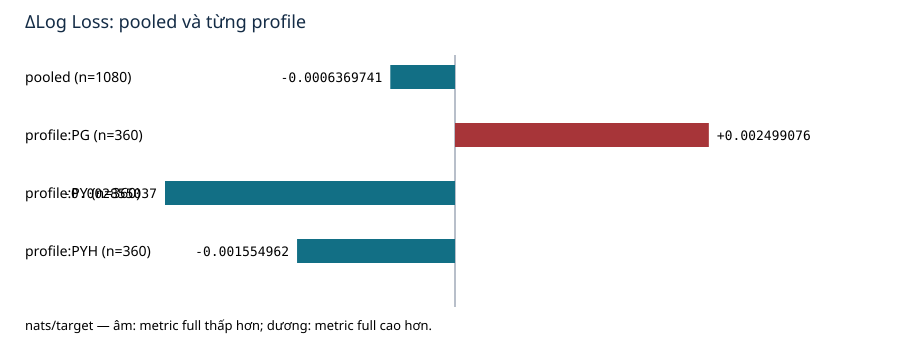

Context,n,ΔLL,ΔBrier,Preview đổi
pooled,1080,-0.000636974073,-0.00033867565,22
profile:PG,360,0.00249907633,0.00114140431,20
profile:PY,360,-0.00285503694,-0.00138648788,2
profile:PYH,360,-0.0015549616,-0.000770943372,0
seed:20000,360,-0.000932008857,-0.00046279805,0
seed:20001,360,-0.000550758359,-0.000283797527,17
seed:20002,360,-0.000428155001,-0.000269431373,5
trajectory:20000:PG,120,0.00206564641,0.000954399309,0
trajectory:20000:PY,120,-0.0035540477,-0.00170213657,0
trajectory:20000:PYH,120,-0.00130762528,-0.000640656885,0


Slice,Đường dẫn gốc,JSON Pointer
fixed_groups,research_tracking/runs/rq1-fixed-edge-set-contrast-20261108-01/summary.json,/groups


Kết quả: pooled nhỏ và không đồng nhất profile; PG có LL/Brier cao hơn empty. Không suy graph cải thiện học tập.


In [3]:
fixed = D['fixed_groups']
main = [r for r in fixed if r['group'] == 'pooled' or r['group'].startswith('profile:')]
table(['Nhóm','Target pairs','ΔLog Loss','ΔBrier','Preview đổi'],[(r['group'],r['paired_snapshot_targets'],r['LL_full_minus_empty'],r['Brier_full_minus_empty'],r['full_preview_tuple_changed']) for r in main])
p = fixed[0]
table(['P đổi','M classification đổi/event','Ready set đổi/event','Full preview đổi','Mẫu số'],[(p['P_changed'],p['M_event_changed'],p['R_event_changed'],p['full_preview_tuple_changed'],p['paired_snapshot_targets'])])
table(['P đổi?','Preview đổi?','Số đếm','Mẫu số theo P'],[(r['P_changed'],r['full_preview_changed'],r['count'],r['conditional_denominator']) for r in p['P_preview_table']])
signed_bars('ΔLog Loss: pooled và từng profile', [r['group']+' (n='+str(r['paired_snapshot_targets'])+')' for r in main],[r['LL_full_minus_empty'] for r in main],'nats/target')
table(['Context','n','ΔLL','ΔBrier','Preview đổi'],[(r['group'],r['paired_snapshot_targets'],r['LL_full_minus_empty'],r['Brier_full_minus_empty'],r['full_preview_tuple_changed']) for r in fixed], 'Đủ16contexts, giữ cả9trajectories và dấu ngược', True)
print('Kết quả: pooled nhỏ và không đồng nhất profile; PG có LL/Brier cao hơn empty. Không suy graph cải thiện học tập.')
source_note('fixed_groups')


In [4]:
table(['Actual cached-analysis argv (readonly provenance)'],[(json.dumps(D['fixed_analysis_command'],ensure_ascii=False),)])
print('Source/input unchanged:',D['fixed_analysis_unchanged'])


Actual cached-analysis argv (readonly provenance)
"[""D:\\Dev\\KLTN\\.venv\\Scripts\\python.exe"", ""-B"", ""D:\\Dev\\KLTN\\artifacts\\akt\\local-tests\\retention-metric-separation-20261108-01\\analyze_full_empty_fixed.py"", ""--plan-sha256"", ""958506ddea4904024683ce43047aee9bf596116f47997c8866d14053922f2bcd""]"


Source/input unchanged: True


## RQ2 — Khi nào thông tin đồ thị hữu ích hoặc bất lợi?

Hai paper mới xét một số bản đồ, hồ sơ và quy tắc lựa chọn cụ thể. Đề cương KLTN yêu cầu đi xa hơn: chất lượng quan hệ, lượng lịch sử bài làm và đặc điểm người học có làm kết quả thay đổi không? Các nhánh dưới đây kiểm từng điều kiện và cả nguy cơ cách thiết kế thí nghiệm làm ta hiểu sai kết quả.

**Trước hết là lịch sử.** Khi hệ thống biết ít về một người học, thông tin kiến thức nền có thể có vai trò khác khi đã thấy nhiều bài làm. Thay vì chỉ so hai nhóm người khác nhau, nhóm giữ cùng tình huống và cho hệ thống xem lượng quá khứ khác nhau. Các trường hợp dùng đủ lịch sử phải khớp đầu ra gốc trước; nếu không, phép rút ngắn sẽ không có đối chứng đáng tin.

<details><summary>Thiết kế và hồ sơ kiểm chứng — mở khi cần xem chi tiết</summary>

### K2 — Can thiệp lịch sử toàn policy

**Loại bằng chứng:** Controlled native replay, không teacher outcome mới; các native GAM state updates vẫn là model calls.

**Câu hỏi/giả thuyết được kiểm:** Trên CÙNG target, last10/last50/full available records làm graph contrast/preview đổi ra sao?

| Thiết kế | Nội dung |
|---|---|
| Treatment/control | Full và empty estimator tại cùngH; mỗi arm còn có window−full-history control. |
| Giữ cố định | 27cached targets tạiHpast10/50/100; currentquery/y/time; RNG không draw; G_env/G_controller source giữ nguyên. |
| Chủ động thay đổi | History cấp cho cả estimator và controller visits/question counts/recent/chapter; L=min(k,H). |

**Quá trình thí nghiệm gốc — không phải các cell Run All:**
1. Pin cached legacy/query sidecars và worker/plan.
2. Dựng54full-prefix controls, so exactP/S28/M/R/full-preview TRƯỚC truncated phase.
3. Replay retained prior records bằng native predict→cachedy→update và literal bookkeeping.
4. Probe target/preview readonly; lưu108arm endpoints/54unique target-window pairs.
5. Analysis freeze trước effect estimates; giữ144cells và81nominal aliases, không pool alias thành samples.

**Kiểm tính hợp lệ:** Full-prefix parity54/54; unchanged input SHA/counters; owned cleanup accepted. Full-prefix endpoint parity không chứng minh mọi hidden state snapshot giống lịch sử.

**Được phép kết luận:** Graph/history response không đơn điệu trong các targets đã chọn; rút history có thể đổi preview cảhai arms.

**Giới hạn/chưa xử lý:** Không KT-only memory intervention, không learning/ability effect. H khác nhau là target/y khác nhau; không soH10→H100 như cùngtarget. Preview chưa served;0independentseed mới.

**Mở protocol, code, receipt/log trong checkout:** [native plan](../../../../research_tracking/runs/rq1-history-availability-20261108-02/source__history_availability_plan02.json) · [native worker](../../../../research_tracking/runs/rq1-history-availability-20261108-02/source__history_availability_worker02.py) · [control checks](../../../../research_tracking/runs/rq1-history-availability-20261108-02/native__control_parity.json) · [actual receipt](../../../../research_tracking/runs/rq1-history-availability-20261108-02/native__run.json) · [native stdout](../../../../research_tracking/runs/rq1-history-availability-20261108-02/native__owned-launch__stdout.log) · [analysis recipe](../../../../research_tracking/runs/rq1-history-availability-20261108-02/analysis__recipe.md) · [cached analyzer](../../../../research_tracking/runs/rq1-history-availability-20261108-02/analysis__analyzer.py). Các link không được tải khi Run All; nếu chỉ mở file riêng trên Colab, dùng paths/SHA/pointers ở cuối để tra repository.


</details>

**Đọc bảng và biểu đồ:** so những cột thuộc cùng thời điểm/tình huống để xem tác động thay đổi thế nào khi bớt lịch sử. Không đọc các thời điểm khác nhau như cùng một người được can thiệp thêm thời gian học. Phép kiểm còn thay bộ ghi nhớ của phần chọn bài, nên chưa cô lập riêng bộ nhớ KT.


Targets,Unique target-window pairs,Native arms,Exact full-prefix controls,Nominal alias pairs
27,54,108,54,81


H,Nominal k,Actual L,n,Δp,ΔLLgraph,ΔBriergraph,Graph preview đổi,Window preview full E,Window preview empty E
10,10,10,9,-0.00656429367,-0.00651630521,-0.00331553507,0,0,0
10,50,10,9,-0.00656429367,-0.00651630521,-0.00331553507,0,0,0
10,full,10,9,-0.00656429367,-0.00651630521,-0.00331553507,0,0,0
50,10,10,9,-0.00259437093,0.00266614191,0.00127455656,0,6,6
50,50,50,9,-0.00488266986,0.00528442581,0.00257548406,0,0,0
50,full,50,9,-0.00488266986,0.00528442581,0.00257548406,0,0,0
100,10,10,9,-0.00492879869,0.00640588395,0.00313223024,0,8,8
100,50,50,9,-0.00504747244,0.00757338507,0.00369236259,2,6,8
100,full,100,9,-0.00246102073,0.005780258,0.00267129208,0,0,0


Profile,H,Nominal k,Actual L,n,Δp,ΔLLgraph,ΔBriergraph,Graph preview đổi,Window preview full E,Window preview empty E
profile:PG,10,10,10,3,-0.00754926631,0.00394663485,0.00155906733,0,0,0
profile:PG,10,50,10,3,-0.00754926631,0.00394663485,0.00155906733,0,0,0
profile:PG,10,full,10,3,-0.00754926631,0.00394663485,0.00155906733,0,0,0
profile:PG,50,10,10,3,-0.00303487319,0.00526620036,0.00256211362,0,2,2
profile:PG,50,50,50,3,-0.00309356536,0.0047361553,0.0021446555,0,0,0
profile:PG,50,full,50,3,-0.00309356536,0.0047361553,0.0021446555,0,0,0
profile:PG,100,10,10,3,-0.0037843295,0.00908641144,0.00438301402,0,2,2
profile:PG,100,50,50,3,-0.00345674387,0.00769290783,0.00367964828,0,2,2
profile:PG,100,full,100,3,0.000584012904,-0.00166418791,-0.000872972775,0,0,0
profile:PY,10,10,10,3,-0.00607180735,-0.0132635298,-0.00641106171,0,0,0


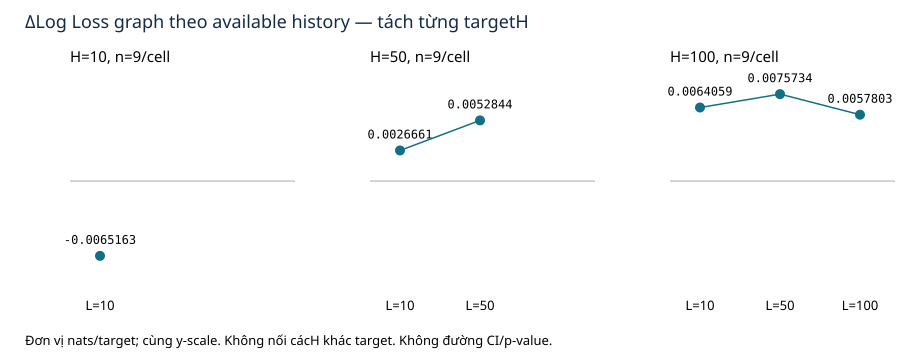

Context,H,Nominal k,Actual L,n,Δp,ΔLLgraph,ΔBriergraph,Graph preview đổi,Window preview full E,Window preview empty E
pooled,10,10,10,9,-0.00656429367,-0.00651630521,-0.00331553507,0,0,0
pooled,10,50,10,9,-0.00656429367,-0.00651630521,-0.00331553507,0,0,0
pooled,10,full,10,9,-0.00656429367,-0.00651630521,-0.00331553507,0,0,0
pooled,50,10,10,9,-0.00259437093,0.00266614191,0.00127455656,0,6,6
pooled,50,50,50,9,-0.00488266986,0.00528442581,0.00257548406,0,0,0
pooled,50,full,50,9,-0.00488266986,0.00528442581,0.00257548406,0,0,0
pooled,100,10,10,9,-0.00492879869,0.00640588395,0.00313223024,0,8,8
pooled,100,50,50,9,-0.00504747244,0.00757338507,0.00369236259,2,6,8
pooled,100,full,100,9,-0.00246102073,0.005780258,0.00267129208,0,0,0
profile:PG,10,10,10,3,-0.00754926631,0.00394663485,0.00155906733,0,0,0


Slice,Đường dẫn gốc,JSON Pointer
history_groups,research_tracking/runs/rq1-history-availability-20261108-02/analysis__summary.json,/groups
history_aliases,research_tracking/runs/rq1-history-availability-20261108-02/analysis__summary.json,/aliases
history_controls,research_tracking/runs/rq1-history-availability-20261108-02/native__control_parity.json,(root)


H100/L50: graph preview đổi2/9 so full-history0/9. Window đổi preview6–8/9 ở cảhai arms.
ΔLLgraph không đơn điệu theoL. PYH H100 có window−full LL âm: không kết luận full history luôn tốt hơn.


In [5]:
history = D['history_groups']; pooled=[r for r in history if r['context']=='pooled']
control=D['history_controls']
table(['Targets','Unique target-window pairs','Native arms','Exact full-prefix controls','Nominal alias pairs'],[(D['history_unique_targets'],D['history_unique_native_target_window_pairs'],D['history_native_endpoint_arms'],control['arms'],D['history_expanded_nominal_pairs_including_aliases'])])
headers=['H','Nominal k','Actual L','n','Δp','ΔLLgraph','ΔBriergraph','Graph preview đổi','Window preview full E','Window preview empty E']
def histrow(r):return (r['Hpast'],r['nominal_window'],r['available_length'],r['same_target_pairs'],r['mean_graph_delta_p'],r['mean_graph_delta_LL'],r['mean_graph_delta_Brier'],r['graph_full_preview_changed'],r['full_arm_preview_vs_full_history_changed'],r['empty_arm_preview_vs_full_history_changed'])
table(headers,[histrow(r) for r in pooled], 'Pooled; giữ aliases rõ ràng, không pool chúng thành mẫu mới')
profiles=[r for r in history if r['context'].startswith('profile:')]
table(['Profile']+headers,[(r['context'],)+histrow(r) for r in profiles], 'Cả3profiles; n=3target pairs/cell', True)
# Ba panels táchH; chỉ vẽ mỗi actual L một lần để tránh aliases thành repeated evidence.
selected=[]
for H in (10,50,100):
    bylength={}
    for r in pooled:
        if r['Hpast']==H:bylength[r['available_length']]=r
    selected.append((H,[bylength[L] for L in sorted(bylength)]))
ymin=min(r['mean_graph_delta_LL'] for _,rs in selected for r in rs); ymax=max(r['mean_graph_delta_LL'] for _,rs in selected for r in rs)
pad=(ymax-ymin)*.18 or .001; ymin-=pad;ymax+=pad
s=svg_open('ΔLog Loss graph theo available history — tách từng targetH','Mỗi panel có target riêng. Không CI. Alias không vẽ lặp.',920,360)
for panel,(H,rs) in enumerate(selected):
    x0=70+panel*300; y=lambda v:285-(v-ymin)/(ymax-ymin)*220
    s+='<text x="%s" y="62" font-size="15" font-family="sans-serif">H=%s, n=9/cell</text>'%(x0,H)
    s+='<line x1="%s" y1="%s" x2="%s" y2="%s" stroke="#aaa"/>'%(x0,y(0),x0+225,y(0))
    points=[]
    for i,r in enumerate(rs):
        x=x0+30+i*80; yy=y(r['mean_graph_delta_LL']);points.append('%s,%s'%(x,yy))
        s+='<circle cx="%s" cy="%s" r="5" fill="#126f85"/><text x="%s" y="%s" text-anchor="middle" font-size="12" font-family="monospace">%s</text><text x="%s" y="310" text-anchor="middle" font-size="13" font-family="sans-serif">L=%s</text>'%(x,yy,x,yy-12,format(r['mean_graph_delta_LL'],'.5g'),x,r['available_length'])
    s+='<polyline points="%s" fill="none" stroke="#126f85" stroke-width="1.5"/>'%' '.join(points)
s+='<text x="25" y="345" font-size="13" font-family="sans-serif">Đơn vị nats/target; cùng y-scale. Không nối cácH khác target. Không đường CI/p-value.</text></svg>'
emit('image/svg+xml',s)
table(['Context']+headers,[(r['context'],)+histrow(r) for r in history], 'Đủ144cells; không loại nhóm âm hoặc aliases', True)
print('H100/L50: graph preview đổi2/9 so full-history0/9. Window đổi preview6–8/9 ở cảhai arms.')
print('ΔLLgraph không đơn điệu theoL. PYH H100 có window−full LL âm: không kết luận full history luôn tốt hơn.')
source_note('history_groups','history_aliases','history_controls')


In [6]:
table(['Worker arguments from actual dispatch record'],[(json.dumps(D['history_worker_args'],ensure_ascii=False),)])
print('Actual status:',D['history_worker_status'],'; native state updates count as model calls:',D['history_model_update_scope'])


Worker arguments from actual dispatch record
"[""--plan-sha256"", ""0233926ae1ac2cc104c82641ecfb647f2e9f2aa81d96fb8b0aed589535aebcbc"", ""--remaining-seconds"", ""52.7674366000792""]"


Actual status: ACCEPTED_ONE_NATIVE_HISTORY_AVAILABILITY_REPLAY ; native state updates count as model calls: True


### Kiểm xem lộ trình ít quay lại chương đến từ đâu

Paper 1 đã quy việc không quay lại chương trong các lượt thử cho chính sách ưu tiên tính liên tục; đây không phải nhận định mới của KLTN. Bước kiểm hiện tại hỏi hẹp hơn: quy tắc trong bản mã đang có có bảo đảm điều đó ở mọi tình huống hay không?

Nhóm dựng một kịch bản nhỏ để kiểm quy tắc. Vì chưa xác minh được đúng revision mã tạo ra PDF, phản ví dụ trên bản mã hiện có không được dùng để bác bỏ kết quả paper.

<details><summary>Thiết kế và hồ sơ kiểm chứng — mở khi cần xem chi tiết</summary>

### K3a — Chapter continuity có phải bảo đảm của controller?

**Loại bằng chứng:** Source-level counterexample trên revision hiện có; không exact Paper1 PDF reproduction.

**Câu hỏi/giả thuyết được kiểm:** Một selector có bảo đảm không quay lại chapter trên mọi graph hay không?

| Thiết kế | Nội dung |
|---|---|
| Treatment/control | Hai chiến lược lowest_elo/cross_chapter_unlock trên cùng synthetic DAG và scripted mastery transitions. |
| Giữ cố định | Source selector/cell/notebook hash, đồ thị/kịch bản mastery; không chọn nhiều seeds để tìm route đẹp. |
| Chủ động thay đổi | Chiến lược controller; mastery transitions là ngoại sinh dựng sẵn, không quỹ đạo học sinh thật. |

**Quá trình thí nghiệm gốc — không phải các cell Run All:**
1. Reconcile notebook/PDF/source/manifest trong phạm vi local đã audit.
2. Dùng selector revision hiện có trên DAG nhỏ với mastery script đã khai báo.
3. Ghi concept/chapter route và re-entry.
4. Tách kết luận counterexample khỏi khả năng tái lập bảng của PDF.

**Kiểm tính hợp lệ:** Artifact giữ notebookSHA/selectorSHA/cell và route; audit không tìm exact submitted source+inputs+outputs trong phạm vi đã tìm, không chứng minh bản đúng không tồn tại nơi khác.

**Được phép kết luận:** A→B→A là counterexample cho bảo đảm phổ quát zero-reentry của revision đang xét.

**Giới hạn/chưa xử lý:** Không kết luận PDF sai, graph vô dụng hoặc route này xảy ra dưới mọi learner/policy; chưa giải quyết source revision gốc.

**Mở protocol, code, receipt/log trong checkout:** [actual counterexample](../../../../research_tracking/runs/cpu-rq12-20261107-03/paper1_counterexample.json) · [selector source excerpts](../../../../research_tracking/runs/paper1-revision-audit-20261107-01/paper1_source_cells.txt) · [revision audit](../../../../research_tracking/runs/paper1-revision-audit-20261107-01/paper1_revision_reconciliation_20261107.json) · [audit log](../../../../research_tracking/runs/paper1-revision-audit-20261107-01/audit_verification.log). Các link không được tải khi Run All; nếu chỉ mở file riêng trên Colab, dùng paths/SHA/pointers ở cuối để tra repository.


</details>

**Đọc kết quả:** một đường đi quay lại chương đủ bác bỏ bảo đảm phổ quát của revision được thử, nhưng không nói nó thường xảy ra hay kết quả PDF sai. Đây là kiểm giới hạn cách diễn giải một chỉ số lộ trình, chưa đo lợi ích học tập.


Selector,Concept route,Chapter route,Re-entry
cross_chapter_unlock,A1 → B1 → A2,A → B → A,1
lowest_elo,A1 → B1 → A2,A → B → A,1


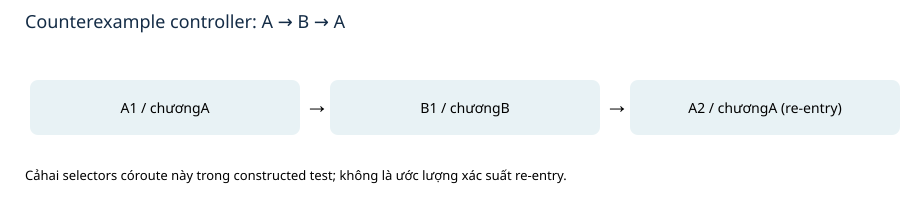

Slice,Đường dẫn gốc,JSON Pointer
chapter_counterexample,research_tracking/runs/cpu-rq12-20261107-03/paper1_counterexample.json,(root)
paper1_revision_verdict,research_tracking/runs/paper1-revision-audit-20261107-01/paper1_revision_reconciliation_20261107.json,/verdict


Source counterexample status: passed_source_counterexample ; revision audit: NO_EXACT_PAPER1_PDF_REVISION_FOUND_IN_SEARCHED_LOCAL_SCOPE


In [7]:
chapter=D['chapter_counterexample']
table(['Selector','Concept route','Chapter route','Re-entry'],[(name,' → '.join(r['concepts']),' → '.join(r['chapters']),r['chapter_reentries']) for name,r in chapter['routes'].items()])
print('Source counterexample status:',chapter['status'],'; revision audit:',D['paper1_revision_verdict'])
s=svg_open('Counterexample controller: A → B → A','Synthetic DAG và scripted mastery, không learning trajectory.',920,210)
for i,label in enumerate(('A1 / chươngA','B1 / chươngB','A2 / chươngA (re-entry)')):
    x=30+i*300;s+='<rect x="%s" y="80" width="270" height="55" rx="8" fill="#e8f2f5"/><text x="%s" y="113" text-anchor="middle" font-family="sans-serif" font-size="14">%s</text>'%(x,x+135,escape(label))
    if i<2:s+='<text x="%s" y="113" font-size="24">→</text>'%(x+275)
s+='<text x="25" y="180" font-family="sans-serif" font-size="13">Cảhai selectors córoute này trong constructed test; không là ước lượng xác suất re-entry.</text></svg>';emit('image/svg+xml',s)
source_note('chapter_counterexample','paper1_revision_verdict')


### Đo kiến thức giữ lại sau hai tuần có cho thêm thông tin không?

Mức giữ lại sau 14 ngày nghe như một khía cạnh khác với mức tiến bộ lúc kết thúc. Vì thế, nhóm kiểm công thức quên của mô phỏng trước khi dùng hai kết quả làm bằng chứng bổ sung. Trong điều kiện đã nêu, phần tăng ròng so với mức nền giảm theo cùng một tỷ lệ sau khi ngừng luyện; thứ hạng theo hai số đó sẽ giống nhau.

Điều này chỉ nối **tiến bộ ròng lúc kết thúc** với **tiến bộ ròng còn giữ lại**. Paper 2 còn đo phần học thêm tức thời, trước tác động quên về sau; đại lượng đó khác. Chưa thể kết luận hai kết quả chính của Paper 2 dư thừa. Nhóm cũng kiểm một cách đọc mức thành thạo phi tuyến để xem kết luận có phụ thuộc cách đo không.

<details><summary>Thiết kế và hồ sơ kiểm chứng — mở khi cần xem chi tiết</summary>

### K3b — Retention tuyến tính và soft-mastery phi tuyến

**Phân biệt bắt buộc với Paper2:** tại IV-A/trang4 của đúng PDF người dùng xác nhận, `G_learn` là trung bình các increment tức thời **gross**, trước forgetting; `G_net(T)` là net mean-theta so với base tại cuối lịch. Identity `G_ret(14)=exp(-0.84)*G_net(T)` **không** là identity với `G_learn`. Vì vậy kết quả này chưa chứng minh hai primary outcomes của Paper2 dư thừa/trùng nhau; chỉ giới hạn việc dùng final-net và retained-net như hai endpoint độc lập. Kết quả này cũng chưa giải thích được vì sao Paper2 không phát hiện khác biệt ở primary gross-learning-gain; cần giữ riêng gross gain, final net gain và retained net gain trong đánh giá tiếp theo.


**Loại bằng chứng:** Arithmetic source diagnostic + fixed constructed-state counterexample; không native trajectory/model execution.

**Câu hỏi/giả thuyết được kiểm:** Retention14 có luôn chỉ lặp lại ranking final gain? Điều đó phụ thuộc readout nào?

| Thiết kế | Nội dung |
|---|---|
| Treatment/control | Hai trạng tháiA/B cùng28base, đọc tạiT vàT+14; scalar net theta gain so soft/hard mastery readouts. |
| Giữ cố định | Fixedbase; nonnegative gain; no practice sauT; decay0.06/ngày; cùng hàm response/mastery nguồn. |
| Chủ động thay đổi | Cách phân bố gain của2states dựng sẵn và metric readout, không thay dynamics. |

**Quá trình thí nghiệm gốc — không phải các cell Run All:**
1. Đối chiếu AST/source equations và C08 cũ.
2. Suy c=exp(−0.06×14) cho net-theta gain.
3. Tính các readouts ở hai states đã chốt; không state search/tuning sau quan sát.
4. Kiểm zero-gain/identical-state/threshold và linear residual; ghi full28dimensions trong rawreadouts.

**Kiểm tính hợp lệ:** Linear residual<1e−12; oldC08 không đổi; source hash trước=sau; không thực thi native functions. Hard readout chỉ tie→A>B, không strict reversal.

**Được phép kết luận:** Retained net-theta redundant với final net-theta trong điều kiện này; soft readout có thể đảo ranking.

**Giới hạn/chưa xử lý:** Constructed states chưa chứng minh reachable từ persona/policy; không graph benefit, latent calibrated mastery hoặc độc lập thống kê của endpoints.

**Mở protocol, code, receipt/log trong checkout:** [fixed plan](../../../../research_tracking/runs/rq2-retention-readout-separation-20261108-01/plan.json) · [arithmetic code](../../../../research_tracking/runs/rq2-retention-readout-separation-20261108-01/analyze_readouts.py) · [equation source](../../../../research_tracking/runs/rq2-retention-readout-separation-20261108-01/source_excerpts.json) · [actual command/receipt](../../../../research_tracking/runs/rq2-retention-readout-separation-20261108-01/run.json) · [stdout](../../../../research_tracking/runs/rq2-retention-readout-separation-20261108-01/stdout.log) · [states/readouts/negative controls](../../../../research_tracking/runs/rq2-retention-readout-separation-20261108-01/readouts.json). Các link không được tải khi Run All; nếu chỉ mở file riêng trên Colab, dùng paths/SHA/pointers ở cuối để tra repository.


</details>

**Đọc bảng và hai đường bên dưới:** các trạng thái A/B được dựng để kiểm công thức, không phải kết quả hai mô hình đã huấn luyện. Đảo thứ hạng ở cách đọc khác chỉ chứng minh phải xét đúng đại lượng; chưa chứng minh lộ trình học nào tạo ra các trạng thái đó.


Decay/ngày,Retention days,Hệ số net gain,Sai số fixture
0.06,14,0.431710523,1.70530257e-13


Constructed state,Time,Mean theta net gain/Elo,Soft-mastery gain,Hard-mastered concepts
A,T,8.92857143,0.0118289301,1
A,D14,3.85455824,0.00550227502,1
B,T,16.0714286,0.0171626438,1
B,D14,6.93820484,0.00512052407,0


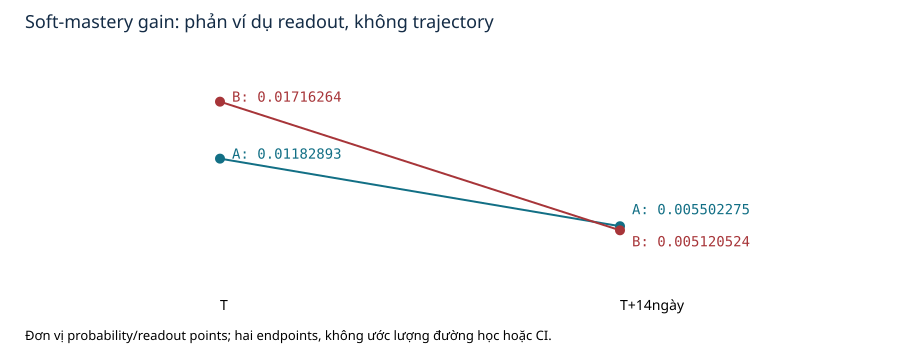

Slice,Đường dẫn gốc,JSON Pointer
retention_linear,research_tracking/runs/cpu-rq12-20261107-03/retention.json,(root)
retention_A_T,research_tracking/runs/rq2-retention-readout-separation-20261108-01/readouts.json,/states/A/T
retention_A_D14,research_tracking/runs/rq2-retention-readout-separation-20261108-01/readouts.json,/states/A/D14
retention_B_T,research_tracking/runs/rq2-retention-readout-separation-20261108-01/readouts.json,/states/B/T
retention_B_D14,research_tracking/runs/rq2-retention-readout-separation-20261108-01/readouts.json,/states/B/D14


Soft B>A tạiT nhưng A>B sau14ngày. Net mean-theta vẫn B>A. Hard: tie→A>B, không strict reversal.


In [8]:
linear=D['retention_linear']
table(['Decay/ngày','Retention days','Hệ số net gain','Sai số fixture'],[(linear['true_forget_rate'],linear['retention_days'],linear['scaling_factor'],linear['absolute_error'])])
readouts=[(state,phase,D['retention_'+state+'_'+phase]) for state in ('A','B') for phase in ('T','D14')]
table(['Constructed state','Time','Mean theta net gain/Elo','Soft-mastery gain','Hard-mastered concepts'],[(a,t,r['mean_theta_gain'],r['native_soft_mastery_gain'],r['native_hard_mastery_count']) for a,t,r in readouts])
s=svg_open('Soft-mastery gain: phản ví dụ readout, không trajectory','Chỉ hai time readouts của states dựng sẵn; không native simulation.',920,350)
top=max(r['native_soft_mastery_gain'] for _,_,r in readouts)*1.2
for state,color in (('A','#126f85'),('B','#a73539')):
    points=[]
    for i,t in enumerate(('T','D14')):
        v=D['retention_'+state+'_'+t]['native_soft_mastery_gain'];x=220+i*400;y=285-v/top*220;points.append('%s,%s'%(x,y))
        s+='<circle cx="%s" cy="%s" r="5" fill="%s"/><text x="%s" y="%s" font-size="14" font-family="monospace" fill="%s">%s: %s</text>'%(x,y,color,x+12,y+(-12 if i==1 and state=='A' else 16 if i==1 else 0),color,state,format(v,'.7g'))
    s+='<polyline points="%s" fill="none" stroke="%s" stroke-width="2"/>'%(' '.join(points),color)
s+='<text x="220" y="310" font-size="14" font-family="sans-serif">T</text><text x="620" y="310" font-size="14" font-family="sans-serif">T+14ngày</text><text x="25" y="340" font-size="13" font-family="sans-serif">Đơn vị probability/readout points; hai endpoints, không ước lượng đường học hoặc CI.</text></svg>'
emit('image/svg+xml',s)
print('Soft B>A tạiT nhưng A>B sau14ngày. Net mean-theta vẫn B>A. Hard: tie→A>B, không strict reversal.')
source_note('retention_linear','retention_A_T','retention_A_D14','retention_B_T','retention_B_D14')


In [9]:
table(['Negative control','Stored result'],list(D['retention_negative_controls'].items()))
table(['Actual arithmetic argv'],[(json.dumps(D['retention_command'],ensure_ascii=False),)])


Negative control,Stored result
identical_state_same_readout,True
threshold_readout_f1250_equals_half,True
zero_gain_all_readouts_gain_zero,True


Actual arithmetic argv
"[""D:\\Dev\\KLTN\\.venv\\Scripts\\python.exe"", ""-B"", ""D:\\Dev\\KLTN\\artifacts\\akt\\local-tests\\retention-metric-separation-20261108-01\\analyze_readouts.py"", ""--plan-sha256"", ""fed46bbfc3cecaccd60ca74298554d2ab9aa430627bb7ea2b2d653b229554179""]"


### Tách mức năng lực chung khỏi tác động của kiến thức tiên quyết

Một nhóm học tốt có thể làm tốt dù thông tin đồ thị có giúp hay không. Nếu đổi cả hồ sơ người học lẫn đồ thị, khác biệt kết quả dễ bị quy nhầm. Phép kiểm mới giữ cấu trúc mạnh/yếu giữa các khái niệm và chuỗi ngẫu nhiên chung, rồi thay mức năng lực chung và mức phạt khi thiếu kiến thức nền.

Câu hỏi là: khi làm cơ chế tiên quyết tác động mạnh hơn, lợi thế tương đối của cấu hình dùng đồ thị có lớn hơn không? Để trả lời, nhóm so chênh lệch có/không cạnh khi bật cơ chế đó với chênh lệch khi tắt. Đây là đối chứng có kiểm soát trong mô phỏng, chưa phải quy luật năng lực trên học sinh thật.

<details><summary>Thiết kế và hồ sơ kiểm chứng — mở khi cần xem chi tiết</summary>

### K4 — Scalar ability × prerequisite mechanism

**Loại bằng chứng:** New finite controlled simulator experiment; không population/human causal study.

**Câu hỏi/giả thuyết được kiểm:** Giữ residual để hỏi thay scalar ability/λ có luôn làm graph-relative gain tăng không?

| Thiết kế | Nội dung |
|---|---|
| Treatment/control | 3blocks21000–21002×a1000/1150/1300×full/empty estimator×λ0/0.55 =36worlds. |
| Giữ cố định | Mỗi block chung centered residual28chiều và U[120,2] theo step; model init1200; parent signal/adaptation bật, local adaptation tắt; fullG_env/G_controller. |
| Chủ động thay đổi | Ability scalar, estimator edge set, hệ số penalty world; residual gốc còn graph correlation. |

**Quá trình thí nghiệm gốc — không phải các cell Run All:**
1. Freeze protocol/36-cell plan trướcnative.
2. Generate chung một PYanchor/block, center/bound residual60 và freeze U bytes/SHA trước world đầu.
3. Thực hiện highλ paired controls theo thiết kế; giữ counters/cell reservations.
4. Native select→predict served→interact→update; chạy toàn36worlds/4320events.
5. Tính36Y/18Δ/9Ψ/6Ω và đọc raw độc lập bằng cached verifier, giữ mọi dấu.

**Kiểm tính hợp lệ:** Same residual/U provenance;6highλ-pairs exact720pairedpositions+6final states;4320reserved=attempted=returned; source/copy hashes; parent independent raw verifier. Telemetry không hard OSquota.

**Được phép kết luận:** Ψ không nhất quán dương; highΨ0 design-knownD0 nhưng graphΔ tạiλ0 vẫn dương, nên graph advantage không chỉ là penalty.

**Giới hạn/chưa xử lý:** 3reused blocks không36independent learners. U ghép theo step, không cùng question/y sau divergence; không pairedΔP trên khácquery, noCI/p-value/ability-population law.

**Mở protocol, code, receipt/log trong checkout:** [36cell plan](../../../../research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/plan.json) · [native code](../../../../research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/worker.py) · [prepared CLI—not sole execution proof](../../../../research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/proposed_cli.json) · [actual counters/receipt](../../../../research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/native__run.json) · [native stdout](../../../../research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/native__owned-launch__stdout.log) · [readonly verifier](../../../../research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/verify_saved_results.py) · [verification receipt](../../../../research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/independent_verification01.json). Các link không được tải khi Run All; nếu chỉ mở file riêng trên Colab, dùng paths/SHA/pointers ở cuối để tra repository.


</details>

**Đọc biểu đồ:** cột lớn hơn 0 mới là lợi thế tương đối tăng khi bật cơ chế phạt; không phải điểm thành tích tuyệt đối. Cột 0 ở nhóm cao đã được dự kiến vì các trạng thái đó không thiếu nền tảng theo cơ chế này. Nó không có nghĩa mọi ảnh hưởng của đồ thị đều bằng 0. Đơn vị Elo là thang trạng thái mô phỏng, không điểm kiểm tra.


a,Ψ21000,Ψ21001,Ψ21002,Mean3blocks
1000,0.00756099358,-0.051075962,0.0206208689,-0.00763136653
1150,-0.056351119,-0.0391146996,-0.0121345572,-0.0358667919
1300,0,0,0,0


Block,a,Y fullλ0,Y emptyλ0,Y fullλ.55,Y emptyλ.55,Δλ0,Δλ.55,Ψ
21000,1000,4.17246499,4.10060273,3.1828099,3.10338665,0.0718622619,0.0794232555,0.00756099358
21000,1150,13.0777502,13.5397028,12.9378012,13.4561049,-0.461952521,-0.51830364,-0.056351119
21000,1300,17.5836337,17.3409748,17.5836337,17.3409748,0.242658952,0.242658952,0
21001,1000,3.82557363,3.80955721,2.76449457,2.79955411,0.0160164207,-0.0350595413,-0.051075962
21001,1150,12.7456502,12.7639253,12.6154293,12.6728191,-0.018275078,-0.0573897776,-0.0391146996
21001,1300,17.6304173,17.575257,17.6304173,17.575257,0.0551602416,0.0551602416,0
21002,1000,3.96911422,3.92025316,3.02239432,2.95291239,0.0488610633,0.0694819322,0.0206208689
21002,1150,11.772161,12.6764092,11.7260523,12.6424351,-0.904248211,-0.916382769,-0.0121345572
21002,1300,17.8993595,17.8966381,17.8993595,17.8966381,0.00272139895,0.00272139895,0


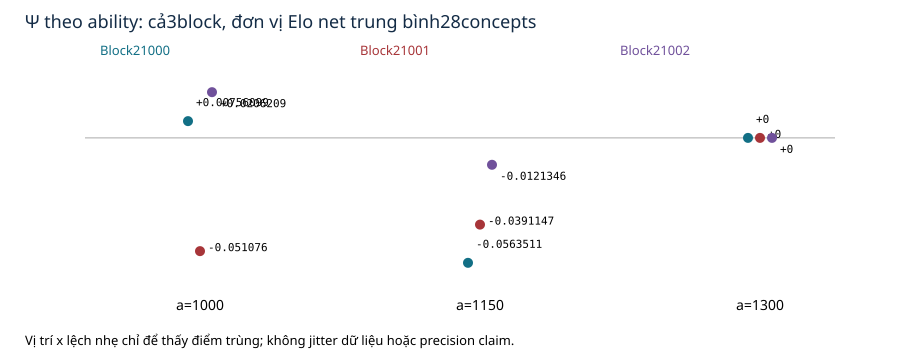

Block,a thấp,a cao,Ω/Elo
21000,1000,1150,-0.0639121126
21000,1150,1300,0.056351119
21001,1000,1150,0.0119612624
21001,1150,1300,0.0391146996
21002,1000,1150,-0.0327554261
21002,1150,1300,0.0121345572


Block,High a,Δgraph tại λ0
21000,1300,0.242658952
21001,1300,0.0551602416
21002,1300,0.00272139895


Slice,Đường dẫn gốc,JSON Pointer
ability_Y,research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/native__outcomes.json,(root)
ability_delta,research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/native__graph_deltas.json,(root)
ability_psi,research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/native__interactions.json,(root)
ability_omega,research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/native__ability_moderation.json,(root)
ability_summary,research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/native__summary.json,(root)
ability_controls,research_tracking/runs/rq2-controlled-ability-prerequisite-20261108-01/native__high_controls.json,(root)


a1000: Ψ +/−/+; a1150: −/−/− nhỏ. Sáuλ-pairs high khớp720events và6finalstates; knownD0.
Không quy mọi graph advantage cho true prerequisite mechanism; residual/controller/challenge/update paths còn lại.


In [10]:
ys=D['ability_Y']; keyed={(r['seed'],int(r['profile'][1:]),r['graph_on'],r['prerequisite_mechanism_on']):r['outcome'] for r in ys}
psis=D['ability_psi']; deltas=D['ability_delta']
table(['a','Ψ21000','Ψ21001','Ψ21002','Mean3blocks'],[(a,)+tuple(next(r['interaction_contrast'] for r in psis if r['seed']==b and r['profile']=='A'+str(a)) for b in (21000,21001,21002))+(D['ability_summary']['abilities'][str(a)]['mean_interaction'],) for a in (1000,1150,1300)])
rows=[]
for b in (21000,21001,21002):
    for a in (1000,1150,1300):
        delta=lambda m:next(r['graph_delta'] for r in deltas if r['block']==b and r['ability']==a and r['mechanism_strength']==m)
        psi=next(r['interaction_contrast'] for r in psis if r['seed']==b and r['profile']=='A'+str(a))
        rows.append((b,a,keyed[(b,a,True,False)],keyed[(b,a,False,False)],keyed[(b,a,True,True)],keyed[(b,a,False,True)],delta(0),delta(.55),psi))
table(['Block','a','Y fullλ0','Y emptyλ0','Y fullλ.55','Y emptyλ.55','Δλ0','Δλ.55','Ψ'],rows,'Đủ36Y/18Δ/9Ψ: không bỏ block âm',True)
s=svg_open('Ψ theo ability: cả3block, đơn vị Elo net trung bình28concepts','Không CI, không independentN mới; high0 là known negative.',920,360)
values=[r['interaction_contrast'] for r in psis]; lo=min(values)-.01;hi=max(values)+.01;y=lambda v:285-(v-lo)/(hi-lo)*215
s+='<line x1="85" y1="%s" x2="835" y2="%s" stroke="#aaa"/>'%(y(0),y(0))
colors=['#126f85','#a73539','#70519b']
for i,a in enumerate((1000,1150,1300)):
    for j,b in enumerate((21000,21001,21002)):
        v=next(r['interaction_contrast'] for r in psis if r['seed']==b and r['profile']=='A'+str(a));x=200+i*280+(j-1)*12
        s+='<circle cx="%s" cy="%s" r="5" fill="%s"/><text x="%s" y="%s" font-size="11" font-family="monospace">%s</text>'%(x,y(v),colors[j],x+8,y(v)+(j-1)*15,format(v,'+.6g'))
    s+='<text x="%s" y="310" text-anchor="middle" font-size="14" font-family="sans-serif">a=%s</text>'%(200+i*280,a)
for j,b in enumerate((21000,21001,21002)):
    s+='<text x="%s" y="55" font-size="13" font-family="sans-serif" fill="%s">Block%s</text>'%(100+j*260,colors[j],b)
s+='<text x="25" y="345" font-size="13" font-family="sans-serif">Vị trí x lệch nhẹ chỉ để thấy điểm trùng; không jitter dữ liệu hoặc precision claim.</text></svg>'
emit('image/svg+xml',s)
table(['Block','a thấp','a cao','Ω/Elo'],[(r['block'],r['ability_low'],r['ability_high'],r['interaction_difference']) for r in D['ability_omega']], 'Đủ6ability-moderation contrasts',True)
table(['Block','High a','Δgraph tại λ0'],[(r['block'],r['ability'],r['graph_delta']) for r in deltas if r['ability']==1300 and r['mechanism_strength']==0], 'HighΨ0 nhưng graphΔλ0 vẫn dương cả3blocks')
print('a1000: Ψ +/−/+; a1150: −/−/− nhỏ. Sáuλ-pairs high khớp720events và6finalstates; knownD0.')
print('Không quy mọi graph advantage cho true prerequisite mechanism; residual/controller/challenge/update paths còn lại.')
source_note('ability_Y','ability_delta','ability_psi','ability_omega','ability_summary','ability_controls')


In [11]:
table(['Actual operation','Count'],list(D['ability_actual_calls'].items()))
print('Actual acceptance:',D['ability_actual_status'])
table(['Prepared CLI (historical proposal; actualreceipt/counters separately shown)'],[(json.dumps(D['ability_proposed_cli'],ensure_ascii=False),)])


Actual operation,Count
anchor_generation,3
environment_constructor,36
interact,4320
oracle_probability_probe,4320
oracle_theta_probe,4320
policy_builder,36
predict,4320
select,4320
snapshot,36
uniform_array_generation,3


Prepared CLI (historical proposal; actualreceipt/counters separately shown)
"[""D:\\Dev\\KLTN\\.venv\\Scripts\\python.exe"", ""-B"", ""D:\\Dev\\KLTN\\artifacts\\akt\\local-tests\\controlled-ability-20261108-01\\run_once.py"", ""--plan-sha256"", ""fce29998c3a94c8c1a499fc43ff9e8aed77f68d62544de82bd4c3d9d66d15c72"", ""--approval-reference"", ""root-reviewed-controlled-ability-one60-20261108""]"


Actual acceptance: ACCEPTED_FINITE_CONTROLLED_ABILITY_PREREQUISITE_EXPERIMENT


### Trên Junyi, khớp thứ tự bài làm có đồng nghĩa đồ thị tốt không?

Người học Junyi có thể đã làm bài theo thứ tự chịu ảnh hưởng của bản đồ kiến thức. Vì vậy, thấy một nội dung xuất hiện trước nội dung khác không đủ chứng minh quan hệ tiên quyết giữa chúng hoặc lợi ích giảng dạy của quan hệ ấy.

Nhóm so đồ thị với các bản thay đổi có kiểm soát và giữ rõ ai thực sự được quan sát trong phép so sánh. Nếu số trường hợp tính tỷ lệ thay đổi, tỷ lệ cao hơn có thể không đi cùng nhiều trường hợp phù hợp hơn. Kiểm này nhằm tránh gán sự khác nhau của tập dữ liệu cho chất lượng đồ thị.

<details><summary>Thiết kế và hồ sơ kiểm chứng — mở khi cần xem chi tiết</summary>

### K5 — Junyi: order confounding và denominator sensitivity

**Loại bằng chứng:** Observed logged-order/graph-controls + cached common-population reanalysis; không causal sequencing study.

**Câu hỏi/giả thuyết được kiểm:** Graph khớp thứ tự luyện đã ghi có được hiểu như prerequisite/learning benefit không?

| Thiết kế | Nội dung |
|---|---|
| Treatment/control | Corrected976edge graph so3controls:20removed+20added=40symmetric-difference entries; raw979edge reference giữ riêng. |
| Giữ cố định | Stored Development inner-train cohort256learners/12,575events;≤300events/learner; timestamp/source-row order; degree/topic/support constraints. |
| Chủ động thay đổi | Parent sets ở controls và estimand/denominator: pair-weighted vs fixed learner-weighted vs common-coobserved subsets. |

**Quá trình thí nghiệm gốc — không phải các cell Run All:**
1. Chốt cohort/graph corrections và controls; source analysis không dùng Holdout để chọn.
2. Đo first-exposure parent-first alignment trên co-observed edge–learner pairs.
3. Kiểm bao nhiêu changed entries thực sự co-observed trong cùng learner.
4. Giữ cùng learner–child opportunities, dùng incomingdegree làm denominator, childmean rồi equal learnerweight.
5. Báo common-coobserved attrition và sensitivity; không pool các denominator thành cùngquầnthể.

**Kiểm tính hợp lệ:** Stored source/control/common-population SHA checked; exact aggregate denominators và sign examples được giữ. Common subset cần ít nhất1parent co-observed trong MỖI graph, không nhất thiết cùngparent.

**Được phép kết luận:** Dấu contrast phụ thuộc population/weights; order association có thể lẫn exposure và logged policy.

**Giới hạn/chưa xử lý:** Chỉ cachedaggregates trongnotebook, không mở raw Junyi/correctness/Holdout. Matching không bảo đảm co-observation; zero commoncontrast không equivalence; không causal instructional benefit.

**Mở protocol, code, receipt/log trong checkout:** [cached analysis code](../../../../research_tracking/runs/rq2-conditions-evidence-20261108-01/analysis_source.py) · [denominators/controls](../../../../research_tracking/runs/rq2-conditions-evidence-20261108-01/conditions.json) · [selected input hashes](../../../../research_tracking/runs/rq2-conditions-evidence-20261108-01/manifest.json) · [archive log—not original experiment trace](../../../../research_tracking/runs/rq2-conditions-evidence-20261108-01/execution.log). Các link không được tải khi Run All; nếu chỉ mở file riêng trên Colab, dùng paths/SHA/pointers ở cuối để tra repository.


</details>

**Đọc các bảng:** cần nhìn cả số trường hợp phù hợp và tổng trường hợp được tính. Các cột dùng trọng số/quần thể khác nhau trả lời các câu hỏi khác nhau; không chọn riêng cột có kết quả thuận lợi. Đây là phân tích thứ tự đã ghi, không phải thí nghiệm cho học sinh học theo hai đồ thị.


In [12]:
controls=D['junyi_controls']; common=D['junyi_common_population_sensitivity']; base=D['junyi_corrected_base']
table(['Graph','Parent-first pairs','Co-observed pairs','Pair-weighted rate'],[('Corrected base',base['parent_first_pairs'],base['coobserved_edge_learner_pairs'],base['pair_weighted_parent_first_fraction'])]+[('Control'+str(r['seed']),r['control']['parent_first_pairs'],r['control']['coobserved_edge_learner_pairs'],r['control']['pair_weighted_parent_first_fraction']) for r in controls])
table(['Control','Removed edges','Symmetric-diff entries','Changed entries same-learner co-observed','Δpair-rate','Δfixed-learner prior','Δcommon prior','Common learners/eligible'],[(r['seed'],r['removed']['edges'],r['symmetric_difference_entries'],r['changed_entries_coobserved_same_learner'],r['delta_pair_weighted_fraction'],c['all_fixed']['categories']['observed_prior_fraction']['delta_control_minus_base'],c['common_coobserved']['categories']['observed_prior_fraction']['delta_control_minus_base'],str(c['common_coobserved']['learners'])+'/'+str(c['eligible_learners'])) for r,c in zip(controls,common)])
print('Control2: parent-first count−1, denominator−4 → pooled rate tăng; fixed-learner contrast âm, common0.')
print('Các estimands khác nhau, không arithmetic contradiction hoặc causal graph benefit. Không bootstrap/CI từ aggregate means.')
source_note('junyi_corrected_base','junyi_controls','junyi_common_population_sensitivity')


Graph,Parent-first pairs,Co-observed pairs,Pair-weighted rate
Corrected base,575,649,0.885978428
Control0,576,650,0.886153846
Control1,568,644,0.881987578
Control2,574,645,0.889922481


Control,Removed edges,Symmetric-diff entries,Changed entries same-learner co-observed,Δpair-rate,Δfixed-learner prior,Δcommon prior,Common learners/eligible
0,20,40,2,0.000175417803,0.00069735007,0,96/239
1,20,40,10,-0.00399085071,-0.00117904456,-0.00308261846,96/239
2,20,40,6,0.00394405227,-0.000836820084,0,95/239


Slice,Đường dẫn gốc,JSON Pointer
junyi_corrected_base,research_tracking/runs/rq2-conditions-evidence-20261108-01/conditions.json,/junyi/corrected_base
junyi_controls,research_tracking/runs/rq2-conditions-evidence-20261108-01/conditions.json,/junyi/controls
junyi_common_population_sensitivity,research_tracking/runs/rq2-conditions-evidence-20261108-01/conditions.json,/junyi/common_population_sensitivity


Control2: parent-first count−1, denominator−4 → pooled rate tăng; fixed-learner contrast âm, common0.
Các estimands khác nhau, không arithmetic contradiction hoặc causal graph benefit. Không bootstrap/CI từ aggregate means.


Control,Changed entries,Actually co-observed entries
0,40,2
1,40,10
2,40,6


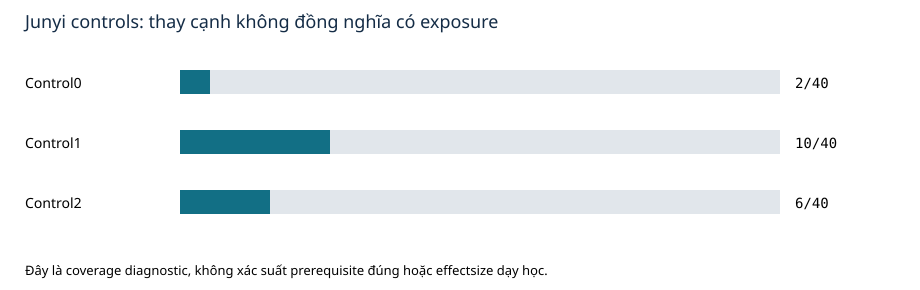

In [13]:
rows=[(str(r['seed']),r['symmetric_difference_entries'],r['changed_entries_coobserved_same_learner']) for r in D['junyi_controls']]
table(['Control','Changed entries','Actually co-observed entries'],rows)
s=svg_open('Junyi controls: thay cạnh không đồng nghĩa có exposure','Không rate chất lượng cạnh; mẫu số changed entries40/control.',920,290)
for i,(name,total,exposed) in enumerate(rows):
    y=70+i*60;s+='<text x="25" y="%s" font-family="sans-serif" font-size="14">Control%s</text><rect x="180" y="%s" width="600" height="24" fill="#e1e6eb"/><rect x="180" y="%s" width="%s" height="24" fill="#126f85"/><text x="795" y="%s" font-family="monospace" font-size="14">%s/%s</text>'%(y+18,name,y,y,600*exposed/total,y+18,exposed,total)
s+='<text x="25" y="275" font-family="sans-serif" font-size="13">Đây là coverage diagnostic, không xác suất prerequisite đúng hoặc effectsize dạy học.</text></svg>';emit('image/svg+xml',s)


## RQ3 — Có thể sử dụng đồ thị thận trọng hơn không?

Hai RQ trước dẫn tới giả thuyết giải pháp trong đề cương: không buộc hệ thống tin mọi quan hệ với cùng mức độ. CG-AKT sẽ điều chỉnh ảnh hưởng của thông tin tiên quyết dựa trên bằng chứng hỗ trợ và giữ phương án không dùng đồ thị khi chưa có bằng chứng phát triển đủ rõ. Đây là giả thuyết cần kiểm chứng, chưa phải kết luận các chẩn đoán đã chứng minh.

Muốn so sánh giải pháp, trước hết phải có dữ liệu và quy trình không lẫn vai trò học, chọn cấu hình và điều chỉnh mức tự tin. Bộ dữ liệu mô phỏng dưới đây phục vụ điều đó. Nó là đầu vào để thử nghiệm mô hình, không phải kết quả cho thấy CG-AKT có hiệu quả.

<details><summary>Thiết kế và hồ sơ kiểm chứng — mở khi cần xem chi tiết</summary>

### K6 — Corpus Development cho pipeline RQ3

**Loại bằng chứng:** Actual data collection/publication/typed-reader engineering; chưa fitted CG-AKT research result.

**Câu hỏi/giả thuyết được kiểm:** Có thể tạo một corpus observable role-aware đủ84items để sau này train/selection/refit/calibration đúnglineage không?

| Thiết kế | Nội dung |
|---|---|
| Treatment/control | Không contrast model ở batch này;48train/6selection/6calibration,210events/người;150final IDs chỉmetadata. |
| Giữ cố định | Pinned Paper2rawsource/graph/bank; rootseed42; profiles role-local16/2/2 mỗiPG/PY/PYH; UTC/gap6h; cùngrecipe qua roles. |
| Chủ động thay đổi | Fresh role/learner namespaces; logging uniform84items bằng behavior RNG riêng, không selector theo mastery/oracle. |

**Quá trình thí nghiệm gốc — không phải các cell Run All:**
1. Freeze plan/profile/caps/source/runtime và ownedprocess approval.
2. Collect chỉtrain/selection/calibration, durableattempt/return counters; no finalevents.
3. Serialize9publicinputs +oracle sidecars tách riêng, SHA/readback rồiDONElast.
4. Sharedreader chỉ mở9public+DONE, reconstruct typedplan/provenance, kiểmcounts/clock/rows/classes/support.
5. Independentcached QA và opaquehash inventory; không promote support thànhconfidence/modelquality.

**Kiểm tính hợp lệ:** Actual12,600attempts=returns;60learners disjoint,84items/role,2classes/role; source trước=sau/ownedcleanup accepted. HistoricalQA đã hashoracle opaque: giữaccesserratum, không giảneveropenedbytes.

**Được phép kết luận:** Đã có dữ liệu để nối researchpipeline; train coverage/strict-prior pair support là structural opportunity.

**Giới hạn/chưa xử lý:** Uniformlogging khônggraph-freeworld: teacher dynamics vẫncóG_env. ChưaNNfitted/refit/calibration/confidenceOOF/CG-AKT efficacy hoặc finaleval. Corpus support không chứng minh learner diversity.

**Mở protocol, code, receipt/log trong checkout:** [frozen collection config](../../../../research_tracking/runs/development-corpus-native-20261108-01/input-03__simulator-research-corpus01.json) · [actual driver](../../../../research_tracking/runs/development-corpus-native-20261108-01/input-06__run_native01.py) · [actual counts/receipt](../../../../research_tracking/runs/development-corpus-native-20261108-01/input-12__run.json) · [public roundtrip QA](../../../../research_tracking/runs/development-corpus-native-20261108-01/input-04__independent-verification01.json) · [access erratum](../../../../research_tracking/runs/development-corpus-native-20261108-01/input-16__structural_support01_access_erratum.json). Các link không được tải khi Run All; nếu chỉ mở file riêng trên Colab, dùng paths/SHA/pointers ở cuối để tra repository.


</details>

**Đọc bảng dữ liệu:** số người học, tương tác và độ phủ bài tập cho biết dữ liệu đã được chuẩn bị đến đâu. Chúng chưa cho biết mô hình dự báo hoặc chọn bài tốt. Đối chứng bắt buộc còn phải hoàn thành gồm AKT, SAKT, GKT, GAM-KT, Graph-GAM-KT, BKT tham chiếu; các phương án graph-free, AKT đồ thị cố định và CG-AKT; đồ thị chuyên gia, học từ dữ liệu, gây nhiễu và demo nghiên cứu. Danh sách này là phần việc tiếp theo, không phải kết quả đã chạy.


In [14]:
roles=D['corpus_roles']
table(['Role','Learners','Events','Label0','Label1','Covered items'],[(role,r['learners'],r['events'],r['class_counts']['0'],r['class_counts']['1'],r['covered_items']) for role,r in roles.items()])
table(['Actual attempts','Actual returns','Final events','Model calls','Modal USD','Canonical files','Canonical bytes'],[(D['corpus_actual_interact_attempts'],D['corpus_actual_interact_returns'],D['corpus_final_events'],D['corpus_model_calls'],D['corpus_modal_spend_usd'],D['corpus_canonical_files'],D['corpus_canonical_bytes'])])
table(['Coverage condition','Value'],list(D['corpus_support_coverage_only_not_oof_confidence'].items()))
print('Đã đạt: corpus/source/role/readback/cleanup. Chưa đạt: research-fitted NN, epoch-selection/refit/calibration, confidenceOOF, final evaluation.')
print('Notebook chỉ nhúng aggregate QA; không mở9model-input files hoặc7oracle files. QA lịch sử hashoracle opaque, không parse; access erratum giữ nguyên.')
source_note('corpus_roles','corpus_support_coverage_only_not_oof_confidence','corpus_actual_interact_attempts','corpus_status','corpus_access_erratum')


Role,Learners,Events,Label0,Label1,Covered items
calibration,6,1260,626,634,84
selection,6,1260,665,595,84
train,48,10080,5041,5039,84


Actual attempts,Actual returns,Final events,Model calls,Modal USD,Canonical files,Canonical bytes
12600,12600,0,0,0,17,6985213


Coverage condition,Value
min_train_learners_with_parent_strictly_before_child,45
min_train_unique_learners_per_concept,47
min_train_unique_learners_per_item,38
ordered_distinct_concept_pairs,756
pairs_supported_by_at_least20learners,756


Slice,Đường dẫn gốc,JSON Pointer
corpus_roles,research_tracking/runs/development-corpus-native-20261108-01/input-04__independent-verification01.json,/roles
corpus_support_coverage_only_not_oof_confidence,research_tracking/runs/development-corpus-native-20261108-01/input-04__independent-verification01.json,/support_coverage_only_not_oof_confidence
corpus_status,research_tracking/runs/development-corpus-native-20261108-01/input-12__run.json,/status
corpus_actual_interact_attempts,research_tracking/runs/development-corpus-native-20261108-01/input-12__run.json,/actual_interact_attempts
corpus_access_erratum,research_tracking/runs/development-corpus-native-20261108-01/input-16__structural_support01_access_erratum.json,(root)


Đã đạt: corpus/source/role/readback/cleanup. Chưa đạt: research-fitted NN, epoch-selection/refit/calibration, confidenceOOF, final evaluation.
Notebook chỉ nhúng aggregate QA; không mở9model-input files hoặc7oracle files. QA lịch sử hashoracle opaque, không parse; access erratum giữ nguyên.


## Đọc kết quả nào, còn thiếu gì?

K1–K5 là các chẩn đoán có nguồn và đối chứng, không thay bộ so sánh fitted modern models. K6 mới cung cấp dữ liệu. AKT/CG-AKT research-fitted, confidence OOF, main matrix selector trướcrefit, full-target calibration/evaluation và kết quả closed-loop với mô hình đó vẫn phải nghiệm thu riêng. Không gọi source/stub tests hoặc điểm AUC/LL của5hàng manufactured evaluator là kết quả AKT; không dùng các lượt Gate-partition thiếu finalJUnit/result như PASS.

Các protocol/code/log links cho phép kiểm tra quá trình, nhưng không mang dataset/checkpoint/rawlearners vào file. Một số `execution.log` chỉ log đóng gói; native receipt/stdout được ghi riêng trong từng mục, không dùng log đóng gói làm proof nativeexecution. Mã nguồn đúng revision tạo kết quả Paper1 PDF vẫn chưa tìm; rawC14statuspending là snapshot trướcclosureparentreview, không bị sửa lại.

**Chạy lại nghiên cứu gốc** còn cần đúng source/input/runtime/config/authorization/resource receipts và từng originalworker, không phải chỉ RunAll notebook. **RunAll ở đây** chỉ xác minh số học trên cachedslices và dựng lại output; không notebookkernel/Colabvisual acceptance, causal human efficacy, statistical confirmation hoặc RQcompletion.


In [15]:
# Kiểm số học cached, không simulation/replay/inference mới.
pool=D['fixed_groups'][0]
assert pool['P_changed']==963 and pool['paired_snapshot_targets']==1080
assert sum(r['count'] for r in pool['P_preview_table'])==1080
assert sum(r['count'] for r in pool['P_preview_table'] if r['full_preview_changed'])==22
assert D['history_controls']['arms']==54 and D['history_native_endpoint_arms']==108
assert D['chapter_counterexample']['routes']['lowest_elo']['chapter_reentries']==1
assert abs(D['retention_linear']['scaling_factor']-math.exp(-.06*14))<1e-12
for r in D['ability_psi']:
    a=int(r['profile'][1:]);b=r['seed']
    y=lambda g,m:next(q['outcome'] for q in D['ability_Y'] if q['seed']==b and q['profile']==r['profile'] and q['graph_on']==g and q['prerequisite_mechanism_on']==m)
    computed=(y(True,True)-y(False,True))-(y(True,False)-y(False,False))
    assert abs(computed-r['interaction_contrast'])<1e-12
for a in (1000,1150,1300):
    values=[r['interaction_contrast'] for r in D['ability_psi'] if r['profile']=='A'+str(a)]
    assert abs(math.fsum(values)/len(values)-D['ability_summary']['abilities'][str(a)]['mean_interaction'])<1e-12
assert sum(r['events'] for r in D['corpus_roles'].values())==12600
assert sum(r['learners'] for r in D['corpus_roles'].values())==60
assert D['corpus_final_events']==0
print('Cached arithmetic/denominator checks PASS; không additional independentN/model/teacher/CI/p-value.')


Cached arithmetic/denominator checks PASS; không additional independentN/model/teacher/CI/p-value.


## Hồ sơ đầy đủ để tra cứu nguồn

Mỗi numeric slice dưới có JSON Pointer, fileSHA và manifestSHA xác nhận selectedoutput khi dựng. Source inventory còn liệt kê protocol/code/receipt/log được dẫn; không có dữ liệu bí mật, Holdout hoặc checkpoint trongpayload. SHAembedded chỉ kiểm internalconsistency, không chữ ký hay sourceauthentication độc lập; file tựchứa không fetchrepo trênColab. Bản notebook trước0f2130…7620 được giữ nguyên ở externalprep; không sửa C01–C14/notebook nghiên cứu lịch sử.


In [16]:
table(['Slice ID','Source path','SHA-256','JSON Pointer'],[(r['id'],r['source_path'],r['source_sha256'],r['json_pointer'] or '(root)') for r in EVIDENCE['records']], 'Toàn bộ numeric slices và exactJSONPointers',True)
table(['Source/manifest','SHA-256','Bytes'],[(path,r['sha256'],r['bytes']) for path,r in EVIDENCE['source_inventory'].items()], 'Source inventory đã kiểm khi dựng',True)
print('Embedded payload SHA-256:',EXPECTED_EMBEDDED_SHA256)
print('RunAll chỉ render lại bảng/SVG từ giá trị đã lưu. Không fit/replay/teacher/newN/CI/p-value.')


Slice ID,Source path,SHA-256,JSON Pointer
fixed_groups,research_tracking/runs/rq1-fixed-edge-set-contrast-20261108-01/summary.json,bd9781570ec034aea5297dd63b1bef0075cfba5c5ee0a057c8df1887c27026f6,/groups
history_groups,research_tracking/runs/rq1-history-availability-20261108-02/analysis__summary.json,b87ea366950db108769f7df1c322870343779049da6108b70693e3af16b13d11,/groups
history_aliases,research_tracking/runs/rq1-history-availability-20261108-02/analysis__summary.json,b87ea366950db108769f7df1c322870343779049da6108b70693e3af16b13d11,/aliases
history_unique_targets,research_tracking/runs/rq1-history-availability-20261108-02/analysis__summary.json,b87ea366950db108769f7df1c322870343779049da6108b70693e3af16b13d11,/unique_targets
history_unique_native_target_window_pairs,research_tracking/runs/rq1-history-availability-20261108-02/analysis__summary.json,b87ea366950db108769f7df1c322870343779049da6108b70693e3af16b13d11,/unique_native_target_window_pairs
history_native_endpoint_arms,research_tracking/runs/rq1-history-availability-20261108-02/analysis__summary.json,b87ea366950db108769f7df1c322870343779049da6108b70693e3af16b13d11,/native_endpoint_arms
history_expanded_nominal_pairs_including_aliases,research_tracking/runs/rq1-history-availability-20261108-02/analysis__summary.json,b87ea366950db108769f7df1c322870343779049da6108b70693e3af16b13d11,/expanded_nominal_pairs_including_aliases
history_summary_rows,research_tracking/runs/rq1-history-availability-20261108-02/analysis__summary.json,b87ea366950db108769f7df1c322870343779049da6108b70693e3af16b13d11,/summary_rows
history_controls,research_tracking/runs/rq1-history-availability-20261108-02/native__control_parity.json,a3cbe3ef1431263e79aec0bb39d00b2f0d0ed74fe8564725d82b6aae311d1c5a,(root)
retention_linear,research_tracking/runs/cpu-rq12-20261107-03/retention.json,bd952fb707f04712508aa50def877d21da9ff71b1b0a5e9c74b4692d10645b54,(root)


Source/manifest,SHA-256,Bytes
docs/thesis_recovery/evidence/paper1.txt,b6d2d4a518a0b40f27c695bdde3ca624ce16ee976cb59151b15b85cee11eda85,23895
docs/thesis_recovery/evidence/paper2.txt,f545a26233f371154fd3d75ff6a7f48b44c11be0b222e6c37422385d3340f685,34298
docs/thesis_recovery/evidence/user_documents_20261108_inventory.json,1d8db121422c119b9d55eeb15ba4dce9c3bd24964a27bbcbd5211553cf12ed6d,2814
docs/thesis_recovery/evidence/user_documents_20261108_paper1.txt,d519b2c3d7a8e959706bdbae47b09bd29fc0d059d8b0dac02c2b4e30c7762cd8,23441
docs/thesis_recovery/evidence/user_documents_20261108_paper2.txt,f9dae002bbba6694d75cdea3c3331bdcabe58f74c3fb872c6ba4e1e9d33e92f9,33515
docs/thesis_recovery/evidence/user_documents_20261108_proposal.txt,69568a3669b70dc17976555d752b2aaf34122e07f8f586e194d95f4d7e894878,18875
paper1/Paper1_RIVF_2026_Graph_vs_Policy_Adaptive_Sequencing.pdf,984e2f825968c212ca7e76db23a4c9501659ed880ecff6dce437590ad49167f4,306318
paper2/DC KLTN0127 23520355&23521338_LeVanTuan.pdf,941e9c43e5bbd29075051debf6cdf81256c65b89e612d001e1a5377474b4836a,145844
paper2/Paper2_RIVF_2026_Prerequisite_Aware_Knowledge_Tracing.pdf,5a66195c620cc96604e770b993dde7711a0c40a7c0473fc4a15f715e757f5d07,370684
research_tracking/runs/cpu-rq12-20261107-03/manifest.json,6592a80768e6608355cde1fd545ee90f6ca4ec937b2284a1e3eb42fae4f766f0,2046


Embedded payload SHA-256: 55c08c1fbd7fa2c1e61c835283ea5ddb0c6ef60eb43b82089e6686a36af8fb57
RunAll chỉ render lại bảng/SVG từ giá trị đã lưu. Không fit/replay/teacher/newN/CI/p-value.
